# A 담당 AI 볼트·너트 검출: 전처리부터 학습·평가까지

| 항목 | 내용 |
|---|---|
| 작성 | 2026-11-23, A 작업 기록 #343 |
| 상태 | **A 검토 전 초안.** 커밋하지 않았습니다. |
| 대상 | 링크 카메라 영상에서 볼트·너트를 찾는 인스턴스 분할 모델(YOLO 계열) |
| 근거 | 저장소 파일(모델 카드, 분할 manifest, 학습·실행 설정)과 A 작업 기록(`_workspace/`, Git 제외) |

**읽는 법**

- 코드 셀은 **저장소에 있는 파일만** 읽습니다. 큰 데이터(`data/raw`·`data/derived`·`outputs/`)나 작업 기록에서 온 수치는 셀 안에 값으로 적고 출처(기록 번호·경로)를 함께 적었습니다.
- 그 파일들이 없어도 노트북은 끝까지 돕니다. `outputs/`가 있는 PC에서는 적어 둔 값과 원본을 대조한 결과도 출력합니다.
- 근거를 찾지 못한 값은 「미확인」으로 적었습니다.
- 그림 안의 글자는 영어입니다. 이 PC에 한글 글꼴이 없어서입니다. 설명은 그림 위아래 마크다운에 한국어로 적었습니다.
- 실행: 저장소의 `.venv` 또는 pandas·matplotlib가 있는 Python에서 위에서부터 차례로 실행합니다. GPU·Gazebo는 필요 없습니다.

In [1]:
# 준비: 저장소 루트를 찾고, 이 노트북에서 쓰는 도구를 정의한다.
import ast
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

try:
    display
except NameError:          # Jupyter 밖에서 실행할 때
    def display(obj):
        print(obj)

ROOT = Path.cwd()
while not (ROOT / "models" / "vision").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "models" / "vision").is_dir(), "저장소 루트를 찾지 못했습니다. 저장소 안에서 실행하세요."


def load_json(rel):
    # 저장소 상대 경로의 JSON을 읽는다. 없으면 None.
    p = ROOT / rel
    return json.loads(p.read_text(encoding="utf-8")) if p.is_file() else None


# 그림 색: 범주 3색(파랑·주황·청록, 색각 이상 검사 통과). 글자는 검은색.
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
print("저장소 루트:", ROOT.name, "| outputs/ 있음:", (ROOT / "outputs" / "training").is_dir())

저장소 루트: EyetoArm | outputs/ 있음: True


## 0. 실험 일지

AI·검출·데이터와 관련해 **실제로 한 실험·측정을 모두** 한 표에 모았습니다. 실패·중단한 실행, 준비만 하거나 계획만 세운 것도 상태와 함께 넣었습니다.

**읽는 법**

- **번호:** `M-`는 학습·분할 기본 실행입니다(이 보고서 작성 때 저장소 manifest·학습 요약에서 직접 적음). `E-`는 작업 기록 조사에서 옮긴 행입니다. 본문 절은 이 번호로 근거를 가리킵니다.
- **조사 방법:** 작업 기록 #114~#342(Git 제외 `_workspace/`)와 학습·평가 산출물(`outputs/training/*`, `outputs/pilot_640_1280`, `outputs/conf_sweep/*`)을 세 구간으로 나눠 훑었습니다. 수치는 원문 그대로 옮겼고, 원문에 없는 값은 「미확인」, 결론 문장이 없으면 「기록에 결론 없음」으로 적었습니다.
  - 조사 원본: `_workspace/343_k/survey_{A,B,C}.md`
  - 표 변환: `_workspace/343_k/parse_survey_343.py` → `experiment_log_343.json`
- **빈칸:** 원문 항목에 그 칸이 없으면 비웠습니다. 「같은 파일」은 바로 위 행과 같은 기록입니다.
- **#348~#353 행(S1-10 회전 실험):** 조사 원본을 거치지 않고 각 보고서와 원자료를 직접 대조해 적었습니다(#386). 판정에 쓴 값은 `docs/reports/data/s1_10_gate.json`에 원자료 경로·sha256과 함께 있습니다.
- **범위 밖:** TCP·GUI·ROS 연결, C 실행기·집기 동작, 물리 엔진만 다룬 기록은 넣지 않았습니다(조사 원본 끝에 기록별 사유).
- 표가 길어 구간별로 셀을 나눴습니다. 모두 한 표입니다(같은 열).
- **원문 대조:** E- 행 중 무작위 24행(시드 343)을 원문과 한 행씩 대조했습니다. 일치 23, 부분 불일치 1(E-173 기록 경로 오기, 고침)입니다. 불일치율은 1/24(4 %)이고, 수치 오류는 0건이었습니다. 정정은 `_workspace/343_k/corrections_343.json`으로 적용했고, 대조표는 `_workspace/343_k/verify_result_343.md`에 있습니다. 나머지 150행은 대조하지 않았습니다.

**행 수: 187개** (상태별: 완료 151, 계획만 12, 준비만 11, 중단 5, 기타·미기재 4, 실패 2, 부분 2)

#### 실험 일지 — 학습·분할 기본 실행(M-)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| M-01 | 2026-11-12 | #128 이전(A 상세 §12 데이터 분리 행) | 공개 분할의 장면 누수 제거(재분할 v1) | scripts/resplit_dataset.py 1.0, 회색조 32×32 상관 ≥ 0.95, 줄기 80/10/10, 시드 20261112 | train 2,809 / valid 161 / test 161장, 묶음 547(최대 286줄기), 분할 간 상관 ≥ 0.95 쌍 0 | 크기 분포가 쏠려(valid 너트 짧은 변 하위 5 % 25 px) v2로 대체 | 완료(대체됨) | data/splits/resplit_v1/manifest.json |
| M-02 | 2026-11-12 | A 상세 §12 | 크기 구간 균형을 더한 재분할 v2 | resplit_dataset 1.1, 크기 구간 <15/15~25/≥25 px, 가중치 줄기 4·클래스 1·크기 1 | train 2,772 / valid 162 / test 161장, 상관 ≥ 0.95 쌍 0, 재실행 목록 차이 0 | 현재 목록. 상관 0.80~0.95 쌍은 남음(점검용 test) | 완료 | data/splits/resplit_v2/manifest.json |
| M-03 | 2026-11-13 | A 상세 §7.1 | Gazebo 평가 세트 gz_eval_v1 수집 | scripts/gz_eval_scene.py·gz_eval_capture.py, 묶음 10 × 표본 20, 평가 시드 9,000,000번대 | 200장, 부품 663(BOLT_A=M6×12 204·BOLT_B 240·NUT 219), 2분 48초. 수집 중 스크립트 결함 2건(이전 /clock·브리지 메시지 잔류) 수정 | S1 후보 비교의 Gazebo 세트. S1-08 선택에 써서 이후 조정용 | 완료 | A 상세 §7.1 |
| M-04 | 2026-11-16 | outputs/training/s1_b64 | batch 64로 세 후보 재학습(S1-04~06) | config/training/s1_batch64_*.json, 그 밖은 S1-01~03과 같음 | gz1280 볼트 재현율 0.18 / 0.46 / 0.05(S1-01~03은 0.60 / 0.45 / 0.06) | Gazebo 성능이 나아지지 않음. batch16 대 64 차이 원인은 미확정(#128, E-128b) | 완료 | outputs/training/s1_b64/summary.md |
| M-05 | 2026-11-16 | #139 → outputs/training/s1_clean_r1 | 검수 통과 영상만으로 학습(S1-07) | yolov8n-seg, clean_train_r1, batch 16, hsv_v 기본 0.4 | 공개 test mAP50 0.563/0.558, gz1280 볼트 0.82·너트 0.97, gz1280 오검출 볼트 77 | Gazebo 재현율 크게 오름, 공개 test 떨어짐(원인 미확인) | 완료 | outputs/training/s1_clean_r1/summary.md |
| M-06 | 2026-11-16 | #141 → outputs/training/s1_clean_hsvv06_r1 | 밝기 증강 강화(S1-08) | S1-07과 같고 hsv_v 0.6만 바꿈 | 공개 test 0.554/0.546, gz1280 볼트 0.87·너트 0.97, BOLT_A/B 0.89/0.86, gz1280 오검출 볼트 136 | 후보 8개 중 Gazebo 볼트 재현율 최고(오검출도 최다 136) → 2026-11-21 운영 채택(A 결정) | 완료 | outputs/training/s1_clean_hsvv06_r1/summary.md, A 상세 §7.1 |

#### 실험 일지 — 기록 #114~#165와 학습·평가 산출물(파일럿·smoke·conf 스윕·라벨·수집·끝점) (1)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-P00a | 2026-11-12 | `outputs/pilot_640_1280/p640.log`, 설계서 §12 AI 비교 후보 행(1317행) | 640 학습 파일럿(p640): 공개 데이터 1단계 전이 학습 파일럿 | yolo11n-seg 공식 가중치, 재분할 v2(train 2772·val 162), imgsz 640, batch 16, workers 4(설계서), 50 epochs, seed 0, 기본 증강 | rc=0(`start.txt`), 「50 epochs completed in 0.198 hours」, RUN_INFO wall_s 726.7·max_gpu_mem_MiB 2707(설계서: 711 s, GPU 최대 2.7 GB). 최종 val: bolt P 0.972·R 0.84·mAP50(B) 0.918·mAP50(M) 0.899, nut mAP50(B) 0.985·(M) 0.985 | 설계서 「val mAP50 박스 0.952·마스크 0.941, test 0.951·0.891」 | 완료 | `p640.log` 끝부분, 설계서 1317행 |
| E-P00b | 2026-11-12 21:43~21:56 | `outputs/pilot_640_1280/start.txt`, `p1280_oom_try1/`, 설계서 1317행·30행 | 1280 첫 시도(p1280_oom_try1) — 메모리 부족: imgsz 1280 학습 비교 | imgsz 1280, batch 8, workers 4, 50 epochs | `start.txt` 「p1280 rc=137」. results.csv 3 에포크(4줄). 로그 끝 `EOFError`(dataloader). 설계서: 「3 에포크 뒤 WSL 시스템 메모리 부족(OOM)으로 종료」 | 설계서 1.9판 「1280은 메모리 부족으로 3 에포크에서 중단돼 비교 미완」 | 실패 | `start.txt`, `p1280_oom_try1.log`, 설계서 30·1317행 |
| E-P00c | 2026-11-12 22:00:16~22:01:11 | `start.txt`, `p1280.log`, `mem_watch.txt` | 1280 재시도(p1280) | imgsz 1280, batch 8(재시도 스크립트 `run_1280_retry.sh`) | 「p1280 retry rc=143 22:01:11」, 로그는 1/50 에포크 78%(273/347)에서 끝남. mem_watch 가용 메모리 9007496 → 5008760 kB(22:00:16→22:00:43) | 설계서 「그 뒤 두 번은 다른 세션 실행과 겹쳐 감시 규칙으로 중지」(재시도·r2·r3 중 어느 둘인지 원문 구분 없음) | 중단 | `start.txt`, `p1280.log` 끝 |
| E-P00d | 2026-11-12 22:57 / 23:21 | `r2_watch.txt`, `r3_watch.txt`, `run_1280_r2.sh`·`r3.sh` | 1280 r2·r3(감시 규칙 중지) | imgsz 1280, batch 8, workers 2. 감시: MemAvailable < 2 GiB이거나 gz sim·ax_ws 프로세스가 있으면 TERM | r2 「22:57:13 STOP reason: avail=4105384 other=5」, rc=143, max_group_rss_kB 18464684, results.csv 5 에포크(로그 6/50 에포크 중). r3 「23:21:31 STOP reason: avail=3995992 other=1」, rc=143, max_group_rss_kB 18274124, results.csv 3 에포크(로그 4/50 중) | 설계서 「다른 세션 실행과 겹쳐 감시 규칙으로 중지」 | 중단 | 두 watch 파일 끝 줄 |
| E-P00e | 2026-11-13 | `p1280_r4.log`, `r4_watch.txt`, 설계서 32·1317행 | 1280 r4(완주) | imgsz 1280, batch 8, workers 2, 50 epochs, 「메모리만 감시하는 A 결정 규칙」 | 「50 epochs completed in 0.502 hours」, RUN_INFO wall_s 1819.3·max_gpu_mem_MiB 5927, rc=0, max_group_rss_kB 20206232. 최종 val bolt mAP50(B) 0.959·(M) 0.939, nut 0.988·0.988. 설계서: 1806 s, 에포크당 약 36 s, 가장 낮은 가용 메모리 2.9 GiB, val mAP50 박스 0.974·마스크 0.964, test 0.965·0.926 | 설계서 「학습 크기와 추론 크기를 맞추는 편이 안정적」, 「공개 데이터만으로 학습한 모델은 Gazebo 화면에서 약합니다」 | 완료 | `p1280_r4.log` 끝, `r4_watch.txt`, 설계서 1317행 |
| E-P00f | 2026-11-12 | `t640.log`, `t1280.log` | 1 에포크 시험(t640·t1280) | 1 epoch, t640 batch 16 / t1280 batch 8 | t640 wall_s 72.9·GPU 2597 MiB, val bolt mAP50(M) 0.157·nut 0.717. t1280 wall_s 88.3·GPU 5375 MiB, val bolt mAP50(M) 0.155·nut 0.417 | 기록에 결론 없음 | 완료(사전 점검) | 두 로그 끝 |
| E-P00g | 2026-11-12 | `outputs/pilot_640_1280/eval/summary.md`, `summary_1280.md` | 공개 test/val 평가와 0.5배 축소 평가 | conf 0.25, 마스크 IoU 0.5, scale 1.0·0.5, p640@640·p640@1280·p1280@1280 | (test 1.0) p640@640 mAP50 0.951/0.891, 볼트 0.89(301)·너트 0.95(84); p640@1280 0.901/0.855, 0.84·0.87; p1280@1280 0.965/0.926, 0.89·0.95. val 1.0: p640@640 0.952/0.941; p640@1280 0.827/0.785(너트 ≥25 0.67, n=46); p1280@1280 0.974/0.964. test 0.5배 너트 <10: 0.78(36)·0.97(36)·0.89(36), 볼트 <10: 0.79(71)·0.93(71)·0.92(71) | 설계서 「추론 크기만 1280으로 올려도(640 학습) 작은 물체 재현율이 크게 올랐습니다. 다만 원본 크기 val에서는 … 0.785로 떨어졌습니다」 | 완료 | 두 summary.md, 설계서 1317행 |
| E-P00h | 2026-11-12 | `outputs/pilot_640_1280/eval_gz/summary.md`, 설계서 815~822행 | Gazebo 평가(gz_eval_v1) | gz 200장, conf 0.25, IoU 0.5 | 640·640 mAP50 0.398/0.368, 볼트 0.11(444)·너트 0.01(219), BOLT_A/B/NUT 0.04/0.17/0.01, FP 5/0. 640·1280 0.847/0.818, 0.51·0.62, 0.27/0.72/0.62, FP 17/0. 1280·1280 0.215/0.176, 0.03·0.00, 0.01/0.05/0.00, FP 0/0. 640·640 입력 px 구간 볼트 <in10 0.02(181)·in10-12 0.05(176)·in12-15 0.41(82), 너트 <in12 0.00(159) | 설계서 「가장 나은 조합(640 학습·1280 추론)도 볼트 0.51·너트 0.62이고, 짧은 볼트(BOLT_A)는 0.27입니다. 1280으로 학습하면 … Gazebo에서는 가장 나빴습니다」 | 완료 | `eval_gz/summary.md`, 설계서 822행 |
| E-P00i | 2026-11-12 | 설계서 1317행(`gz_ref_detect.py`, `eval/gz_ref.json`) | Gazebo 사본 2장 참고 검출·간이 추론 시간 |  | 탑뷰 3개 중 640/640 2, 640/1280 3, 1280/1280 1. 경사 6개 중 0, 2, 0. 추론 간이: 640 중앙값 7.6 ms·p95 10.6 ms, 1280 중앙값 7.9 ms·p95 19.5 ms | 「참고값, 결론 아님」, 「성능 근거 아님」 | 완료(참고) | 설계서 1317행 |
| E-S1a | 2026-11-16 07:29~08:11 | `outputs/s1_candidates/run_all_summary.txt`, 설계서 1단계 실험 기록 표 | S1-01~03 순차 학습(run_all) | yolov8n/yolo11n/yolo26n-seg, imgsz 640, 50 epochs, seed 0, batch 16, workers 2 | 세 후보 모두 「end rc=0 stop_reason=none remaining_in_pgid=0」. 공개 test mAP50 0.947/0.905·0.954/0.916·0.957/0.904. Gazebo 1280 볼트/너트 0.60/0.81·0.45/0.95·0.06/0.59(설계서 표) | 설계서 「해석·후보 선택·Gazebo 도입 판단은 A 결정 전」 | 완료 | run_all_summary.txt, 설계서 826~829행 비고: `eval_all.sh`(최상위)는 있으나 `eval_all_summary.txt`가 없다. 이 스크립트가 실제로 실행됐는지 미확인(평가는 추적 평가 명령으로 했다고 설계서에 적혀 있음). |
| E-SM1 | 2026-11-16 11:35~11:37 | `_workspace/2026-11-16-builder-trainer-I4-report.md` 30·34행, `outputs/training/smoke_i4a/` | smoke_i4a — 추적 학습기 실제 학습·평가 경로 확인 | S1-01~03, epochs 1, batch 16, imgsz 640, fraction 0.05, v2 데이터 | rc 0, 3후보 completed(93 s). val(1 epoch): S1-01 mAP50(M) 0.05774, S1-02 0.0242, S1-03 0.09664. summary.md 공개 test mAP50 박스/마스크 0.078/0.073·0.032/0.032·0.121/0.121, Gazebo 1280 볼트/너트 0.01/0.00·0.02/0.48·0.00/0.00, 오검출 test640 158/29·88/289·0/0 | 「지표는 1 epoch·5 % 학습이라 낮다(비교에 쓰지 않음)」, 「비교 결과에 넣지 않는다」 | 완료(경로 시험) | I4-report 30·34·104행, smoke_i4a/summary.md |
| E-SM2 | 2026-11-16 11:37 | I4-report 33행, `smoke_i4b/run_set.json` | smoke_i4b — 부모 SIGTERM 정리 시험(의도된 중단) | smoke_i4a와 같은 설정, 학습 중 부모에 SIGTERM | 부모 rc 1, aborted/stop_reason `parent_signal`, [stopped, not_started, not_started]. S1-01 status 사유 「exit code -15」·「best: missing」 등. TERM만으로 자식+worker 3개 정리 | 정리 동작 확인(실패가 아니라 의도된 중단 시험) | 중단(의도) | I4-report 33행, status.json |
| E-SM3 | 2026-11-16 12:48~12:50 | `_workspace/2026-11-16-builder-batch64-preflight-report.md` §1~2 | smoke_b64_a — batch 64 사전 점검 | S1-01~03, batch 64, epochs 1, fraction 1.0, imgsz 640 | 3후보 completed, 44/44 배치. GPU 표본 최대 10,919·11,983·15,867 MiB(S1-03은 장치 16,303의 97 %), MemAvailable 최소 3.5·3.4·3.3 GiB, OOM 없음. val(1 epoch) mAP50(M) S1-01 0.01757, S1-02 0, S1-03 0.48226 | 「batch 64 짧은 시험 통과」. 「이 smoke의 val 지표는 비교·선정에 쓰지 않는다」. GPU 여유가 매우 작다고 주의 | 완료 | preflight-report §2, 각 results.csv |
| E-114a | 2026-11-15 | `_workspace/114_builder_detector_timing_report.md` §4·§6 | OpenCV 평면 검출 호출 시간 | `config/vision/opencv_planar.json`(otsu), CPU, real 161장×3회(483)·gz 200장×3회(600), 워밍업 10 | real 평균 4.23·중앙값 2.27·p95 20.36·p99 33.47·최댓값 48.96 ms, 첫 호출 7.73. gz 평균 0.80·중앙값 0.77·p99 1.01·최댓값 1.40. 시간과 후보 윤곽 수 상관 0.98, 윤곽 최대 1,780개 | 「꼬리는 입력 내용(질감)에 비례하며, 정해진 상한이 없다」 | 완료 | §4 표, §6 |
| E-114b | 2026-11-15 | 같은 문서 §4·§5 | YOLO GPU 호출 시간(p640·p1280r4) | 파일럿 가중치 p640(@640·@1280)·p1280r4(@1280), RTX 5080 | 중앙값 5.87(p640@640 real)~9.08 ms, 가장 큰 p99 37.03 ms, 최댓값 69.57 ms(p1280r4 gz). 첫 호출 2296.09~4081.07 ms. 모델 로딩 25.94~57.18 ms. 실패 0 | 상한 후보 0.5 s·1.0 s·첫 호출 10 s+일반 0.5~1.0 s(제안, 확정 아님) | 완료 | §4·§7 |
| E-114c | 2026-11-15 | 같은 문서 §4·§5 | YOLO CPU 호출 시간 |  | p640@640 CPU real 중앙값 18.41·p99 24.43 ms, gz 13.23·21.58 ms, 첫 호출 876.37·817.39 ms | 「CPU YOLO: 분포가 좁다(p99/중앙값 약 1.3~1.6배)」 | 완료 | §4·§6 |
| E-117 | 2026-11-15 | `117_builder_yolo_pipeline_plan_report.md` | YOLO 파이프라인 연결 계획 |  | 측정은 torch·ultralytics import 시간 2회(값은 본문 미기재, 120 보고서에 「import ≈ 1.1 s」). 계획 G1~G10, Q1~Q4 | 「conf 0.10/0.25/0.50 비교는 … 제안일 뿐이고 실행 지시가 아니다」 | 계획만 | §1~§5 |
| E-118 | 2026-11-15 | `118_…checkpoint1`, `119_…checkpoint2`, `120_…checkpoint3` | ~120 R1~R3 구현 검토점(단위시험) |  | R1 453 passed(=409+38+local 6), R2 496 passed, R3 524 passed(unit 515+local 9), 변이 시험 9/9 실패 확인. 실제 모델 미사용(가짜 모델) | 실제 Results 호환·CUDA·버전 기록은 R4 local smoke에서 확인 | 완료(구현 시험, 검출 성능 아님) | 118 87행, 119 83행, 120 46~86행 |
| E-121a | 2026-11-15 | `121_builder_yolo_pipeline_checkpoint4_report.md` §1~2 | R4 실제 가중치 local smoke 5조건 | p640 best.pt(sha `abf334d8…`), imgsz 1280, conf 0.25, iou 0.7, min_mask_area 20, retina. gz20(10장 간격)·gz20+ROI(100,60,1080,600)·real20·blank1·cpu_gz20 | 인스턴스 gpu_gz20 38(bolt 21·nut 17), gpu_roi_gz20 44(23·21), gpu_real20 131(96·35), gpu_blank1 0, cpu_gz20 38(21·17). 준비 2875/1181/966/958/862 ms, 첫 infer 4470/2545/2472/2505/913 ms, 이후 중앙값/최댓값 8.8/30.5·11.8/29.5·13.0/41.2·—·52.1/66.4 ms. 전부 종료 0·시간 초과 0, 사유 전부 `CALIBRATION_MISMATCH` | 「실제 모델에서 결함은 발견되지 않았다」, 「이번 smoke는 경로 확인이며 성능 평가가 아님」 | 완료 | §1 표, §2 표, 5·75행 |
| E-121b | 2026-11-15 | `121_builder_yolo_pipeline_checkpoint4_report.md` §1~2 | retina 마스크 형식 탐침 |  | retina=True면 마스크 = crop 해상도(720×1280, ROI 600×1080, 홀수 361×641), dtype torch.uint8; retina=False면 736×1280이라 계약 검사에 걸림 | 「계획 §2의 『retina면 ROI 오프셋만』이 실제로 맞다」 | 완료 | §2 |
| E-121c | 2026-11-15 | `121_builder_yolo_pipeline_checkpoint4_report.md` §1~2 | 예측-라벨 다각형 IoU·ROI 일관성(보조) |  | 최대 IoU gpu_gz20 중앙값 0.753·p10 0.644·0.5 이상 94.7 %(n=38), gpu_roi_gz20 0.749·0.667·100 %(n=44). ROI 안쪽 34개 대응 IoU 중앙값 0.899, 대응 없음 1개(점수 0.278) | 「이중 변환이 없다는 보조 근거일 뿐」 | 완료 | §2 49~50행 |
| E-128a | 2026-11-16 | `128_builder_bolt_data_label_audit_report.md` §0·§3·§4 | 볼트 데이터·라벨 전수 정적 감사 |  | 다른 클래스 겹침 쌍 31건(train 10줄기 29쌍, test 2줄기 2쌍), 같은 클래스 쌍 12건, 극소 오라벨 1, GT 위치 어긋남(WIN) 확인. 변환 오류 기각(7731건, 꼭짓점 최대 차 0.0003 px). train 볼트 45 %가 desk 계열, val 8 % | 「라벨 결함이 확인됐다고 해서 그것이 batch64 저하나 Gazebo 미검출의 원인이라는 뜻은 아니다」 | 완료 | §0, §3.3 |
| E-128b | 2026-11-16 | `128_builder_bolt_data_label_audit_report.md` §0·§3·§4 | S1-01 대 S1-04 선별 추론 비교(145장) | imgsz 1280·conf 0.084·NMS 0.7·max_det 300·retina·FP32(공개는 640도) | Gazebo 무작위 볼트 TP/FN_missed/FN_low_iou: S1-01 40/9/1, S1-04 15/29/6. 너트 TP/FN: S1-01 23/1, S1-04 2/22. 공개 test 무작위 볼트 S1-01 39/0/5, S1-04 40/0/4. 640을 1280으로 추론하면 val 무작위 배경 오검출 1 → 21. 어댑터 SMALL·EMPTY 거부 0 | 「Gazebo 미검출은 YOLO 직접 출력 단계에서 이미 생긴다」, batch16 대 64 차이 원인은 미확정 | 완료 | §6 표 |
| E-128c | 2026-11-16 | `128_builder_bolt_data_label_audit_report.md` §0·§3·§4 | batch16·batch64 학습 조건 대조 |  | args 차이는 batch·data 표기·exist_ok뿐. 첫 3 에포크 lr 다름(1 에포크 0.000552473 대 0.000543038) | 「미확정」 | 완료 | §2 |
| E-129 | 2026-11-16 | `129_builder_s101_error_case_report.md` §0·§1·§4.1 | S1-01 오검출·누락 사례 확정 | S1-01(sha `68ed4d11…`), conf 0.084, NMS 0.7, max_det 300, #128 표본 145장(무작위 80+후보 65) 재사용, 새 추론 없음 | Gazebo 1280 사례 51(28장) — 실패 확정 51(누락 46, IoU 미달 4, 병합 오분류 1). 공개 640 사례 121 — 실패 43, GT 결함 20, 복합 23, A 대기 27, 판단 불가 8. 공개 1280 사례 226 — 실패 72, GT 결함 21, 복합 21, 대기 49, 불가 6, 자동판정후보 57. 원 예측 FP: Gazebo 4, 공개 640 112, 공개 1280 225. 공개 640 FN 49건 중 모델 단독 실패 0 | 「Gazebo … 51건 모두 모델 실패」, 「#128의 공개 640 FN을 모델 누락으로 그대로 세면 안 된다」, 1280 전용 사례는 「640 원본을 2배로 키워 추론한 영향」 | 완료 | §0 표, §4, §4.1 표 |
| E-130 | 2026-11-16 | `129_builder_s101_error_case_report.md` §0·§1·§4.1 | 라벨 수정·제외 기준(대상 138행) |  | 결함확정 26(train 9·val 5·test 12), A판단대기 109, 판단불가 3. train 확정 결함은 라벨 9행 | 「분류 승인은 A 몫」 | 계획만 | `130_…` §0 |
| E-131 | 2026-11-16 | `129_builder_s101_error_case_report.md` §0·§1·§4.1 | 라벨 보정 초안 |  | A 승인 1(T120 삭제), 보류 4, 짝 연동 1, builder 보류 9, 검수 미완료 11. 후보 7개 영상 | Q3~Q7 전부 보류 | 준비만 | `131_…` r2·r3 절 |
| E-132a | 2026-11-16 | `132_builder_brightness_contrast_audit_report.md` §0·§2 | 밝기·대비 분포 비교 | 영상 3295장, 객체 입력 8394·실측 8393·측정 제외 1, 오염 표시 137 제외. 루마 BT.601, 주변 띠 대비 dY | 영상 Y' 평균 p50 공개 train 128.5, Gazebo 126.4. Gazebo 볼트·너트 663개 전부 dY > 0(BOLT_A dY p50 +37.5, BOLT_B +42.3, NUT +32.9), 내부 S 8.5(BOLT). 공개 train desk 볼트 밝은 물체 비율 0.003(dY −38.6). 공개 train dY > 20 볼트 17 %, dY 25~55 구간 8.5 % | 「단순 변환 버그 … 발견하지 못했다」, 「객체-주변 대비 극성 … 가장 큰 차이」 | 완료 | §0, §2.2 |
| E-132b | 2026-11-16 | `132_builder_brightness_contrast_audit_report.md` §0·§2 | Gazebo 성공/실패와의 상관 | conf 0.084 스윕(`yolov8n_conf008_009_Z9A31Q/batch16_conf0.084.json`) 볼트 TP 338/실패 106, #129 40장 | \|dY\| TP 41.0 대 실패 36.0(p 3.1e-09), 짧은 변 21.2 대 19.8 px, 거리 0.55 대 0.58 m. 크기 층화: < 19 px 41.1 대 34.2, 19~21 px 41.4 대 32.1(p < 0.001), 21~23 px p 0.13, ≥ 23 px p 0.47. 묶음 수준 rho −0.15(p 0.68) | 「저대비·소형·원거리가 함께 실패와 관련된다. 셋 중 무엇이 원인인지는 정적 상관으로 확정할 수 없다」 | 완료 | §4.1~4.3 |
| E-132c | 2026-11-16 | `132_builder_brightness_contrast_audit_report.md` §0·§2 | 통제된 밝기 실험 B1~B4 | S1-01, conf 0.084, imgsz 1280. B1 V 배율 0.7·0.85·1.15·1.3, B2 배경 dY ±10·±20, B3 극성, B4 채도 | 미확인(실행 안 함) | 「제안만, 실행 안 함」 | 계획만 | §6 |

#### 실험 일지 — 기록 #114~#165와 학습·평가 산출물(파일럿·smoke·conf 스윕·라벨·수집·끝점) (2)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-133 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | 추가 증강 후보·미리보기 시험 계획 | 후보 A1 대비 α 0.6/0.8/1.25, A2 감마 γ 0.7/0.85/1.3, A3 hsv_v 0.5/0.6, A4 흑백 p 0.1~0.3, A5 흐림, A6 잡음, A7·A8 배경 합성. 비교 갈래 A0/A0'/A1/A2-k, seed 3개 이상 권장 | 증강 산출물·학습 없음. 확인 사실: Albumentations는 패키지 미설치로 실제 미적용, HSV(h 0.015·s 0.7·v 0.4)·Mosaic·이동·크기·좌우 반전만 적용 | 계획 그대로는 실행되지 않음. A3(hsv_v 0.6) 한 항목만 #141 준비를 거쳐 S1-08(seed 0 한 번, 데이터 clean_train_r1)로 학습됨. 계획한 같은 seed 쌍 비교(A1 대 A2-k, seed 3개)는 이 범위 기록에서 실행 흔적 없음 | 계획만(A3만 일부 실행으로 이어짐) | §0, §6; `141_…` §1; `outputs/training/s1_clean_hsvv06_r1/` 존재 |
| E-134 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | WIN train 라벨 위치 전수 조사 |  | 667행/458영상 — 확정결함 128(104영상), 정책의존 28, 판단불가 85, 충돌 9, 정상 417 |  | 완료 | `134_…` r1 ① |
| E-135 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | WIN 선명 10행 보정 초안 |  | 초안 10행(P02~P11), 보류 1(P01), 자동 검증 10/10. 10행 모두 12_11_xx 세션 |  | 준비만 | `135_…` r1 |
| E-136 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | WIN 사용 가능 목록 |  | 재검토 258장 중 그대로 사용가능 40, 수정필요 7, 판단불가 211, 승계 제외 57 |  | 완료(제안 목록) | `136_…` 최종 결과 r1 |
| E-137 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | 비-WIN train 정상 데이터 조사 |  | 원장 통과 1376 + 앵커 5 + WIN 40 = 영상 1421, 줄기 659, 볼트 1447, 너트 140. z-hash 1153장(81 % 편중) |  | 완료(A 미승인) | `137_builder_final_report_to_reviewer.md` 4) |
| E-139 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | 검수 train 1420장 학습 준비(S1-07) |  | train 1420(볼트 1446·너트 140), val 162·test 161(v2 그대로). S1-07 단일 후보 설정, check만 | 「정제된 전체 v3가 아니다」 | 준비만(본 학습은 A 실행) | `139_…` §1·§2 |
| E-140 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | S1-01·S1-07 conf 재평가 준비 |  | 조건 28개(모델 2 × conf 7 × 데이터 2) 실행기 `scripts/conf_sweep_s101_s107.sh` 준비. 기준값 conf 0.25 gz1280: S1-07 볼트 366/444·FP 77, 너트 212/219·FP 1; S1-01 266/444·FP 5, 177/219·FP 1 |  | 준비만(실행 결과는 아래 E-CS01) | `140_…` §1 |
| E-141 | 2026-11-16 | `133_builder_augmentation_trial_plan.md` §1·§3·§6 | 밝기 증강 강화(hsv_v 0.6) 재학습 준비(S1-08) |  | 설정 check rc 0(config_id `02ce20acba3c351c…`), 새 시험 14개 중 9개 구현 전 실패 확인. g ∈ [0.4, 1.6] | 극성을 바꾸는 방법이 아니며 효과도 보장되지 않음 | 준비만(본 학습은 A 실행, 산출물 `outputs/training/s1_clean_hsvv06_r1/`) | `141_…` §1·§3 |
| E-143 | 2026-11-17 | `143_builder_new_screw_dataset_audit_report.md` ①~⑥ | 새 Screw 데이터셋(Roboflow screw-xawp6 v2) 조사 | 665쌍 전수 기계 검사 + 층화 표본 42장 육안 | train 500/valid 82/test 83, 라벨 667행 모두 bbox 5토큰(다각형 0), 단일 클래스 Metal_Screw, 너트 없음, 빈 라벨 2장. 의심: Screw-330 중복 주석, Screw-411 오주석. 기존 데이터와 SHA·파일명·줄기 일치 0, dHash 근접 후보 21건(8건 열람, 모두 다른 물체, 13건 미확인). 분할 사이 근접 중복 후보(192↔191). Roboflow 원본 프로젝트는 403·로그인 화면 | 「현재 데이터 그대로는 segmentation 파이프라인에 직접 섞을 수 없다」(코드 읽기 기준), 「현재 학습기 … 이 data.yaml을 그대로 쓸 수 없다」. 선택지 S-A/S-B/S-C A 결정 | 완료(조사) | ①, ③, ⑤, ⑥ |
| E-144 | 2026-11-17 | `143_builder_new_screw_dataset_audit_report.md` ①~⑥ | WIN 비증강 배포본 선별·재라벨링 준비 |  | A 선택 125(valid 75 + test 50), B 원본 미확인 224, C 증강 제외 421, 합계 770 | 원래 해상도 원본은 배포본에 없음 | 준비만 | `144_…` §1 공통: `scripts/eval_size_recall.py`(sha `bfb2c58a…`), 마스크 IoU 0.5, scale 1.0, retina. 수치는 각 JSON의 `total`·`predictions`. |
| E-CS01 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s101_s107_20261116_231130_0054b7` — S1-01·S1-07, gz1280·pub640, conf 7개 |  | (gz1280 볼트 TP/444·FP, 너트 TP/219·FP) S1-01 0.084 338·9 / 198·7; 0.25 266·5 / 177·1; 0.50 176·2 / 117·0; 0.70 78·0 / 63·0. S1-07 0.084 381·185 / 215·9; 0.25 366·77 / 212·1; 0.50 340·46 / 202·0; 0.70 315·6 / 177·0 (pub640 볼트 TP/301·FP, 너트 TP/84·FP) S1-01 0.084 266·71 / 80·3; 0.25 262·41 / 80·2; 0.70 224·6 / 79·1. S1-07 0.084 170·36 / 44·36; 0.25 158·15 / 43·23; 0.70 133·4 / 43·13 | 기록에 결론 없음(manifest: 분석용, 자동 채택 근거 아님) | 완료 | 조건별 JSON |
| E-CS02 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s107_s108_low_20261117_100024_305a31` — S1-07·S1-08 gz1280, conf 0.025~0.25(0.025 간격) |  | S1-07 0.025 393·480 / 218·11; 0.05 385·285 / 216·9; 0.10 378·151 / 215·7; 0.25 366·77 / 212·1. S1-08 0.025 413·356 / 215·9; 0.05 410·294 / 215·8; 0.10 401·237 / 214·6; 0.25 388·136 / 212·2 | 기록에 결론 없음 | 완료 | 조건별 JSON |
| E-CS03 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s107_s108_mid_20261117_101201_2fdca1` — conf 0.25~0.50 |  | S1-07 0.35 351·48 / 209·0; 0.50 340·46 / 202·0. S1-08 0.35 380·104 / 211·1; 0.50 364·89 / 203·1 | 기록에 결론 없음 | 완료 |  |
| E-CS04 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s107_s108_high_20261117_102335_f533fc` — conf 0.50~0.70 |  | S1-07 0.60 332·30 / 194·0; 0.675 320·9 / 185·0; 0.70 315·6 / 177·0. S1-08 0.60 351·81 / 200·0; 0.65 344·51 / 193·0; 0.70 329·49 / 185·0 | 기록에 결론 없음 | 완료 |  |
| E-CS05 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s107_s108_fine625_650_20261117_104037_cc9a58` — conf 0.625~0.65(0.0025 간격) |  | S1-07 0.625 328·26 / 191·0 → 0.65 326·23 / 186·0. S1-08 0.625 350·79 / 199·0, 0.6375 346·66, 0.64 345·56, 0.6425 344·52 / 195·0, 0.65 344·51 / 193·0 | 기록에 결론 없음(#146 보고서는 이 스윕 GPU 평가가 끝나길 기다렸다고만 적음) | 완료 | 조건별 JSON, `146_…` §11.3 |
| E-CS06 | 2026-11-16 | manifest.json(purpose 「#140 … conf 자동 채택 근거가 아니다」), summary.tsv | `s107_s108_green_link_20261117_110321_89c80b` — link v2, conf 0.025~0.70 |  | (볼트 TP/442·FP, 너트 TP/236·FP) S1-07 0.025 427·47 / 231·6; 0.05 424·34 / 225·4; 0.25 403·7 / 165·1; 0.50 375·1 / 93·0; 0.70 319·1 / 25·0. S1-08 0.025 429·217 / 234·7; 0.05 424·11 / 225·5; 0.10 419·6 / 213·3; 0.25 400·3 / 178·0; 0.50 376·2 / 121·0; 0.70 343·1 / 63·0 | manifest 「기존 회색 세트와 카메라/배치가 달라 색상 단독 효과로 해석하지 않음. 자동 채택 없음」. `159_builder_a8_rgb_endpoint_validation_prep.md` 18·34행: S1-08 conf 0.05 볼트 424/442(0.959)·FP 11을 인용하고, 실시간 conf 0.05가 이 비교 뒤에 정해져 v2는 개발 세트로만 써야 한다고 적음. 설계서 842행: S1-08 운영 채택 근거로 「볼트 425/442」 인용(이 스윕 값 424와 1 차이, 출처 다름·미확인) | 완료 | 조건별 JSON, 159 prep 18·34행 |
| E-CS07 | 2026-11-16 23:46(파일 시각) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `s108_conf_eieeqX` — S1-08 gz1280, conf 0.25~0.80 |  | 0.25 388·136 / 212·2; 0.35 380·104 / 211·1; 0.50 364·89 / 203·1; 0.60 351·81 / 200·0; 0.70 329·49 / 185·0; 0.80 264·40 / 156·0 | 기록에 결론 없음(이를 다룬 범위 내 기록 미확인) | 완료 |  |
| E-CS08 | 2026-11-16 14:21 · manifest 없음(가중치 해시 미기록) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `yolo26_O2RLcd` — yolo26n batch16(S1-03)·batch64(S1-06 추정), gz1280 |  | batch16 0.05 77·384 / 179·0; 0.10 56·193 / 156·0; 0.25 25·37 / 130·0; 0.50 5·1 / 83·0. batch64 0.05 86·3 / 54·0; 0.10 57·0 / 36·0; 0.25 20·0 / 17·0; 0.50 1·0 / 5·0 | 기록에 결론 없음(범위 내 기록 미확인) | 완료 |  |
| E-CS09 | 2026-11-16 14:35 · 가중치 해시 미기록(#128: 「batch64 줄이 S1-04 가중치인지는 경로 기록으로만 추정」) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `yolov8n_y1CEPT` — yolov8n batch16(S1-01)·batch64(S1-04 추정), gz1280, conf 0.001~0.50 |  | batch16 0.001 404·95 / 218·29; 0.05 359·15 / 206·12; 0.10 330·8 / 195·5; 0.25 266·5 / 177·1; 0.50 176·2 / 117·0. batch64 0.001 301·124 / 42·0; 0.05 152·26 / 7·0; 0.25 80·15 / 2·0; 0.50 46·2 / 1·0 | #128 「기존 스윕(y1CEPT batch64, conf 0.001)에서 너트 예측 42건뿐이었다는 기록은 그 실행에 한정」 | 완료 | JSON, `128_…` §1·§6 |
| E-CS10 | 2026-11-16 14:35 · 가중치 해시 미기록(#128: 「batch64 줄이 S1-04 가중치인지는 경로 기록으로만 추정」) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `yolov8n_fineconf_ABK5Dx` — S1-01 gz1280, conf 0.06~0.09 |  | 0.06 353·14 / 205·11; 0.07 347·13 / 202·10; 0.08 341·9 / 201·9; 0.09 332·8 / 196·6 | 기록에 결론 없음 | 완료 |  |
| E-CS11 | 2026-11-16 14:35 · 가중치 해시 미기록(#128: 「batch64 줄이 S1-04 가중치인지는 경로 기록으로만 추정」) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `yolov8n_conf008_009_Z9A31Q` — S1-01 gz1280, conf 0.081~0.089 |  | 0.081 340·9 / 201·9; 0.084 338·9 / 198·7; 0.086 335·8 / 197·7; 0.089 333·8 / 196·6 | 이 범위 기록에 결론 없음. conf 0.084는 실시간 설정 `ai_s1_01_live.json`의 값으로 #128·#129·#132에서 쓰임. 0.084로 정한 경위는 범위 내 기록에서 미확인 | 완료 | JSON, `132_…` §1 |
| E-CS12 | 2026-11-16 14:35 · 가중치 해시 미기록(#128: 「batch64 줄이 S1-04 가중치인지는 경로 기록으로만 추정」) | inputs.sha256(S1-08 `99be54c2…`), manifest 없음 | `yolov8n_highconf_cmr8IL` — S1-01 gz1280, conf 0.60~0.90 |  | 0.60 134·1 / 89·0; 0.70 78·0 / 63·0; 0.80 23·0 / 13·0; 0.90 1·0 / 0·0 | 기록에 결론 없음 | 완료 |  |
| E-145 | 2026-11-17 | `145_builder_green_belt_eval_capture_report.md` §1·§5 | 초록 벨트 고정 카메라 세트 gz_eval_green_v1 | v1 계획·월드 사본 10개 그대로, 벨트 재질만 초록(diffuse 0.06 0.40 0.12) | 200장(10묶음 × 20), 종료코드 0, 약 3분. 라벨 663개(볼트 444·너트 219), 라벨 200개 v1과 바이트 동일. 배경 BGR 중앙값 (129,127,125) → (127,151,115). 부품 영역 v1 대비 평균 절대 화소 차 중앙값 0.58·최대 0.93. 분할 대 다각형 IoU 최소 0.832·p5 0.895·중앙값 0.979. 무효 0 | 「확인된 입력 차이는 벨트 재질 하나」, 단 「완전한 색상 단독 비교로 확정하지는 않는다」. A 정정 뒤 「링크 카메라 요구를 충족하지 않는다 … 참고 세트로만 보존」 | 완료(참고 세트로 격하) | §1, §5, 상태 표시 절 |
| E-146a | 2026-11-17 | `146_builder_green_link_eval_capture_report.md` §1·§4·§5 | 링크 카메라 세트 v1(gz_eval_green_link_v1) | `upper_arm_link` 링크 카메라 + 같은 블록 분할 센서, 1280×720, fx=fy 1171.512, 시드 9 100 000 | 1차 105장 뒤 rc 4(`set_pose_vector` Service call timed out), 2차 재개 95장 rc 0 → 200장. 라벨 672개(볼트 441·너트 231). 무효 4장(s173, s174, s194, s195): 이전 장면이 남아 정답 불완전 → 유효 196장. IoU 최소 0.936·중앙값 0.978 | 원인 추정 「시간 초과된 첫 set_pose_vector 요청이 늦게 처리되면서 다음 표본들의 배치를 덮었다」. 사진마다 저장 전에 검사하는 옵션(`--gate`)을 촬영 도구에 추가(이때는 실행 안 함) | 완료(1차 실행은 실패 후 재개, 무효 4장 포함) | §1 표, §5 |
| E-146b | 2026-11-17 | 같은 문서 §11 | 링크 카메라 세트 v2(gz_eval_green_link_v2) 재수집 | 저장 전 검사 켬(사진마다 RGB·분할 시각이 같은지, 계획 밖 라벨이 0인지, 계획한 부품이 모두 있는지, 투영 위치가 허용 범위 안인지 확인하고 하나라도 어긋나면 저장하지 않음), 같은 인스턴스 재시도 금지, 같은 계획·카메라 | 저장 전 검사를 v1 사진에 따로 돌려 본 시험에서 v1 무효 4장을 정확히 거부(match true). inst01 s000~s139 뒤 s140 `pose_service_fail` → inst02 s140~s199. 전체 rc 0, 200/200, 저장 전 검사 불합격 0. 부품 678개(볼트 442·너트 236), 계획 밖·미검출 0, 무효 0. 라벨 196개 v1과 바이트 동일 | 시간 초과는 gz-transport 서비스 응답 실패(v1과 같은 증상)였고, 장면이나 저장 전 검사의 문제는 아니었다 | 완료 | §11.1~11.4 |
| E-149 | 2026-11-17 | `149_builder_computation_reference_pilot_report.md` §1·§3·§4 | 볼트·너트 계산 기준안과 소량 정답(R01~R12) | link v2 부품 521개 후보 중 조건 통과, 방향 구간별 최대 면적 12사례(볼트 8·너트 4) | 메시-마스크 IoU 0.972~0.990. 원점 투영 대 manifest 최대 0.134 px. 화소 규약 오프셋 0이 −0.5보다 IoU 높음(BOLT_A 0.989 대 0.959, NUT 0.988 대 0.911). 볼트 두 후보 위치 Pa·Pb 차이 항상 3.000 mm. 12사례 모두 벨트 x 0.47~0.50 m | 볼트 위치는 (a) 총길이 중점 1순위 권고(제안), 최종 선택은 B·C. 너트는 「자료형으로 표현 가능」(추출·오차 미검증) | 완료(기준안·정답 자료) | §1, §3 표, §4 |
| E-159a | 2026-11-18 | `159_builder_a8_rgb_endpoint_validation_prep.md` §0 | A-8 RGB 끝점 검증 준비(자료 조사·계획) |  | 링크 카메라 볼트 자료 2종(link v2 볼트 442 = BOLT_A 215·BOLT_B 227, 연속 r4 BOLT_A 궤적 3개). 카메라 자세 1개, 가림·잘림 0, BOLT_B 연속 없음. S1-08 학습 자료와 평가 후보 500장 SHA 일치 0건 | 「v2는 개발 세트로만 써야 한다」 | 계획만 | §0 |
| E-159b | 2026-11-18 | `159_builder_a8_cpu_stage_report.md` §0·§2 | G1 투영 정답 생성 |  | #149 R01~R08 16점 0.01 px 이내 재현. G1 S-dev 442행(usable 437, 화면 밖·잘림 5), S-seq 450행. 메시 실루엣 대 정답 seg IoU 최소 0.958 | 「G1 투영 도구 재현 성공」 | 완료 | §0 1, §2 |
| E-159c | 2026-11-18 | `159_builder_a8_cpu_stage_report.md` §0·§2 | X0 정답 마스크 진단(규칙 K 편향) |  | 머리 오차 중앙/p90/최대 S-dev A 5.17/6.99/8.27, B 4.95/7.09/8.36, S-seq A 6.94/7.73/8.17 px. 바깥 성분 중앙 +5.14·+4.93·+6.94. 길이 상대오차 +24.8 %·+9.1 %·+37.8 %. 머리 테두리 돌출 모델과 잔차 중앙 0.11 px, 상관 0.97. 역순 0/887 | 「이 편향은 검출 오류가 아니라 가상 머리점 정의와 마스크 테두리의 차이」 | 완료 | §0 2~3, §3 표 |
| E-159d | 2026-11-18 | `159_builder_a8_cpu_stage_report.md` §0·§2 | X2 OpenCV 기본 설정 기준선(OpenCV 대 AI 비교의 OpenCV 쪽) | `config/vision/opencv_planar.json`(`provisional_display_only`, dark+otsu) + 규칙 K, S-dev 175장·S-seq 300장, 격리 추출 | 볼트 짝 0건(S-dev 437, S-seq 450 모두 누락, 892/892). 매 영상 같은 배경 윤곽 5개(S-dev)·7개(S-seq), 면적 중앙값 7.6k·12.9k px², 최대 336k px². 첫 실행 `x2/`는 감시 빈틈(cv2.imread가 C 수준에서 파일을 엶) 때문에 폐기, `x2_r1/`만 유효 | 「초록 벨트 장면에서 배경 구조를 잡는다」. 설정을 S-dev에 맞추지 않음. 기준선 처리 E5 미결. 결정 패키지: 「X2 0검출을 X1 우위의 근거로 쓰기」 금지 | 완료(x2 첫 실행은 실패·폐기) | cpu_stage §0 5, §4; `159_decision_package.md` 146·174행 |

#### 실험 일지 — 기록 #114~#165와 학습·평가 산출물(파일럿·smoke·conf 스윕·라벨·수집·끝점) (3)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-159e | 2026-11-18 | `159_builder_g2_r1_marking_sheet_report.md`, decision_package §1A | G2 blind 표시 자료(r0·r1) |  | 33건(S-dev 24 + S-seq 9), 사람 표시 0칸. r1은 정수 px·1 px 격자. 도구 시험 45 passed, 제품 1093 passed | A 결정으로 G1 overlay 정성 판정으로 대체 | 준비만(미실시) | g2_r1 §1~§4, decision_package 1A |
| E-159f | 2026-11-18 | `159_builder_g1_overlay_review_report.md`, `159_builder_g1_overlay_review_result.md` | G1 기준점 overlay 정성 판정(A 입력) |  | 33건(독립 27) head 맞음 33·tip 맞음 33, 아님 0, 판단어려움 0. G03 조건부 메모는 해소 | 「D1 … 정답 기준을 계속 쓰는 데 걸림돌은 이 표본에서 발견되지 않았다」. RGB 추출기 검증·성능 승인 아님 | 완료 | result §3·§5 |
| E-159g | 2026-11-18 | `159_builder2_x1_run_report.md` §1~§5 | X1 실제 RGB 끝점 추출(S1-08 + 규칙 K) | S1-08 best.pt `99be54c2…`, conf 0.05·imgsz 1280·FP32·IoU 0.7·retina, 규칙 K 0.12/1.2/20. S-dev 200장(양성 175+음성 25)·S-seq 300장, 2회 | 1·2회차 500장 완전 동일, 전체 52초. 유효/정답: S-dev A 176/215(머리 모호 31, 혼동 5, 누락 2), S-dev B 197/222(머리 모호 6, 누락 14), S-seq A 238/450(머리 모호 189, 복수 후보 20). 유효 짝 머리 오차 중앙/p90/최대 S-dev A 3.92/7.00/8.46, B 3.94/7.23/9.33, S-seq 6.61/7.86/22.93 px, S-seq 역순 4. 배경 오검출 S-dev-pos 12, S-seq 96. 음성 25장 bolt 예측 2(모두 무효). 앞선 `run_…020225Z`(INCOMPLETE)·`run_…020345Z`(violated)는 제외 | 관찰만(판정 아님) — 무효 대부분이 `AXIS_HEAD_AMBIGUOUS`, BOLT_B 누락 14는 분할 검출 없음, 머리 바깥 성분은 E1 결정과 직결 | 완료(앞선 2회 실패·제외) | §1~§4, §7 |
| E-160 | 2026-11-18 | `160_builder2_x1_visual_review_report.md` §0~§2(r0 사본 `_r0.md`) | X1 결과 시각 검토(builder2) |  | 사례 444건 중 열람 291, 미열람 153(전부 머리 모호). 누락 16 중 출력 자체 없음 15. 클래스 혼동 14(정답 볼트→nut 8건 모두 BOLT_A). 역순 4는 마스크가 머리 한쪽 옆을 덜 덮은 경우 | 「이 검토는 전수 육안 검토가 아니다」, 결정표 E1·D2~D5는 선택지만 | 완료(부분 검토) | §0, §1, §2 |
| E-161 | 2026-11-18 | `160_builder2_x1_visual_review_report.md` §0~§2(r0 사본 `_r0.md`) | A→B 픽셀 끝점 평가자료 인계 |  | frames 500, predictions 1220(bolt 982·nut 238), gt_bolts 892(usable 887). 재실행 바이트 동일 | A는 mm 변환·판정을 하지 않음 | 완료(자료 묶음) | `161_…` §1·§2 |
| E-162 | 2026-11-18 | `160_builder2_x1_visual_review_report.md` §0~§2(r0 사본 `_r0.md`) | AI 경로 끝점 연결 계획 |  |  | 「지금 규칙 K(마스크 극값)를 B 입력점으로 올릴 수 없다」, 1단계는 `valid=False` 유지 권고. #163 r1로 대체 | 계획만 | `162_…` 머리말·결론 |
| E-163a | 2026-11-18 | `163_builder_stage_i_offline_report.md` §1 | 단계 (i) M0/M1 저장 마스크 CPU 진단 — 첫 실행 무효 |  | `run_20261118T035204Z_3de137e` 무효(`_INVALID_checker_bug.txt`). 접근 검사기가 자식의 access 기록 쓰기를 허용 목록에서 빠뜨려 `violated`로 멈춤(실제 위반 0) |  | 실패(도구 결함) | §1 결과 폴더 2개 |
| E-163b | 2026-11-18 | 같은 문서 §0·§3·§4 | 단계 (i) M0/M1 정본 | X1 마스크 982개 재사용, CPU, 약 4.5 s. M1 = 축선 기준점 근사(모델 치수만) | 제품 M0 = X1 규칙 K 611/611(최대 차 0.0 px). 비거부 볼트 926 중 M1 유효 216(무효 ORDER_INCONSISTENT 378, HEAD_AMBIGUOUS 242, VIEW_OBLIQUE 87, FRAGMENTED 3). 공통 짝 머리 오차 중앙 S-dev M0 3.10 → M1 3.66 px(바깥 +1.91 → −2.52), S-seq 6.18 → 4.89 px. 끝 오차 1.8~2.1 → 2.5 px. CPU M0 1.15·M1 2.83 ms(중앙) | 「지금 M1은 단계 (ii) 후보로 부적합하다」 | 완료 | §0, §3 표, §4 |
| E-164a | 2026-11-18 | `164_builder_i1_offline_report.md` §2 | I1 다중 픽셀 폭 후보 — 1차 시도 중단 |  | `run_20261118T051534Z_3de137e` exit 1, G1 경로 인자 오류(FileNotFoundError), 결과 폴더 생성 전 정지 |  | 중단(실행 오류) | §2 표 |
| E-164b | 2026-11-18 | 같은 문서 §1~§4 | I1 정본(사전 등록 후) |  | 유효 M0 682 / M1 216 / I1 140(I1 무효 VIEW_OBLIQUE 289, ORDER 252). S-dev 4방법 공통(114) 머리 오차 p50 M0 3.09·M1 3.38·I1 3.82 px, 머리 바깥 p50 +1.75·−2.03·−3.24. S-seq I1 유효 8개뿐. M0·M1 출력이 #163과 982/982 같음. CPU I1 3.43/6.56/11.94 ms | 「I1은 단계 (ii) 후보로 부적합하다. M1보다도 나쁘다」 | 완료 | §3.1·§3.2·§4 비고: 설계서 842행의 운영 「끝점 추출 M2」(`ai_s1_08_axis_m2*.json`)는 이 범위(#114~#165) 기록에 결과가 없다. M2 수치는 범위 밖 기록(#174 이후로 추정)에서 확인해야 한다(미확인). |
| E-152a | 2026-11-17 | `152_builder2_tracking_sequence_validation_report.md` §2.2·§2.3 | 볼트 연속 시퀀스 수집(V1) — 실패 시도 포함 |  | `a_single`·`b_pair` rc 11(96·106프레임, set_pose 3 s 시간 초과), `*_r2` rc 11(112·125프레임), `*_r3` rc 0(간격 0.132 s 2회 섞임), `*_r4` rc 0 150프레임, 간격 전부 0.066 s, GT 정합 최대 0.84·0.99·1.28 px | r4를 V1 채택 후보로 | r1·r2 실패, r4 완료 | §2.2 표, §2.3 표 |
| E-152b | 2026-11-17 | `152_builder2_tracking_sequence_validation_report.md` §2.2·§2.3 | 볼트 연속 실추론(V2, S1-08) | `ai_s1_08_live.json`(conf 0.05·imgsz 1280), 클래스 무관 IoU ≥ 0.3 매칭 | 검출 프레임 150/150(세 GT 모두), 매칭 IoU 중앙 0.71·0.70·0.69. FP a 37·b 63. process_ms 중앙 14.9·16.2, p95 26.4·23.9(A 확인 창과 GPU 공유). b/BOLT_A_0 번호 11개·변경 10회 | 검출 실패보다 연결(중복 검출에 따른 번호 분열) 문제 | 완료 | §3.1·§3.2 |
| E-153a | 2026-11-17 | `153_builder_nut_tracking_capture_report.md` §3·§4·N2 | 너트 연속 수집 N1·N2와 소형·저대비 조사 |  | N1 r0(속도 1.33 m/s, 부적합 보존), r1 선택 프레임. N2 n1a·n1b 150/150 rc 0. 너트 짧은 변 17.0~20.3 px, 분할 대비 다각형 IoU 최소 0.957. 소형·저대비 조사(v2 너트 236): 짧은 변 중앙 21.0(x 0.45~0.50)→17.0 px(0.60~0.65), 회색조 밝기 차 중앙 4.4→0.9, Lab ΔE 약 43 | 「너트와 초록 벨트는 회색조 밝기가 거의 같다 … 색차는 크다」 | 완료(N1 r0 부적합) | §3.1, §4, N2-3·N2-4 |
| E-154 | 2026-11-17 | `154_builder2_nut_tracking_evaluation_report.md` §2·§3 | 너트 연속 실추론(S1-08) |  | n1a NUT_0 위치 검출 150/150(클래스 맞음 149), 점수 중앙 0.23. n1b NUT_0 150/150·점수 중앙 0.59, NUT_1 147/150·점수 중앙 0.19, confirmed 81, 번호 7개. FP n1a 33·n1b 71(배경 FP 31·46, 분류함 근처 저점수 bolt). process_ms 첫 프레임 제외 중앙 6.7·8.9, p95 11.9·20.9 ms | 이번 조사에서는 결론 절을 읽지 않았다(미확인, §3 이후 참조) | 완료 | §2, §3 표 |
| E-156 | 2026-11-17 | `154_builder2_nut_tracking_evaluation_report.md` §2·§3 | 동종 중복 검출 → 추적 ID 분열 개선 D1(저장 기록 재생) |  | 실제 억제 IoU 0.567~0.697. 모사 25장면 신원 오연결 반례: 기준 0, C1 10, C1b 9, C1c 1, C2 2 | 「D2 제품 수정은 권장하지 않는다」 | 완료(새 추론 없음) | `156_…` §1·§8·§11 |
| E-158 | 2026-11-17 | `154_builder2_nut_tracking_evaluation_report.md` §2·§3 | 중복 판별용 마스크 근거 조사 |  | 404쌍. 같은 물체 같은 클래스 중복 28+13쌍 복원 영역 IoU 0.788~0.996, 별개 물체 338쌍 IoU 0·중심 거리 34.3~54.3 px. 조각 2개 인스턴스 6개 | 「중복 검출과 가까운 별개 부품의 자동 구별 신뢰성을 입증하지 못했다」 | 완료 | `158_…` §1.3, §2 표, §3.3 #115 `115_builder_task6b_impl_report.md` — 6b 실행기 감시 구현(검출 실험 아님) #116 `116_builder_watchdog_scenario_relocation.md` — 감시 시험 시나리오 이동 #122~#127 `122_implementer_notes_live-link.md`~`127_builder_half_warning_fix_report.md` — 실시간 링크 장애·재연결·half 경고(ROS·입력 연결) #137 `137_builder_nonwin_recheck_handoff.md` — 세션 인계(내용은 #137 최종 보고에 반영, 위 E-137) #138 `138_builder2_live_detection_viewer_report.md` — 실시간 검출 확인 창 구현(GUI, 측정 없음) #142 `142_builder2_a_c_handoff_*`·`142_implementer_notes_handoff.md` — A→C 인계 계약(통신) #147 `147_builder_a_c_connection_design_audit_report.md` — A–C 연결 설계 감사 #148 `148_builder_a_b_connection_design_audit_report.md` — A–B 연결 설계 감사(검출 수치 없음) #150 `150_builder2_part_track_id_plan.md` — 추적 ID 계획(측정 없음) #151 `151_builder2_tracking_phase1_impl_report.md` — 추적기 구현(단위시험만) #155 `155_builder_a8_contract_plan.md`, #157 `157_builder_a8_implementation_report.md` — A-8 공통형 계약·구현 #159 `159_builder_x1_extraction_spec.md`, `159_implementer_notes_x1.md`, `159_builder2_x1_parallel_plan.md` — X1 명세·구현 노트·병행 계획(결과는 E-159g에 반영) #159 `159_decision_package.md` — 결정 패키지(수치는 E-159c·E-159d에 반영) #160 `160_builder2_x1_visual_review_report_r0.md` — r1로 대체된 이전 판 #163 `163_builder_axis_endpoint_b_input_spec.md`, `163_builder_followup_spec.md` — 명세(실험 아님) #165 `165_builder2_schedule_feasibility_review.md`, `165_builder2_t1_camera_joint_test_report.md` — 일정 검토·카메라 TF 공동시험(검출 없음) reviewer 지시서(`*reviewer_instruction*`)는 읽지 않았다. |

#### 실험 일지 — 기록 #166~#259(끝점 M1→M2, 시야 보정, 실시간, 처리 속도) (1)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-168 | 2026-11-18 | `_workspace/168_implementer_notes_a_b_real_path.md` §6 | S1-01 AI 저장 영상 A→B 끝단 시험: 실제 AI 끝점(M1)으로 B 계산·주석이 돌아가는지 확인(정확도 평가 아님) | S1-01 yolov8n-seg(sha 68ed4d11…), `ai_s1_01_axis_m1.json`(m1 추가 사본), GPU RTX 5080, `gz_eval_green_link_v2` 200장 | terminal 200 전부 COMPLETED. 관측 사유 VALID 23, MULTIPLE_OBJECTS 121, AXIS_ORDER_INCONSISTENT 16, NO_OBJECT 15, AXIS_HEAD_AMBIGUOUS 10, AXIS_VIEW_OBLIQUE 8, CONTOUR_CLIPPED 5, MULTIPLE_CANDIDATES 1, TOP_FACE_UNRESOLVED 1. B 호출 23(BOLT_B 14·BOLT_A 9), PICK_PLACE 21·SKIP 2 | 「개발 자료 분포·작동 확인일 뿐, 정확도 아님」. MULTIPLE_OBJECTS 121/200이 가장 큰 무효 사유 | 완료 |  |
| E-173 | 2026-11-18 | `_workspace/173_builder2_live_ros_verification_report.md` §0·§3, `_workspace/176_builder2_m1_axis_order_report.md` §0·§7(U-2), `_workspace/174_implementer_notes_a_multi_object_T.md` §4 | 기본 월드 실시간 진입 1회와 #174 새 정책 재생: 볼트 2개 기본 월드에서 실시간 A→B 진입 확인, #174 후보 자격 규칙으로 다시 판정 | S1-08, `run_20261118T124918Z/run.jsonl` process 150 | 예전 사유 MULTIPLE_OBJECTS 150 → 새 규칙 유효 후보 0개 150/150, 후보 사유 AXIS_VIEW_OBLIQUE 150·AXIS_ORDER_INCONSISTENT 150, B 호출 0. (#176 U-2: `head_step_frac` 0.81 > 0.7, 다른 볼트는 sin 잘림, `total_length_est_mm` 29149765407.68) | 「B 입력이 생기지 않는 원인은 여러 물체가 아니라 M1이 두 볼트 모두에서 실패한 것」 | 완료(재생은 오프라인) |  |
| E-175 | 2026-11-18 | `_workspace/175_single_bolt_live/`(README, `run_20261118T131703Z_GnTJ7G`), 결과는 `_workspace/176_builder2_m1_axis_order_report.md` §1 | 단일 볼트 실시간 1차(M1): 오프라인 `gzl_s022`에서 M1이 통과한 긴 볼트 하나를 실시간 영상에서도 통과하는지 확인 | S1-08, `ai_m1.json`(conf 0.05, imgsz 1280), 1280×720, n = 150프레임 | 150/150 `AXIS_ORDER_INCONSISTENT`. 신뢰도 0.800, 화소 891(오프라인 907), 계단 72/84 = 0.857(> 0.7) | #176에서 원인 분석으로 이어짐 | 완료(실패 결과) |  |
| E-176a | 2026-11-18 | `_workspace/176_builder2_m1_axis_order_report.md` §0~§2 | M1 머리 계단 실패 원인 분석(오프라인 대 실시간): #175 실시간 `AXIS_ORDER_INCONSISTENT` 원인 | HEAD 3c289f3 사본, #175 다각형 150, 같은 장면 오프라인 재추론(CPU, imgsz 1280, conf 0.05) | 머리 폭 중앙값 오프라인 15.14 / 실시간 14.15, 문턱 12.60 / 12.10, 계단 비 0.202 / 0.857. 오프라인 유효 tilt 29.24°, 끝점 오차 3.72/3.03 px. 차이는 머리 단면 11개 중 1개(5번 14.2 대 15.1 px). 71번 단면 12.2 px가 계단을 끝까지 밀어냄 | 「M1 머리 계단 판정이 1 px 양자화에 취약해 실패한다」(확신도 높음). 화소 차이 891 대 907의 출처는 미특정 | 완료(재실행 0회) |  |
| E-176b | 2026-11-18 | `_workspace/176_builder2_m1_axis_order_report.md` §0~§2 §3 | 계단 정의 C1 모의·민감도·회귀 | ±1.0°(0.1° 간격) × 이동 0/0.5 px = 42가지; #159 X1 S1-08 예측 마스크 982건 | 실시간 다각형 원본 M1 유효 22/42 → C1 42/42. 오프라인 39/42 → 42/42. 회귀 유효 232 → 247, 기존 유효 손실 0, 새 유효 15(오차 중앙 4.55, 최대 5.53 px), ORDER→VIEW_OBLIQUE 78, 공통 유효 213 최대 오차 9.19 → 8.03 px, p95 6.56 → 6.45. 남는 ORDER 305건(대부분 짧은 BOLT_A)은 C1로도 안 풀림 | C1 권장(문턱값 변경 없음) | 완료(모의) |  |
| E-176c | 2026-11-18 | `_workspace/176_builder2_m1_axis_order_report.md` §0~§2 §3 §4 | 기울기 sin 잘림 진단(`total_length_est_mm` ≈ 2.9e10) |  | 기울기 단계 도달 322건 중 55건 잘림(C1 뒤 415건 중 118건). 55건 모두 `(observed_length_mm − 7.5)/1e-9`와 같음. cap/반지름 1.07~1.20 | 「단위(m/mm)·내부 행렬·깊이 가정 문제가 아니다」. 진단값이 가짜 큰 수 → T1 제안 | 완료 |  |
| E-177a | 2026-11-18 | `_workspace/177_builder2_m1_c1_t1_report.md` §0·§3 | C1·T1 구현 회귀(982건) |  | 구현 = 모의 982/982. valid→valid 232, ORDER→valid 15, ORDER→VIEW_OBLIQUE 78, ORDER→ORDER 305, OBLIQUE 90, HEAD_AMBIGUOUS 258, CONTOUR_CLIPPED 4. 공통 유효 213 오차 중앙/p95/최대 4.38/6.56/9.19 → 4.38/6.45/8.03 px. 잘림 118/415 모두 `tilt_clamped=True`, 길이 > 1e6 55 → 0 | 「C1 구현 #176 모의와 동등」, 유효 손실 0 | 완료 |  |
| E-177b | 2026-11-18 | `_workspace/177_builder2_m1_c1_t1_report.md` §0·§3 §4 | #175 실기록 150건 재계산 |  | `AXIS_ORDER_INCONSISTENT` 150 → 유효 150, 행 0 = 머리 150/150, BOLT_B 150, 오프라인 정답과 최대 오차 3.74 px | 기록에 별도 결론 없음(표 결과만) | 완료 |  |
| E-177c | 2026-11-18 | `_workspace/177_builder2_m1_c1_t1_report.md` §0·§3 §4 §5 | 단일 볼트 실시간 2차(C1 적용) | `run_20261118T140321Z_GsO52e`, 150프레임, 팔 정지 | 관측 valid 150, 제출 149·수락 147(대조 147/147), 건너뜀 not_ready 1·tf_late 1(62.4 ms)·tf_unavailable 1. B `x_mm` 579.6, `y_mm` 223.9, `theta_deg` 104.4. TF 대기 최소/중앙/최대 0.12/0.26/41.7 ms, K5 22.1/41.5/101.5 ms | 「처음으로 실시간 TF 조회·BStage·주석이 실제로 돌았다」. 중심이 모델 원점과 약 17 mm 다름(→ E-204) | 완료(관찰, 판정 아님) |  |
| E-199 | 2026-11-19 | `_workspace/199_builder_real_launch_report.md` §4 | 실제 launch 재시험 중 축 관찰 | R-A 기본 월드 7,020프레임, R-B 단일 볼트 3,474프레임, 팔 정지 | R-A axis_valid 0이 7,019, 볼트 축 사유 `AXIS_VIEW_OBLIQUE` 14,038, B 0. R-B `AXIS_OK` 3,474, B compute 3,472 | 「기본 월드의 시작 자세에서는 두 볼트가 모두 AXIS_VIEW_OBLIQUE(tilt 90°)로 축이 나오지 않았다」 | 완료 |  |
| E-200 | 2026-11-19 | `_workspace/200_builder_axis_config_share_test_report.md` §1·§3 | 팀 공유 축 설정(`ai_s1_08_axis.json`) 동작 확인 | 단일 볼트 300프레임, 기본 월드 300프레임, HEAD 9b82c7a | 지시서 명령 그대로 rc 2(PYTHONPATH 덮어씀). 고친 명령: 단일 볼트 submitted 299·accepted 299, B 299 모두 PICK_PLACE, `center_w_mm` [579.6, 223.9], θ 104.4, tf_late 0. 기본 월드: 299프레임 candidate 3, axis_valid 0, `AXIS_VIEW_OBLIQUE`, B 0 | 「통과 — 단, 안내 명령 한 곳을 고쳐야 한다」(`PYTHONPATH=src:$PYTHONPATH`) | 완료(안내 명령 수정 필요) |  |
| E-201 | 2026-11-19 | `_workspace/201_builder2_live_stage_L_report.md` §3·§4 | 다중 볼트 월드 준비·단계 L 1회 |  | r0 배치(축 수직 ±0.06 m)에서 위 볼트 미검출·아래 볼트 `AXIS_HEAD_AMBIGUOUS`로 유효 1개. 최종(축 방향 ±0.07 m) 60프레임 모두 MULTIPLE_OBJECTS, 축 유효 2, 오른쪽 볼트는 매 프레임 `AXIS_HEAD_AMBIGUOUS`. 실시간 L 300: axis_valid 2, b_calls 0, accept 299 | 기록에 결론 없음(월드 조정 기록) | 완료 |  |
| E-204 | 2026-11-20 | `_workspace/204_builder2_live_b_offset_report.md` §0·§3 | 실시간 B 중심 약 17 mm 차이 원인 |  | B 중심 − 모델 원점 축 +17.07 / 수직 −2.09 mm. 정의 차이 17.00 mm. 잔차 축 +0.07 / 수직 −2.09 / 크기 2.09 mm. AI 마스크 화소 891 대 실루엣 1124, 수직 평균 +2.18 px(실루엣 −0.20), IoU 0.642, 치우침 2.38 px(약 2.2 mm). 길이 43.366 대 46.000(−2.634 mm). θ 104.42° 대 104.00° | 「혼합」. 17 mm는 정의 차이, 남는 2.09 mm는 「AI 분할 마스크가 정답 실루엣보다 수직으로 약 2.4 px 치우친 것」. 평면 KPI 2 mm를 0.09 mm 넘음 | 완료(재실행 없음, #177 기록 분석) |  |
| E-205 | 2026-11-20 | `_workspace/205_builder2_mask_offset_report.md` · 계획 `205_builder2_mask_offset_plan.md` | 마스크 수직 치우침 분포(자세·시점별) | `ai_s1_08_axis.json`(config_id 5a8e31a7…), GPU. 주 자료 green_v1(고정 카메라 10자세, 200장, 정상 표본 410, M1 유효 196), 참고 link_v2(200장, 417, 172). 대응 IoU ≥ 0.3 | 먼 쪽 치우침 평균 0.64 mm / sd 0.47 / p95 1.51(1.06 px), 먼 쪽 비율 95.1%. cos(먼 쪽) 맞춤 A 1.05 mm, R² 0.84(link 1.14, 0.89). 가까운 쪽 경계 중앙 1.41 px 안쪽, 먼 쪽 0.0 px. IoU 중앙 0.79, 면적비 0.85. 중심 수직 0.99 mm, 길이 −2.61 mm, 중심 크기 1.47 mm. 2 mm 초과 green 28/196(14.3%), link 51/172(29.7%). 대응 415/444, 미검출 29, AI 짝 없음 93(green). M1 무효 OBLIQUE 118·ORDER 69·HEAD 23·FRAGMENTED 4 | 「방향이 정해진 편향」(카메라 먼 쪽), 정체는 「가까운 쪽 경계가 깎인 것」. #204 2.2 mm는 꼬리 값(99.3% 위치). 원인은 시점(주원인), 라벨·해상도는 가르지 못함 | 완료 |  |
| E-206 | 2026-11-20 | `_workspace/206_builder2_view_bias_report.md` §0·§2·§3 | 시선 기반 보정 C1(k) 맞춤·교차검증 | δ = k·s, green_v1 묶음 10겹 교차검증 196표본, link_v2 맞춤 없이 적용 | C1 k 1.39 mm(묶음별 1.348~1.431, 전체 맞춤 1.394). C2 전체 (1.432, −0.0279), C3 (1.772, 1.016). 표본 밖 비교(평균/sd/p95): 중심 수직 C0 0.99/0.61/1.97, C1 −0.05/0.39/0.65, C2 −0.03/0.36/0.56, C3 −0.05/0.39/0.65 중심 크기 C0 1.47/0.47/2.30, C1 0.93/0.54/1.87, C2 0.91/0.55/1.87, C3 0.93/0.54/1.87 2 mm 초과 C0 28(14.3%), C1 9(4.6%), C2 8(4.1%), C3 9(4.6%) θ 오차 절댓값 평균 C0~C2 1.87°, C3 1.57°. 길이 오차 −2.61(불변) C1 좋아짐 145, 나빠짐 7(+0.11~+0.28 mm), 새 초과 0. link_v2 C1 51/172 → 12/172(7.0%), 중심 크기 1.77 → 1.09 mm | C2는 이득 0.019 mm로 선택 규칙 0.05 mm 미달 → C1 채택. 「운영 코드에 넣을 가치가 있다」. 남은 9건 중 7건은 축 방향 오차 | 완료(오프라인, #205 추론 재사용) |  |
| E-207a | 2026-11-20 | `_workspace/207_builder2_view_bias_runtime_report.md` §5 | 보정 C1 운영 함수 오프라인 재현 |  | green_v1 2 mm 초과 28 → 9/196, 중심 평균 1.468 → 0.924 mm, 수직 −0.043 mm. link_v2 51 → 12/172, 1.770 → 1.093 mm. #206 수식과 끝점 차 최대 2.0e-12 mm | 목표(9/196 ±1, 0.93 ± 0.02 mm) 만족 | 완료 |  |
| E-207b | 2026-11-20 | `_workspace/207_builder2_view_bias_runtime_report.md` §5 §6.1 | 보정 C1 실시간 단계 T 끔·켬 | 단일 볼트 월드, 각 150프레임, `ai_s1_08_axis.json` 대 `ai_s1_08_axis_viewbias.json`(k 1.39) | 수직 잔차 2.098(끔) → 0.740 mm(켬), 축 0.100 → 0.027, 크기 2.101 → 0.741 mm. 149/149 보정, s −0.996, δ −1.384 mm. 길이 43.4·θ 104.4 동일. 예측값 0.701 mm와 0.04 mm 차 | 실시간에서 예측대로 줄어듦. Ton 중 #212 gz가 다시 떠 부하만 겹침(결과 영향 없다고 판단) | 완료 |  |
| E-207c | 2026-11-20 | `_workspace/207_builder2_view_bias_runtime_report.md` §5 §6.1 §6.3·§6.4 | 보정 C1 실시간 단계 L(다중 볼트) |  | accepted 149, 후보 298 모두 보정(applied 298, skip 0), δ −1.389~−1.384 mm. 정답 대조 안 함. tandem `r2-no-bridges` 측정과 약 40초 겹침 | 「tandem의 r2-no-bridges 측정값은 … 오염되었을 수 있다」 | 완료(필드·적용 확인만). 첫 시도(11:27:49)는 #212 gz 때문에 종료 8로 중단 |  |
| E-209 | 2026-11-20 | `_workspace/209_builder_bolt_m3x20_report.md` | M3×20 볼트 모델 추가(시뮬레이션 자산) |  | 근접 영상 길이 비 0.493, 머리 폭 비 0.505, 축 폭 비 0.49. SDF Valid | 기록에 검출 관련 결론 없음. 이후 월드 part_00이 M3×20이 되어 E-238 이후 검출 대상이 됨 | 준비만(검출 평가 없음) |  |
| E-210 | 2026-11-20 | `_workspace/210_builder_bolt_scaled_models_report.md` §3 | 확대 볼트 모델 2개(M9×60·M5×35) 추가 |  | 근접 길이 비 m3x20 0.501, m5x35 0.875, m6x40 1.000, m9x60 1.507. 머리 폭 40/69/79/121 px | 학습·평가 자료·분류 클래스는 범위 밖(미검증) | 준비만 |  |
| E-218a | 2026-11-20 | `_workspace/218_builder_yolo_tracker_compare_report.md` §3.1 | YOLO 내장 추적기 대 A 추적기(전체 프레임) | `ai_s1_08_live.json`(conf 0.05, imgsz 1280), 시퀀스 a_single·b_pair·n1a·n1b 각 150프레임, ultralytics 8.4.211 기본값(botsort_gmc·botsort_nogmc·bytetrack·ocsort) | b_pair BOLT_A_0 번호 수 A 11 대 YOLO 4종 1(확정 101/150 대 149/150). n1a NUT_0 확정 A 147/150 대 YOLO 1/150. n1b NUT_1 A 81/147 대 YOLO 0/147. 스왑 모두 0 | 「픽셀 모드 엔진을 YOLO 내장 추적기로 바꿀 가치는 없다」 | 완료(저장 기록 재생, 검출 재실행 없음) |  |
| E-218b | 2026-11-20 | `_workspace/218_builder_yolo_tracker_compare_report.md` §3.1 §3.2 | 프레임 30% 누락(시드 0~4) |  | a_single 번호 수 A 1.0 대 botsort_gmc 11.4, nogmc 5.2, bytetrack 5.2, ocsort 4.8. 확정 비율 A 0.954 대 0.653~0.747 | YOLO 칼만 예측이 프레임 수 기준이라 갈라짐 | 완료 |  |
| E-218c | 2026-11-20 | `_workspace/218_builder_yolo_tracker_compare_report.md` §3.1 §3.2 §4·§3.3 | 신원 오연결 모사 25장면 / E-218d 처리 시간 |  | 번호가 둘 이상 물체에 붙은 장면 A 0/25, YOLO 3종 8/25. update 중앙 A 0.008~0.018 ms, botsort_gmc 1.92~2.30 ms, bytetrack 0.08~0.19 ms | 처리 시간은 검출(약 15 ms)보다 훨씬 작아 선택 기준이 아님 | 완료 |  |
| E-219 | 2026-11-20 | `_workspace/219_builder3_b_handoff_conf_report.md` §1·§4·§5 | B 전달용 최소 신뢰도 조사(conf 스윕) | `ai_s1_08_axis.json`(5a8e31a7…), conf 0.05·iou 0.7·imgsz 1280·FP32, GPU RTX 5080, `gz_eval_green_link_v2` 200장(볼트 정답 442, 너트 236), 짝 IoU ≥ 0.5. 추론 12 s | 기준 t별(B 후보 / TP / 재현율 / 오검출 / 후보 0 장면): 0.05: 173 / 172 / 38.9% / 1(너트) / 61 0.10: 167 / 167 / 37.8% / 0 / 62 0.15: 164 / 164 / 37.1% / 0 / 64 · 0.25: 157 / 157 / 35.5% / 0 / 65 · 0.35: 151 / 151 / 34.2% / 0 / 67 · 0.5: 139 / 139 / 31.4% / 0 / 72 끝점 최대 오차 p50 2.20 mm, p95 3.28~3.38, 최대 4.34~4.44 TP 425 중 253(60%)이 축 자격 실패(VIEW_OBLIQUE 110, ORDER_INCONSISTENT 92, HEAD_AMBIGUOUS 47 등). TP·자격 통과 점수 중앙 0.783, 자격 실패 중앙 0.859. TP 점수 중앙 0.83, 0.25 미만 25개(5.9%) 너트를 볼트로 본 9건 중 8건은 축 추출기가 막음. 실시간 기록 1,477프레임 볼트 점수 0.766~0.800 | 「B 후보 자격에만 최소 신뢰도 0.10」 권장, 보수안 0.25(A 결정). 「B 후보가 적은 주원인은 신뢰도가 아니라 축 추출 실패다」. 오검출 사건 1건뿐이라 근거 약함 | 완료 |  |
| E-221a | 2026-11-20 | `_workspace/221_builder2_tracking_validation_report.md` §2 | W 추적 재생 비교(R-W) | #152 a_single_r4·b_pair_r4 GPU 재추론(각 150, 9.5 s·7.5 s), `ai_s1_08_axis_viewbias.json`, M1 | 끝점 있음 a_single 25/150, b_pair BOLT_A_0 34/150, BOLT_A_1 7/150. 주요 사유 HEAD_AMBIGUOUS 62·ORDER 60 / ORDER 57·HEAD 48 / HEAD 77·ORDER 49·OBLIQUE 14. W 확정 비율 0.127 / 0.14 / 0.02, 최초 확정 7326 / 8118 / 1056 ms(픽셀 132 ms) | 「끝점 추출이 자주 실패해 번호가 붙는 프레임이 적습니다」(결함 D1) | 완료 |  |
| E-221b | 2026-11-20 | `_workspace/221_builder2_tracking_validation_report.md` §2 §3 | 실측 K-W1·K-W2·K3(M1) |  | K-W1 정지 볼트 W 위치 std 0.13~0.30 mm, 최대 편차 1.27 mm, 이동 중 W 번호 없음 35/139(픽셀 0). K-W2 W 첫 확정 9.6 s(픽셀 2.1 s), 끝점 사유 VIEW_OBLIQUE 665·ORDER 164·HEAD 23·CLIPPED 16·유효 95, 추정 속도 19.9 mm/s. K3 송신 1/150 | 「지금 구현대로는 W 추적이 운영에서 번호를 너무 늦게, 너무 드물게 줍니다」 | 완료. `KW1p_220f_20261120T092336Z`는 tandem 겹침으로 폐기(중단), `KW1*_220f` 4개·`KW2w_400f_20261120T101840Z`는 대체됨 |  |
| E-223 | 2026-11-20 | `_workspace/223_builder3_axis_failure_report.md` | 끝점(축) 추출 실패 원인과 개선안 P0~P7 | #219 v2 검출(조정 짝수 100장 TP 207 / 확인 홀수 100장 TP 211), #221 시퀀스 a_single·b_pair(확인). 정답 G1 | 실패 TP 613 중 609가 (다) 기준 과엄격, (가) 1, (나) 3. 실제 α 중앙 37.7° 대 추정 중앙 90°(163개 90° 잘림). 25% 띠 머리 정답률 99.9%, 질량 99.7%, 12% 띠 90.2%. 실패율 α 0~10° 8%, 10~20° 28%, 20~50° 72~77%. 정책 통과율(조정/확인/a_single/b_pair): P0 42%/41%/17%/11% P3 91%/88%/59%/51%(시퀀스 뒤바뀜 2, 오검출 30/30·35/63) P5 99%/97%/99%/93%(최대 12.38 mm) P7 99%/97%/99%/93%, 오차 p95 3.41/3.39/3.60/3.51 mm, 뒤바뀜 0, 오검출 1/8·1/6·0/30·0/63 v2 전체: B 후보 172 → 409/442(38.9% → 92.5%), 후보 0 장면 61 → 1/175, 단계 T 여러 물체 44 → 118 | 「판정 기준이 예측 마스크에 지나치게 엄격하다」. P7(r ≥ 1.1) 권장. 위험: 선 볼트 거부 상실, 너트 오인 +1 | 완료(CPU, 저장 다각형 재래스터) |  |
| E-224 | 2026-11-20 | `_workspace/224_builder_yolo_w_fusion_replay_report.md` §0·§3 | YOLO(ByteTrack)×W 추적 결합 재생 | #221 R-W 기록, W0·W+M·W+M+C·W+B·P·Y 비교, `MASK_DUP_CONTAIN` 0.85 | W+M 확정 비율 b_pair BOLT_A_0 0.14 → 0.933, BOLT_A_1 0.02 → 0.987, a_single 0.127 → 0.960, 첫 확정 132 ms, 번호 1, 병합·스왑 0. 30% 누락 W+M 0.954/0.920/0.981, Y 번호 최대 10~11. 모사 이전 장면 W+M 5~7, W+B 최대 14. 마스크 위치 오차 중앙 1.31~1.33, p95 1.71~2.25 mm(끝점 0.52~0.67). 마스크 입력 추가 비용 p95 0.42~0.67 ms | 「권장안은 W+M … ByteTrack 결합(W+M+C·W+B)은 권하지 않습니다」 | 완료(GPU 재추론 없음) |  |
| E-225 | 2026-11-20 | `_workspace/225_builder3_axis_p7_impl_report.md` §3·§4 | M2(P7) 제품 구현 재현·시야 보정 k 재확인 |  | 975 인스턴스 P7과 판정 일치, 끝점 차 0 px. 통과 조정 204/207(98.6%), 확인 v2 205/211(97.2%), a_single 148/150(98.7%), b_pair 279/300(93.0%), v2 전체 409(92.5%), 오검출 통과 2/14. 단계 T 유효 1개 70 → 56, 여러 물체 44 → 118, 유효 0 86 → 26. 시야 보정 M2 k 전체 맞춤 1.407(10겹 1.363~1.433), green 2 mm 초과 60 → 31/402, link 99 → 43/412 | 「k = 1.39 유지」. 다른 자세(선 볼트) 자료 없어 미검증 | 완료(CPU) |  |
| E-226 | 2026-11-20 | `_workspace/226_builder2_w_mask_input_report.md` §0·§3 | W+M 제품 구현 재현 |  | 전 조건 #224 W+M과 ai_tracks 줄마다 같음. a_single 0.960·b_pair 0.933·0.987, 첫 확정 132 ms. 입력 endpoint/mask/none a_single 25/155/7, b_pair 41/322, 합침 22 | 끔이면 #217과 같음, 기존 시험 새 실패 0 | 완료 |  |

#### 실험 일지 — 기록 #166~#259(끝점 M1→M2, 시야 보정, 실시간, 처리 속도) (2)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-227 | 2026-11-20 | `_workspace/227_builder2_m2_wm_live_report.md` | M2 + W+M 실측 재실행 | `ai_s1_08_axis_m2_viewbias.json`, `world_tracker_test.json`(mask_fallback 켬). 기준은 #221 기록 | K-W2b(벨트 0.02 m/s): 끝점 통과율 #221 10.8%·9.9% → 57.6%(566/982·564/980). W 첫 확정 SIM 9.6 → 2.58 s. B 수락 94 → 235. M2 실패 사유 HEAD_AMBIGUOUS 398·400, CLIPPED 18·16, VIEW_OBLIQUE 0. MULTIPLE_OBJECTS 166/400(41.5%) K-W1b·K-W1bL(팔 이동): 끝점 통과율 97.1%·94.9%·94.9%·93.0%, W 이동 중 번호 없음 0/139·8/139, W 위치 최대 편차 2.17·1.79 mm K3b: 송신 1/150, 첫 송신 번호 None. KL(볼트 3 정지 200): 끝점 통과 M1 66.7%(400/600), M2 100%(600/600), MULTIPLE_OBJECTS 둘 다 200/200 좌표 예측(이동 중 송신, 19.0 mm/s): 오차 0.5 s 안 ≤ 1.1 mm, 2 s 안 ≤ 2.5 mm, 4 s 이상 ≤ 5.3 mm | 「M2 + W+M이 #221의 핵심 문제를 해소했습니다」. D4(첫 송신 번호 None) 유지, O1 MULTIPLE_OBJECTS 증가 | 완료. `KW1b_p_400f_20261120T112024Z`는 되돌림 커밋으로 설정 없음 → 실패·무효(재실행함). KW2b_w는 빨리감기와 약 34 s 겹쳤으나 유효 처리 |  |
| E-237 | 2026-11-21(파일 시각) | `_workspace/237_conf/ai_s1_08_axis_m2_viewbias_conf010.json`, `…_conf015.json` | conf 0.10·0.15 설정 사본(#236·#237) | `ai_s1_08_axis_m2_viewbias.json`과 같고 `conf_threshold`만 0.1 / 0.15 | 미확인(#236·#237 번호의 .md 기록 없음. `docs/design/A담당_협업_요청_초안.md`가 「통합 실측(#236~#240)」이라고만 언급, #238 지시가 A 스택 `eyetoarm_236`을 언급) | 기록에 결론 없음 | 준비만(보고서 없음) |  |
| E-238 | 2026-11-21 | `_workspace/238_builder_live_tracking_belt_report.md` | 벨트 이동 중 추적 실시간(6장면) | `ai_s1_08_axis_m2_viewbias.json`, main 월드(part_00 = M3×20), T1 0.02 / T2 0.05 / T3 정지·재시작, 픽셀(p)·W(w) | M6×40 W 번호 1 유지(3/3), 픽셀 T1p 1회 변경. M3×20 픽셀 번호 49/24/49개(중복 인스턴스 프레임 145/66/203), W 1/1/2. 확정 첫 검출 → 425~450 ms. M3×20 B 판정 BOLT_A(길이 18.3~21.0 mm) 오분류. 화면 (1040, 120) 부근 볼트 오검출 실행당 210~639건(번호·B 없음). W 입력 endpoint 비율 82.7~84.9% | F1 「같은 물체의 중복 검출(1~2 px, 저신뢰 0.05~0.6)이 ambiguous를 만들고 번호를 버림」, F4 M3×20 → BOLT_A 오분류 | 완료 |  |
| E-240 | 2026-11-21 | `_workspace/240_builder_tracking_recheck_report.md` §1·§3 | #239 반영 뒤 벨트 추적 재시험 |  | R1·R2 번호 None 송신 0, R3 1. M3×20 #2 유지. `display_lookup` found 3.8%(47/1231)·0.8%(12/1416)·3.0%(37/1243). W 입력 endpoint/mask 2035/402·2329/482·2052/410 | D4 충족, 화면 번호는 거의 pending(F1) | 완료 |  |
| E-245a | 2026-11-21 | `_workspace/245_builder_world_bolt_specs_plan_r0.md` §0·§4 | 월드 볼트 규격 정리 계획(M3×20 끝점 현황) |  | 끝점 통과율 M3×20 43%(T1w 536/1252), M6×40 99%. 실패 MULTIPLE_CANDIDATES 446, HEAD_AMBIGUOUS 254. B 길이 중앙 M3×20 18.6~18.8 mm(실제 23), M6×40 43.8~44.0(실제 46). k 중앙 0.95 대 1.75 px/mm, `class_est` BOLT_B 375 / BOLT_A 61. V2 촬영 120장 계획(미실행) | 「M3×20의 진짜 문제는 해상도·중복 검출·길이 부족」, V2 전에는 판단 불가 | 계획만(수치는 #238 재분석) |  |
| E-245b | 2026-11-21 | `_workspace/245_builder_world_bolt_specs_e1_report.md` §1·§2.3 | E1(치수 비) 전후 끝점 동일성 |  | 마스크 32,639개(M1·M2 결과 65,278), 불일치 0, M1 유효 10,276, M2 유효 23,538, 끝점 최대 차 2.84e-14 px | 「끝점은 전후가 같습니다」 | 완료 |  |
| E-249a | 2026-11-21 | `_workspace/249_builder_offline_functional_report.md` §1·§2.1·§2.2 | 비실시간 기능 시험 S1(AI·OpenCV 저장 입력) |  | AI M2 green_link_v2 20장 후보 66(볼트 43·너트 23), 끝점 통과 42/43(1 CONTOUR_CLIPPED). OpenCV 20장 프레임당 후보 5, 모두 CALIBRATION_MISMATCH(무엇을 잡았는지 미확인). capture-meta 200프레임 B 56(VALID 56·MULTIPLE_OBJECTS 118), 보정 켬·끔 중심 차 0.22~1.46 mm. S4 AI·OpenCV 비교는 가짜 입력 | S1 통과. AI 대 OpenCV 검출 성능 비교는 아님 | 완료 |  |
| E-249b | 2026-11-21 | `_workspace/249_builder2_live_functional_report.md` §1·§2 | 실시간 통합 E1~E6(검출·처리 시간 부분) |  | `process_ms` p50 20~23·p95 34~36 ms(E1~E3), E6 p50 25.9·p95 42.7 ms. 분류함 위 오검출(1040, 120, 신뢰 0.05~0.10) 지속. E6 30분 처리 13,061, W 번호 #1 13,057프레임 유지, 공급 약 7.2 Hz. E5b M3×20 집기 6회 모두 못 잡음 | F1 검출 「부분」(정답 기준 검출률은 E2만) | 완료 |  |
| E-255 | 2026-11-21 | `_workspace/255_builder_gripper_depth_report.md` §1·§3·§4, `255_reviewer_report_gripper_depth_r1.md` | 그리퍼 카메라 깊이 측정과 근접 RGB AI 검출 | 그리퍼 RGB-D 640×480, 87프레임(시야 안 69), dz 0~150 mm. RGB 검출은 S1-08 conf 0.05·M2, CPU, 재학습 없음 | 깊이 축 가운데 xy 최대 0.72 mm(중앙 0.17), 끝점 xy 최대 0.89 mm, 축 0.66°, 윗면 z 0.04 mm, 머리 방향 84/84. 렌더 벨트 3.75~4 mm 낮음. M6×40 dz 20·0에서 6/6 가장자리 걸림. RGB AI 대상 검출 21/84, M2 유효 7, 끝점 오차 수십~200 px, 무효 MASK_FRAGMENTED·MASK_HOLE | 「깊이는 쓸 수 있다(시뮬레이션 안에서는). RGB AI 검출은 근접 시점에서 쓸 수 없다」. reviewer PASS | 완료 |  |
| E-256 | 2026-11-21 | `_workspace/256_builder2_frame_rate_report.md` §1~§3, `256_builder2_interim_q.md` | 영상 약 6 fps 원인(Gazebo 렌더러) |  | llvmpipe RTF 0.166 / 6.92 Hz(c01) → D3D12 NVIDIA 0.771 / 31.5 Hz(c02). GUI+llvmpipe 5.82 Hz(c12). A 처리 c13 중앙 21.0 ms(p95 42.3), 추론 9.3 ms / c14 29.1 ms(p95 37.0), 추론 14.1 ms, 덮어씀 5.4%. SIM 40 Hz 손실 0 | 「원인은 Gazebo 카메라가 CPU 소프트웨어 렌더링(Mesa llvmpipe)으로 돌아 RTF가 약 0.15~0.17로 떨어지는 것」. A는 6 fps에서 병목 아님 | 완료. c03(tandem 겹침 INVALID)·c06·c08(겹침) 실행은 버리고 재측정 |  |
| E-258 | 2026-11-21 | `_workspace/258_builder2_link_fps_report.md` §1·§3 | c_stack 링크 detect 약 16 fps 원인(GIL) |  | k1 기본 28.96 Hz, `infer_ms` 13.4(p95 20.5). k4 c_stack 16.65 Hz, 40.2(51.4) ms, taken 55.1%. k11 Python 부하 50% 12.99 Hz·40.3 ms, k12 numpy 부하 27.92 Hz·15.0 ms, k13 Python 25% 23.41 Hz·21.5 ms. 검출 호출 벽시계/CPU 기본 30.7/25.0, center 58.2/30.3 ms. GPU 11~21% | 「원인은 A 프로세스 안 Python 스레드들의 GIL 경합」. C 스택·GPU 공유는 원인 아님 | 완료(13회, 모두 D3D12 NVIDIA) |  |
| E-259a | 2026-11-21 | `_workspace/259_builder2_plan_infer_process_r0.md` §0·§3 | 추론 별도 프로세스 계획·IPC 측정 |  | 결과 왕복 중앙 0.22 ms, 결과 pickle 15.9 KB, 영상 복사 약 0.05 ms. spawn+import(torch 1.2 s, ultralytics 0.2 s)+CPU 적재 2.8 s, 준비 약 4.2 s 추정 | 부모 GIL 수요 약 90% 추정이 주요 위험. TensorRT·FP16은 이 범위 기록에 없음 | 계획만(소규모 측정 포함, GPU 미사용) |  |
| E-259b | 2026-11-22 | `_workspace/259_builder2_impl_report_s2.md` §1 | 추론 프로세스 실측(s2) |  | k4 끔/켬 detect 16.68 → 28.02 Hz, `infer_ms` 41.1 → 12.4 ms, taken 53.4% → 97.0%. k5 16.15 → 26.36 Hz. k1 28.90 / 28.65 Hz. 동등성 링크 영상 100장(인스턴스 343) 100/100 동일. IPC 순수 비용 중앙 0.64·p95 3.40 ms(k4) | 「목표 달성」 | 완료 |  |
| E-259c | 2026-11-22 | `_workspace/259_builder2_report_s3.md` §1·§5 | 실시간 AI 기본 켬 확인(s3) |  | detect 26.06·center 26.15 Hz(카메라 26.11 Hz, RTF 0.62), `infer_ms` 중앙/p95 14.5/23.3, `process_ms` 28.1/38.1, taken 89.8%, 준비 3,735 ms, RSS 부모 320 / 자식 1,709 MiB | detect가 카메라 속도를 따라감(끔 16.68 Hz·41.1 ms 대비) | 완료(1회) |  |
| E-186 | 2026-11-19 | `_workspace/186_builder2_sort_test_report.md`, `186_builder2_sort_test_plan.md` §6 | 분류 시험 취합 도구(AI/OpenCV 비교 포함) | `sorteval/compare.py`(검출 방식·설정 ID만 다를 때 `same_conditions=true`) | 미확인(실제 AI/OpenCV 비교 수치 없음, 가짜 입력만) | 「채택 판단·가중치는 넣지 않는다」 166·167·169·170·171·172: A→B·A→C 연결, TF 시각 맞춤, S0/S1 TF 계약 시험(검출 평가 없음) 173 나머지(ros·tf 검증, 리셋·epoch, 이름 정리): ROS·실행 수명 배관 174 계획 r0~r1: 후보 자격 규칙 설계(측정은 E-173에 포함) 178·180·181·193·196·250·251·253: 코드 검토·결함 수정·메모리·주석 정리 183·184·185·187·188·191·197·198: 통신 시험 도구, 프레임 공급·DDS·TF 지연·주기(검출 무관) 189·201 계획·214·215·216·217·220·222·228~235·239·241·243·244·246~248·252·254: 단계 L·D13·추적 번호 배관·center 표시·병합·연결 감사·PR 본문 194·195: 시험 목록·KPI 점검표(문서, 측정 없음) 202·203·208·211·179·182·190·192: PR 본문 212: 벨트 재질·볼트 구름 물리 조사(검출 무관) 213·230·242: center 표시·제거·detect 번호 표시(재생 99.8%는 표시 기능) 257: 그리퍼 넘기기 W 추적(번호 유지·지연 결함, 검출 품질 측정 아님) 236·237 .md: 없음(E-237에 설정 사본만 기록) | 준비만 |  |

#### 실험 일지 — 기록 #260~#342(필터, S1-09 재학습·비교, k 재적합, 육각 볼트) (1)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-260a | 2026-11-22 | `_workspace/260_builder_d14_report.md` | 정지 오검출 트랙의 정체 확인: 벨트 공통 속도를 0으로 끌어내린 정지 트랙 24·32번의 정체 확인 | r6 `B_on_20261121T153544Z` 기록 + 장면 B 1회 재현(`stage1_repro/B_off_20261121T163105Z`), 링크 영상에 AI 인스턴스 겹쳐 그림 | 확정 인스턴스 conf 0.070, 끝점 (535.7, 60.0)–(524.4, 35.3) px(영상 맨 위 가장자리), W 길이 13.2 mm. 재현에서는 그리퍼 손가락을 볼트로 검출(conf 0.27~0.73, 확정 6번). B `PICK_PLACE` on 3건·off 20건. 팔 그림자는 이 재현에서 검출되지 않음 | 「오검출은 그리퍼 자체」. 별도 결함 D16(높음)으로 보고 | 완료 | 같은 파일 §1.1~§1.4, §3 |
| E-262a | 2026-11-22 | `_workspace/262_builder2_impl_report.md` | 1차 실측(필터 끔·켬): 그리퍼 위치 PICK_PLACE 제거, 진짜 PICK_PLACE 유지, detect Hz 유지(R1) | 격리 worktree HEAD + #262, 추론 프로세스 켬, RTX 5080 d3d12, 유효 4회(시도 10/10). min_fraction 0.6, margin 0, 표본 최대 64 | 그리퍼 PP 끔 114 → 켬 1·3·0. 오검출 확정/확정 19/58 → 8/45·5/27·10/30. detect Hz 27.39 → 17.56·15.88·10.96. taken 0.985 → 0.60·0.55·0.38. 감싸개 ms 중앙/p95 25.5/57.7·25.8/78.5·54.3/96.5. 진짜 PP 429 → 201·122(장면 A 423). 오제외 103·149. 남은 그리퍼 PP는 바닥 팔 그림자 오검출(world (332.8, 200) mm) | 기능은 동작하나 R1(Hz)·「진짜 PP 줄지 않음」 미충족. 원인은 `arm_fraction` Python 스칼라 계산 | 부분(미충족) | 같은 파일 §0, §4.2~§4.3 |
| E-262b | 2026-11-22 | `_workspace/262_builder2_impl_report.md` §6.1 | 판정 계산 벡터화 벤치 | `segment_distances` numpy 일괄 계산, `bench_arm` 유휴 상태 | 인스턴스 1·3·6개에서 3.1·9.4·18.5 ms → 0.17·0.44·0.96 ms. 300경우 스칼라 구현과 정확히 같음 | 벡터화로 R1 해결 가능. 상태: 완료 |  |  |
| E-262c | 2026-11-22 | `_workspace/262_builder2_impl_report.md` §6.1 §6.2, 검토 `262_reviewer_report_r1.md` | 재실측(벡터화 뒤) | HEAD `aca9b0d` + #262, 도메인 68~70, 시도 10/10 | 그리퍼 PP 159(끔) → 0·0. detect Hz 25.99 → 26.42·26.12(카메라 26.6~26.8). taken 0.977 → 0.989·0.977. 감싸개 ms 중앙/p95/최대 2.8/6.6/14.5·5.3/14.3/43.8, TF ms 1.3/3.3·2.0/4.9. 쥐기 전 진짜 PP 251 → 250, 쥐기 전 오제외 B·A 0건. 남은 오검출 확정 21·11(대부분 고정점 (700, −112) mm), TF 실패 0 | R1 충족, reviewer PASS. 고정점 오검출·그림자(D18 후보)는 범위 밖 | 완료 |  |
| E-262d | 2026-11-22 | `_workspace/262_builder2_impl_report.md` §6.1 §6.2, 검토 `262_reviewer_report_r1.md` §4.1, §6.3 | 중단된 실측 2회 |  | `B_off_armoff_…010506Z`(6/10)와 `A_on_armon_…012143Z`(0/10)가 「외부 gz」 검사 오판으로 중단. 원인은 `set -o pipefail` 아래 `tr … \| grep -qx`의 SIGPIPE로 확인(v3에서 `grep -cx`) | 증거는 보존, 표에서 제외. 상태: 중단 |  |  |
| E-264a | 2026-11-22 | `_workspace/264_builder_tensorrt_plan_r0.md` §5 | 전후 처리 CPU 프로파일 | `CUDA_VISIBLE_DEVICES=""`, 정렬 앞 30장, `264_k/cpu_post_profile.py` | 인스턴스 수 K 중앙 3·p95 6·최대 6. `convert` 중앙 9.7·p95 19.6·최대 20.3 ms, `raw_from_results` 1.6/3.5/4.1 ms. `convert` 누적 0.326 s/30장 중 `extract_m2` 0.234 s(72 %, 볼트당 약 3.8 ms; 요약 문단에는 77 %로 적힘) | 전후 처리 절감(C1 상자 범위 계산)이 TensorRT보다 클 수 있음 → #265로 진행 | 완료 |  |
| E-264b | 2026-11-22 | `_workspace/264_builder_tensorrt_plan_r0.md` §5 §2~§3, 검토 `264_reviewer_report_plan_r0.md`, 상태표 `268_reviewer_resume_status.md` | TensorRT 엔진 측정(2단계) | (계획) 별도 venv `tensorrt-cu12==10.16.1.11`, 정적 엔진 `imgsz=(736,1280)`, 비교군 P32·E32·E16, 링크 v2 test 앞 100장 × 3회, 동등성 허용 기준 후보 | 미확인(실행 안 함). 추정만 있음: 순전파 2~4 ms 절감, A 상한 약 40 → 43~48 Hz(측정 전) | 「조사 PASS, A 결정 보류」. 설치·측정은 하지 않음 | 계획만(A 보류) |  |
| E-265a | 2026-11-22 | `_workspace/265_builder_c1_report.md` §2, 검토 `265_reviewer_report_c1_r1.md` | 결과 동등성 | 저장 원시 출력 5개 데이터셋(eval_v1·green_v1·link_v1·link_v2·track_seq_v1), 1,839장, 마스크 4,961개 | result 1,839/1,839, mask 4,961/4,961, edge 68,850/68,850 바이트 동일, 최대 차이 0.0. 판정 분포 전후 같음(None 3350·AXIS_HEAD_AMBIGUOUS 338·CONTOUR_CLIPPED 193·MASK_FRAGMENTED 163·MASK_HOLE 6). reviewer 독립 확인 repr 차이 0 |  | 완료 |  |
| E-265b | 2026-11-22 | `_workspace/265_builder_c1_report.md` §2, 검토 `265_reviewer_report_c1_r1.md` §3 | CPU 시간 |  | convert 중앙/p95 8.57/18.90 → 1.49/5.18 ms, extract_m2 3.00/4.42 → 0.40/0.92 ms, _geometry 0.345/0.676 → 0.094/0.178 ms |  | 완료 |  |
| E-265c | 2026-11-22 | `_workspace/265_builder_c1_report.md` §2, 검토 `265_reviewer_report_c1_r1.md` §3 §3 | GPU 시간(단일·자식 프로세스) | `bench_gpu.py`, 링크 v2 test 100장 × 3회, 앞 10장 제외(n=270), head→after→head→after | (중앙/p95 ms) 단일 wall head 20.07/44.55·21.51/41.77 → after 11.12/20.57·9.21/17.97, 자식 wall 20.81/45.67·20.57/43.81 → 11.08/24.12·12.73/31.64. infer는 거의 무변(7.55 → 7.15 등), post 약 9 → 약 1.5 ms | 자식 처리 약 20.7 → 11~12.7 ms. 단, 네 번 모두 #262 병렬 pytest 부하와 겹쳐 절대값 오염 | 완료(부하 오염 있음) |  |
| E-267a | 2026-11-22 | `_workspace/267_builder3_v2_report.md` §1~§2 | 촬영 | 조건 m3·m6·both 각 40장(위치 x 0.55, y −0.20·−0.05·+0.10·+0.25·+0.40 × yaw 0~157.5°), gz `set_pose`, 팔 HOME, 도메인 67, HEAD `af3f5c6` 사본 | 120장. M3 안정 뒤 원점 z 중앙 0.1019(reviewer 0.10186), 기울기 0.0°. m3 회차 capture_rc=134(저장 완료 뒤 종료 abort) |  | 완료 |  |
| E-267b | 2026-11-22 | `_workspace/267_builder3_v2_report.md` §1~§2 §3.1, 검토 `267_reviewer_report_v2_r1.md` | 통과율·원인 분해(D0~D2) |  | M3 단독 y −0.05~+0.40 통과 13/32(41 %), D0 미검출 11(34 %), D2 머리 모호 7(22 %), D1 다중 1(3 %). M6 단독 30/32(94 %). yaw 67.5·90°에서 M3 미검출 4/4·4/4, 112.5°는 미검출 3·통과 1. 전체 40장 M3 13/40(32.5 %), M6 30/40(75 %). M3 width_ratio 중앙 1.30, vote 1.27 | 「통과율 개선은 검출기 쪽」(가로 M3 학습 자료 부족 추정, 미검증) | 완료 |  |
| E-267c | 2026-11-22 | `_workspace/267_builder3_v2_report.md` §1~§2 §3.1, 검토 `267_reviewer_report_v2_r1.md` §3.2~§4 | 길이·위치 오차 분해 |  | M3 B 길이 오차 중앙 −3.99 mm(D3 −2.52, D4 −1.03, D5 −0.15), M6 −3.69 mm. 중심 오차 M3 0.105 평면 3.05/4.01 → 운영 C1 3.59/4.50 mm(악화), M6 1.44/2.41 → 0.95/2.40(개선). D5 중심 이동 M3 3.97/5.54 mm. 끝점 px M3 머리 1.48/3.27·축 끝 3.90/5.86 | M3 위치 오차 주원인은 투영 높이(D5). 현재 C1은 M3에서 해로움 | 완료 |  |
| E-267d | 2026-11-22 | `_workspace/267_builder3_v2_report.md` §1~§2 §3.1, 검토 `267_reviewer_report_v2_r1.md` §3.2~§4 §5 | k 적합(#206 방식) |  | k_B(M6 단독, 0.105) 1.17 mm(CI 0.87~1.43, n 30). k_A(M3 단독, 0.105) −3.23 mm(CI −3.80~−2.78, n 14). 실제 높이 기준 k_A 0.62(0.14~0.97), M6 1.60(1.41~1.80) | k_B 재현(\|Δ\| 0.22). k_A는 「종류별 k」 필요(\|Δ\| 4.62) | 완료 |  |
| E-267e | 2026-11-22 | `_workspace/267_builder3_v2_report.md` §1~§2 §3.1, 검토 `267_reviewer_report_v2_r1.md` §3.2~§4 §5 §7 | B 길이 분포(B-12 범위 근거) |  | M3×20 n 28 최소 17.96·p5 18.10·중앙 19.01·p95 20.7·최대 20.87 mm. M6×40 n 67 40.73·40.92·42.2·46.0·49.72 mm | BOLT_A 17~27, BOLT_B 39~52 mm 제안(당시 값. 지금 B 규격은 BOLT_A 14~27·BOLT_B 36~52 mm입니다. BOLT_B 하한은 `d91d48b`(2026-11-23, B-14), BOLT_A 하한은 `f4d719d`(2026-11-24)에서 바뀜, §2 표) | 완료 |  |
| E-269 | 2026-11-22 | `_workspace/269_reviewer_instruction_short_bolt_viewbias.md` | 계획(지시) | (계획) 투영 길이 < 34.5 mm면 C1 건너뜀, V2 재분석 기대 M3 중심 3.59 → 약 3.05 mm | 미확인(이 형태로는 실행 안 됨) | #270 「범위 변경(A 승인)」으로 종류별 높이·k 구현으로 대체 | 계획만(→ #270로 대체) |  |
| E-270a | 2026-11-22 | `_workspace/270_builder3_report.md` §4, 검토 `270_reviewer_report_r1.md` | V2 재분석(임시 B-12 규격) | #267 증거 재분석, 임시 규격 `270_part_specs_b12_draft.json`(BOLT_A 0.102, total 0.023, tol 0.006), k_A 0.61·k_B 1.39 | M3 B 입력 중심 3.59/4.50 → 0.91/1.49 mm(reviewer 3.588 → 0.914). 높이만 0.92/1.62. M6 0.95/2.40 그대로(끝점 67/67 바이트 동일). k_A(0.102) 0.606, CI 0.017~1.007(n 14) | 개선 대부분은 높이에서 옴(k_A 효과 작음, 잠정) | 완료 |  |
| E-270b | 2026-11-22 | `_workspace/270_builder3_report.md` §4, 검토 `270_reviewer_report_r1.md` §4 V4·V5 | 저장 기록 재생(R1~R4) |  | 지금 규격 R1 대 R2 `b_outputs`(56)·`frames`(200) 같음. R4(종류별 설정 + 저장소 규격) 시작 거부 종료 2. R3 BOLT_B 31건 B 입력 끝점 31/31 같음. 재생 자료 BOLT_A는 M6×12(측정 14~18 mm) |  | 완료 |  |
| E-270c | 2026-11-22 | `_workspace/270_builder3_report.md` §4, 검토 `270_reviewer_report_r1.md` §4 V4·V5 §4.1 | B 불일치 영향 |  | 임시 규격에서 B가 M6을 BOLT_A 높이로 투영해 B 중심 0.95 → 4.43 mm(p95 2.40 → 5.97), 재생 BOLT_B 31건 중심 3.1~4.7 mm 이동 | B-12에 「종류별 높이로 계산」 필요 | 완료 |  |
| E-274 | 2026-11-22 | `_workspace/274_builder2_d13_report.md` | 저장 기록 조사 | 저장 실측 59개 실행(링크 프레임 234,444장), 정답 35 mm 짝짓기, GPU 미사용 | 같은 볼트 중복 쌍 5,283(끝점·끝점 1,216), 합쳐짐 5,261(99.6 %), 모호(D13) 10, 두 확정 번호 0. D13 끝점 차 2.96~6.86 mm(중앙 4.68), 포함률 0.95~1.00, 상자 IoU 0.46~0.70(모두 NMS 0.7 미만), 낮은 conf 0.06~0.27(7/10 < 0.1). 10건 모두 M3×20·이동 중, 9/10 팔 hold·return. 9시도 retained=false. AI 겹침 표시 쌍 6,993 모두 W 10 mm 안, 다른 부품 0. 수정안 쌍 재계산: (a2) 포함률 10/10·11/11 | (a2) 권장(A 결정 필요). #238 446건과 #267 D1 1/32는 다른 양 | 완료 |  |
| E-276 | 2026-11-22 | `_workspace/276_builder2_report.md` §3 | (a2) 구현 뒤 재생 | 59실행 합치기 판정, 가시성 끔 33실행 추적기 전체 재생(HEAD 재생 일치 274,993/275,005) | D13 10/10 합쳐짐. 판정 바뀐 프레임 81/234,444. 새로 합친 쌍 같은 부품 20·오검출끼리 71, 다른 정답 부품 합침 0. 끔 33실행: D13 5 → 0, 모호 번호 바뀜 17 → 12, 모호 프레임 38 → 18, 번호 바뀜 합계 576 → 573 | 켬 실행 번호 종료 수 전후는 추론까지(미검증) | 완료 |  |
| E-275a | 2026-11-22 | `_workspace/275_builder3_retrain_plan_r0.md` §2~§3 | 학습·평가 자료 결함 조건 집계 | 기존 라벨·기록 읽기만(임시 스크립트 `label_stats.py`) | S1-08 학습 볼트 1,446개 짧은 변 최소 18 px(중앙 76, < 15 px 0). 가로 M3×20은 1280 입력에서 짧은 변 약 6.6~7.7 px. Gazebo 평가 세트 4종에 M3×20 없음. V2 yaw별 M3 검출 67.5° 0/8, 90° 0/8, 112.5° 2/8, 나머지 8/8(M6 모두 9/9) | D0 원인은 학습 자료에 없는 크기로 추정(미확인) | 완료 |  |
| E-275b | 2026-11-22 | `_workspace/275_builder3_retrain_plan_r0.md` §2~§3 §2.3 | 고정점 (700, −112) mm 오검출 실체 확인 |  | #262 r1 3실행 출현 1,079·1,162·1,797회(confirmed 201·208·856). seq 0 인스턴스 상자 (1024, 93)~(1055, 155), bolt conf 0.153, 면적 528 px, AXIS_HEAD_AMBIGUOUS. #267 120장 중 10장에서도 검출. 정체는 BOLT_A 상자 −y쪽 벽 윗테두리 |  | 완료 |  |
| E-275c | 2026-11-22 | `_workspace/275_builder3_retrain_plan_r0.md` §2~§3 §2.3 §4~§10 | 재학습 계획(S1-09) | (계획) G1 600·G2 200·N1 200(Gazebo 1,000장, 조각 약 2,400) + 공개 train 1,420, S1-08 설정 그대로(640, 50 에포크, batch 16, seed 0, hsv_v 0.6), 평가 E1·E2·E3, §6 합격 기준, 추정 학습 약 18분 | 해당 없음(계획). A 결정으로 #278에서 실행 |  | 계획만(→ #278 실행) |  |
| E-278a | 2026-11-22 | `_workspace/278_builder3_report.md` §1, 증거 `_workspace/278_evidence/prediag/prediag.json` | 사전 진단(확대 추론) | #267 미검출 M3 영상(m3·both) 22장을 원본·1배·1.5배·2배로 잘라 S1-08 추론 | full 0, crop1x 0, crop1_5x 14, crop2x 14 / n 22. yaw 90° 행은 확대해도 0/8(보고 표현 「yaw 90°에서 0/8(크기와 무관)」). 2배 검출 conf 약 0.82~0.88 | 기록에 별도 결론 문장 없음(보고는 「크기와 무관」한 yaw 90° 실패를 함께 적음) | 완료 |  |
| E-278b | 2026-11-22 | `_workspace/278_builder3_report.md` §1, 증거 `_workspace/278_evidence/prediag/prediag.json` §1, 증거 `278_evidence/capture_logs/rc.txt`, `n1_picked.json`, `n1_picked_200.json`, `n1_run1.out`·`n1_run2.out` | 학습·평가 자료 수집(G1·G2·E1·N1) |  | G1 600·G2 200·E1 200 모두 rc=0. N1 1회차 `n1_20261122T032702Z` 프레임 3,403·부품 시야 2,965·음성 438·선택 113, 2회차 `n1_20261122T065357Z` 3,487·3,030·457·118, 합 231 → 균등 간격으로 200장. 두 N1 회차 모두 정리 단계에서 `gt_rec.py` Aborted·Segmentation fault(harness_rc=0) | 1회차 113장으로 200장이 모자라 2회차에서 보충 | 완료 |  |
| E-278c | 2026-11-22 | `_workspace/278_builder3_report.md` §1, 증거 `_workspace/278_evidence/prediag/prediag.json` §1, 증거 `278_evidence/capture_logs/rc.txt`, `n1_picked.json`, `n1_picked_200.json`, `n1_run1.out`·`n1_run2.out` §1, `278_evidence/train_s1_09.out`, MODEL_CARD(#293) | S1-09 학습 | 공식 yolov8n-seg 시작, 학습 3,840·검증 450·시험 161(#293 카드), S1-08 설정 그대로 | `best.pt` sha256 ac4176ee…, 학습 970.7 s. 에포크별 지표는 이 보고에 미확인 |  | 완료 |  |
| E-278d | 2026-11-22 | `_workspace/278_builder3_report.md` §1, 증거 `_workspace/278_evidence/prediag/prediag.json` §1, 증거 `278_evidence/capture_logs/rc.txt`, `n1_picked.json`, `n1_picked_200.json`, `n1_run1.out`·`n1_run2.out` §1, `278_evidence/train_s1_09.out`, MODEL_CARD(#293) §2 | §6 합격 판정(오프라인 세트) |  | (S1-08 → S1-09) D0 가로 M3 검출 1/15 → 15/15(기준 ≥ 83 %). M3 전체 통과 13/40 → 30/40(화면 안 30/33). M6 단독/함께 30/40·37/40 → 32/40·40/40. 링크 v2 볼트 재현 425/442 → 441/442, B 오검출 NUT 9·DUP 4·LOC 1 → LOC 1. gz_eval_v1(conf 0.25) 볼트/너트 1280 0.87/0.97 → 0.90/1.00, 640 0.41/0.47 → 0.65/0.74. 공개 test mAP50 상자/마스크 0.554/0.546 → 0.562/0.556. E1 재현 M3×20 0.553 → 1.000, M6×12 0.930 → 1.000, M6×40 0.894 → 0.994, NUT 0.948 → 1.000, 볼트 오검출 122 → 0. 추론 P95(eval) 21.6 → 13.0 ms. E2 M3 실패 10건 = CONTOUR_CLIPPED 7·AXIS_HEAD_AMBIGUOUS 3, NOT_DETECTED 0(S1-08 17), dup_pairs 0(S1-08 2) | 모든 항목 통과. k 규칙 `single_k_ok=false`(k_A −3.246, k_B 0.483)라 교체 전 재적합 필요 | 완료 |  |
| E-278e | 2026-11-22 | `_workspace/278_builder3_report.md` §1, 증거 `_workspace/278_evidence/prediag/prediag.json` §1, 증거 `278_evidence/capture_logs/rc.txt`, `n1_picked.json`, `n1_picked_200.json`, `n1_run1.out`·`n1_run2.out` §1, `278_evidence/train_s1_09.out`, MODEL_CARD(#293) §2 §3 | E3 실시간 짝 실측(6회) | 고정 사본 `278_code`, 팔 영역 제외 켬, 월드 `257_world`, 시도 10~11, 도메인 91~96, 조건 B 끔·B 켬·A 켬 × 모델 1회씩 | (S1-08 / S1-09) (나) 오검출 확정 18·16·14 / 0·0·0(그중 상자 테두리 15·13·11 / 0). 오목표 PP 2·0·0 / 0·0·0. 정답 PP 412·372·1067 / 332·294·466. 잘못 제외 79·101·0 / 33·23·0. 추론 P95 21.4·21.6·21.6 / 20.4·23.2·21.9 ms. 확정 번호 56·38·34 / 37·23·20 | S1-09 오검출 확정 0. 관찰: M3 시도 중 B PP 93→24, 88→23, 415→79(원인 미확인 → #293에서 설명) | 완료(조건당 1회). 실행 4회에서 `gt_rec.py` 정리 단계 비정상 종료 |  |
| E-278f | 2026-11-22 | `_workspace/278_builder3_b12_check.md` | B-12 반영 대조 |  | main `d805075`에 BOLT_A plane_z 0.102·범위 17~27/39~52 반영(당시 값. 지금은 14~27/36~52 mm, §2 표). #270 by_spec 시작 검사 통과(BOLT_A 0.61, BOLT_B 1.39). A `choose_spec` 대 B `_classify` 판정 범위 불일치(27~29, 39~40 mm) — main 사본 시험 `test_matches_b_classify_on_random_lengths` L = 39.7 mm 실패, A 시험 7개 실패 | B-12 때문에 k_A 재적합은 불필요, S1-09 통과 시 함께 재적합 | 완료 |  |

#### 실험 일지 — 기록 #260~#342(필터, S1-09 재학습·비교, k 재적합, 육각 볼트) (2)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-281a | 2026-11-22 | `_workspace/281_builder_offline_report.md` §1 | 비실시간 S1(검출·끝점) |  | OpenCV·AI × 이미지·영상 8실행 종료 0. `--infer-process` 끔·켬 `process`·`ai_geometry`·`ai_tracks` 3쌍 모두 같음. AI M2 끝점 볼트 43 중 42 통과(1 CONTOUR_CLIPPED). G2: #249와 같은 20장 끝점 66개 최대 차 0 px |  | 완료 |  |
| E-281b | 2026-11-22 | `_workspace/281_builder2_live_report.md` | 실시간 통합 E1~E7(검출·처리율 항목) | HEAD `f9051ce`, S1-08 운영 설정, `--infer-process`·`--arm-region-filter` 기본값 | 추론 자식 왕복 중앙 19.9·p95 29.1 ms(IPC 2.0·p95 7.4). E4 c_stack A detect 27 Hz = 카메라 27 Hz. 전 기능 구성 카메라 처리 84~87 %(E7 76 %), k5 p50 125~176·p95 205~247 ms(#249 34.5·61.7). F1 검출 「부분」: 분류함 위 고정 오검출(1040, 120 px, 61~67 mm)이 UNRESOLVED 후보(E2 23, E5 20, 송신 0). M3×20 범위 밖(>22 mm) 22/302 = 7.3 %. F2 끝점 1,326/1,339 | G1 추론 별도 프로세스 통과, N-3(처리율)·N-5(고정 오검출) 결함 등록 | 완료(일부 부분) |  |
| E-282 | 2026-11-22 | `_workspace/282_builder2_report.md` §1, §3 | Mesa 간접 그리기 차단의 검출 영향 | `MESA_EXTENSION_OVERRIDE` 없음/있음, 정지 구간 신뢰 ≥ 0.25 | 프레임 7,828 / 7,802, 프레임당 2개 7,827 / 7,800, 신뢰 중앙 0.7716 / 0.7716, 픽셀 중심 (1189.3, 295.3) 같음, 면적 583.5 px 같음. 링크·그리퍼 RGB 화소 차 0. gz RSS +5,183 MB/h → +1.7 MB/h | A 검출에 측정 가능한 차이 없음 | 완료 |  |
| E-287 | 2026-11-22 | `_workspace/287_builder_report.md` §1, R2 절 | R2 끝점 길이 판정 | `R2_20261122T075654Z`, 벨트 0.02 m/s, Bullet, 가짜 서버 | BOLT_A n283 17.1~24.1 mm(중앙 18.8), BOLT_B n864 40.4~51.3(중앙 42.1). B 범위 밖 0건(#281 E2 7.3 %). UNRESOLVED 24(66 mm 분류함 위 오검출). A·B 판정 갈림 0. gt_rec Segmentation fault로 번호 유지 정답 대조 불가 |  | 완료(정답 대조 일부 불가) |  |
| E-288 | 2026-11-22 | `_workspace/288_builder2_report.md` §3, 검토 `288_reviewer_report_r1.md` | 저장 기록 재생 | #287 R5 DART·Bullet, `inside_fraction` 제품 함수, FK 카메라 자세(gt 대조 최대 0.29 mm·0.073°), margin 10 mm·min_inside 0.5 | DART 판정 6,694·제외 1,355, 바닥 목표 6/6 제외, 벨트 위 오제외 0/4,691(가장자리 0/217), 바닥·상자 1,008/1,008 제외, 판정 ms 0.148/0.333. Bullet 판정 24,511·제외 233(모두 상자 테두리 오검출, conf 중앙 0.12, 면적 584 px), 벨트 위 오제외 0/23,958. margin 0이면 가장자리 부품 114/456 제외, margin 20은 10과 같음 | margin 10 유지. 실측은 별도 지시 대기 | 완료(재생만) |  |
| E-290 | 2026-11-22 | `_workspace/290_builder_report.md` N-2 | D1_c 2중 검출 관찰(N-2) |  | M6×40을 집은 뒤 M3×20이 매 프레임 두 인스턴스로 겹쳐 검출(상자 (375,273)–(387,303), (375,273)–(391,304)). 280 s 동안 `MULTIPLE_CANDIDATES` 4,187/4,187, `no_list_candidates` 8,134, BOLT_A 주문 0 | 「A 후보」 결함으로 보고 → #292 | 완료(관찰) |  |
| E-292a | 2026-11-22 | `_workspace/292_builder2_plan_r0.md` §2 | 겹침 쌍 기록 분석(계획 단계) | 66개 실행(#274 59 + #287 R5 2 + #290 5) | 같은 부품 쌍 15,214(겹침 표시 15,198, IoU p5/p50 0.85/0.994, 끝점 차 p50/p95 0.0003/2.0 px), 다른 부품 0, 미매칭 1,847. 같은 부품 끝점 차 ≤ 2 px 10,181·2~5 px 487·> 5 px 45·끝점 없음 4,485. D1_c IoU 최소 0.907, 끝점 차 최대 2.75 px |  | 완료 |  |
| E-292b | 2026-11-22 | `_workspace/292_builder2_report.md` §3, 검토 `292_reviewer_report_r1.md` | 구현 뒤 재생 | IoU ≥ 0.9, 끝점 차 ≤ 3 px, 모든 쌍 조건 | D1_c 무효 7,244 → 7,243 해소(남은 1프레임 IoU 0.909·끝점 차 > 3 px), 합친 쌍 7,402. 66실행 겹침 프레임 15,545, 무효 7,735 → 7,537 해소, 합친 쌍 10,114, 다른 부품 합침 0. #278 E3 S1-08 합친 44쌍, S1-09 0쌍(겹침 171프레임 모두 규칙 밖). #267 V2 D1 사례(IoU 0.83) 합치지 않음 | 실제 맞닿은 볼트 장면 미검증(합성 시험만) | 완료(재생만, Gazebo 실측 안 함) |  |
| E-293a | 2026-11-22 | `_workspace/293_builder3_report.md` §2, 검토 `293_reviewer_report_r1.md` | S1-09 k 재적합(V2 장면, 둥근 머리) | #267 V2 120장 재추론(e938339 사본), C1 절편 없음, 붓스트랩 2000. 도구 재현: S1-08로 0.606·1.173 | BOLT_A 0.63(0.102, CI 0.35~0.88, n 30, RMS 0.744 → 0.604), BOLT_B 0.48(0.105, CI 0.12~0.83, n 32, RMS 0.716 → 0.629). S1-08 k를 쓰면 M6 p95 1.33 → 2.08 mm. S1-09 k로 중심 M3 0.76/1.37, M6 0.85/1.33 mm | BOLT_B 0.48로 변경(CI 넓음 주의) | 완료 |  |
| E-293b | 2026-11-22 | `_workspace/293_builder3_report.md` §2, 검토 `293_reviewer_report_r1.md` §2 | M2 문턱 확인 |  | S1-09 V2 AXIS_HEAD_AMBIGUOUS M3 3건(투표 폭 비 1.004·1.047·1.000), M6 0건(S1-08 M3 7건). 통과 끝점 역방향 0 | 문턱 바꿀 필요 없음. 상태: 완료 |  |  |
| E-293c | 2026-11-22 | `_workspace/293_builder3_report.md` §2, 검토 `293_reviewer_report_r1.md` §2 §3.1~§3.2 | Gazebo 짝 비교 8회(e938339) | D1(벨트 정지·DART 실제 집기, 300 s) 3쌍, D2(벨트 0.02 m/s) 1쌍, 도메인 93, #292 미포함, S1-08은 예전 형식 k 1.39 | (S1-08 / S1-09) 유효 끝점 프레임 823·724·785 / 1174·1190·1112, AXIS_HEAD_AMBIGUOUS 130·88·98 / 6·29·9, MULTIPLE_CANDIDATES 214·114·122 / 0·0·0, B 목표 중심 M3 p50 1.11·0.87·1.01 / 0.45·0.51·0.36, M6 p50 1.07·1.37·1.51 / 0.61·0.44·0.61, 정답 25 mm 밖 목표 0 / 0, 오검출 확정 0·0·0 / 4·7·7(D2 0 / 4), detect Hz 27.2·28.0·28.0 / 27.7·27.5·27.8, 추론 P95 20.4·19.9·19.9 / 19.3·20.6·18.9 ms. 집기 M6 3/3 양쪽, M3 0/14 양쪽 | 조건부 교체 권고 | 완료 |  |
| E-293d | 2026-11-22 | `_workspace/293_builder3_report.md` §2, 검토 `293_reviewer_report_r1.md` §2 §3.1~§3.2 §3.3 | #278 「M3 시도 중 B PP 감소」 재분석 |  | M3 시도 B 수락 S1-08 93·89·420, S1-09 29·27·79. S1-08 VALID 프레임 중 42~48개가 볼트 1개만 검출(M3 놓침), S1-09 0개 | 회귀가 아니라 단일 후보 입력의 부작용 | 완료 |  |
| E-293e | 2026-11-22 | `_workspace/293_builder3_report_r2.md` | 교체 전 확인 r2(고정점 정체·팔 필터 0건·main D1 1쌍) | main `194fa99`(#288·#292 포함), `cam_tf_saver.py`로 영상 5장마다 + TF, 오프라인 팔 필터 재판정 | 고정점 W (437~438, 483~493) 6건 모두 컨베이어 벨트 가장자리 회색 조각(약 90×30 px). 팔 필터 재판정 가림 비율 0이 1,386/1,387·393/393, 최대 0.094. main D1(S1-08 / S1-09): 유효 끝점 840/1010 / 1205/1374, AXIS_HEAD_AMBIGUOUS·MULTIPLE 107·58 / 8·0, B 중심 M3 p50/p95 1.01/1.67 / 0.51/1.11, M6 p50 1.14 / 0.49, detect Hz 28.05 / 28.09, 추론 P95 19.4 / 18.6 ms, 벨트 밖 제외 5,316 / 0, 오검출 확정 0 / 6 | 교체 권고. 남은 위험은 프레임 조각 하나 | 완료 |  |
| E-295a | 2026-11-22 | `_workspace/295_builder_r1_report.md` | R1 컨베이어 틈 너머 가로대 오검출 | #293 10회 + #287 R5 2회 기록 재분석, 메시 광선 추적, 필터 여유·비율 조합 재계산 | 정체는 벨트·레일 사이 10 mm 틈 너머 가로대 윗면(대표 면 967/1,311 = 74 %). S1-09만(S1-08 0), conf 중앙 0.22, 면적 중앙 1,302 px, 끝점 없음 98.8 %, 필터 비율 최소 0.547·중앙 0.688. 확정 번호 28(번호당 0~1.75 s). B 목록 후보 12회 모두 UNRESOLVED(35.4~36.7 mm). 해결안: (b) 「확정 전 끝점 1회」 조각 26/28 차단·진짜 1/70 영향, (a) m10 f0.8 조각 1,070/1,283 제외·가장자리 진짜 M3 33, m5 f0.5 1,242·30 | (b)가 가장 깨끗함. 실행하지 않음(보고만) | 완료(조사) |  |
| E-295b | 2026-11-22 | `_workspace/295_builder3_r2_report.md` | R2 팔이 크게 들어오는 장면의 팔 필터(짝) | main `194fa99`, #278 E3 하네스, 장면 A(접근)·B(잡는 높이 하강·벨트 이동) × S1-08·S1-09, 도메인 95~98 | (A S1-08 / A S1-09 / B S1-08 / B S1-09) 팔 필터 제외 103 / 565 / 845 / 670, 제외 중 정답 25 mm 안 0 / 0 / 85 / 23, 그리퍼 위치 PP 0 전부, 오검출 확정 0 전부, 벨트 밖 제외 2023 / 0 / 1223 / 1, 추론 P95 20.1 / 20.4 / 21.9 / 20.3 ms, detect Hz 26.5 / 26.4 / 25.9 / 26.2, 필터 p95 13.3 / 10.3 / 8.1 / 8.0 ms | 필터는 동작. 「진짜 볼트 오제외 0」은 S1-09 장면 B 23프레임(진짜 M3, hold_end)으로 미충족 | 부분(기준 미충족) |  |
| E-302 | 2026-11-23 | `_workspace/302_builder_report.md` §0 | 추적 위치 정확도 | 기존 실측 기록(#287 R2, #290 D2_a, #293 D2 S1-08_d·S1-09_d, #281·#282 E7, #295 E3, #257 r6), SIM_TIME 기준 | 끝점 보임 p95 1.6~4 mm. 장면 B 축 직각 p95 하강 M3 1.84·M6 1.22 mm, 잡는 높이 M3 5.6·M6 2.4 mm. 그리퍼 카메라 보조 잘린 성분 축 직각 p95 M3 2.8, M6 2.4~2.8(최대 7.3) mm. 확정 번호 위치 정답 25 mm 안 100 %(보임 39,215, 예측 8,041) | 접근·하강 충족, 잡는 높이 M3 미충족 | 완료 |  |
| E-323 | 2026-11-23 | `_workspace/323_builder_report.md` §3 | 육각 볼트 AI 검출(재학습 없이) | #267 방식 정지 촬영 40장면(위치 5 × yaw 8, M6 150 mm 옆), 운영 설정 `run_pipeline --images`, 시야 밖 M3 7장면 제외. 촬영 첫 시도 2회는 런치 실패(rc 9) 뒤 재촬영 | (원래 → 육각) S1-08 M3 검출 21/33 → 24/33, 끝점 유효 15/33 → 21/33, 끝점 오차 p50/p90 4.6/5.6 → 4.3/5.5 px, M6 종류 39/39 → 37/40, 오검출 7 → 9. S1-09 M3 33/33 → 33/33, 끝점 31/33 → 33/33, 2.4/3.4 → 2.2/3.0 px, M6 끝점 오차 3.3/4.5 → 2.3/3.6 px, M6 종류 39/40 → 38/40, 오검출 3 → 4. 육각 M6 종류 실패 5건(끝점 길이 38.2~38.8 mm, B 하한 39 미만). S1-08 가로 M3 미검출 그대로 | 재학습 없이 사용 가능. B BOLT_B length_min 조정 필요(B-14). 오검출 증가 정체 미검증 | 완료(각 1회) |  |
| E-326 | 2026-11-23 | `_workspace/326_builder3_report.md` §2~§3 | 육각 재시험의 FPS·지연·A − 정답 차 | `313_wt` = `ad07533`, 물리 벨트 0.012 m/s, S 짝(track·sim)·M 단독(sim·track) × S1-08·S1-09, B 규격 (가) 그대로 | A detect Hz SIM 33.4~39.7, 벽 환산 19.7~26.9(짝 RTF 약 0.50, 단독 0.67~0.71). 추론 ms p50 10.8~16.0, p95 20.5~23.7. 촬영 → A 처리 끝 SIM p50/p95 S 51~73/150~170 ms, M 137~171/212~249 ms. 촬영 → 추적 발행 SIM p50 40~46 ms. A − 정답 차(원점 보정) M3 x 평균 +0.3·최대 1.1 mm(8건), M6 x 평균 −1.5·최대 2.4 mm(11건). B 길이 거부 S 0~1, M 4~29 프레임(목표 실패 0). M track 이동량 2.4 mm. 대시보드행 A detect 선택 송출 0~0.5 Hz | 기록에 검출 쪽 결론 없음(집기 병목은 M3 놓기, C3). WSL 벽시계 약 30 s마다 2.4 s 되돌림 발견(벽시계 값 약 8 % 차이 가능). 중단 짝 3회(tandem 검사 오판) 무효 | 완료(조건당 1회, 일부 중단 실행 제외) |  |
| E-329 | 2026-11-23 | `_workspace/329_builder2_report.md` §0~§1 | S1-08 대 S1-09 집는 점 치우침 | #301·#313·#318·#326 짝 실행 기록, URDF FK | S1-09 A 중심이 닫는 방향 +0.14~+0.70 mm(6/6) 치우침, S1-08 −0.80~+0.15 mm. 같은 목표 짝 S1-09 +0.60·+0.58, S1-08 +0.05·+0.01 mm. 완전히 닫힘 S1-09·둘째 슬롯 6/6, S1-08·첫째 2/6, 단독 0/1(약 p = 0.02). 깊이·볼트 상태는 0.2 mm 안에서 같음. 모델과 슬롯은 기록만으로 분리 불가 | 1순위 원인 후보는 S1-09 중심 추정의 닫는 방향 치우침(+0.4~0.7 mm). 교차 시험 필요 | 완료(원인 확정 아님) |  |
| E-330 | 2026-11-23 | `_workspace/330_builder_report.md` | 육각 기준 k 재적합(0.102 평면) | #323 육각 40장면 재사용, C1 절편 없음, 붓스트랩 2000 | S1-09 BOLT_A 1.09(0.90~1.26, n 33, 가로 RMS 0.90 → 0.49), BOLT_B −0.28(−0.42~−0.14, n 40). S1-08 참고 0.93·0.63. S1-09 M3 중심 p50/p95 지금 k 0.91/1.34 → 새 k 0.84/1.43. #326 재생 가로 +0.60~+0.66 → +0.48~+0.55 mm | k만으로는 #329 치우침을 고칠 수 없음. BOLT_B 음수는 설정 범위 밖이라 0.48 유지. 이 BOLT_A 1.09 변경은 #334 시점 main 파일에 없었음(#334 §1) | 완료(값 반영은 main 미포함) |  |
| E-334 | 2026-11-23 | `_workspace/334_builder2_report.md` | B 새 평면(0.1027) 기준 BOLT_A k 재맞춤 | #330 도구 사본, 평면 0.1027, 시드 267, S1-09 M3 끝점 33 | k 0.183(CI −0.003~0.351, RMS 0.501 → 0.485). 0.102 재계산 1.086. 0.1027·k 0.18 중심 p50/p95 0.59/0.98 mm, 축 방향 \|p50\| 0.67 → 0.25 mm. #326 재생 닫는 방향 가로 +0.62 → +0.52, +0.59 → +0.48 mm, 중심 1.22 → 0.56, 1.10 → 0.48 mm(`d3923607` 재생 불가). 시작 검사 통과, 틀린 평면 3종 거부 | 개선은 평면 변경 덕분, k 효과 거의 없음. 치우침은 풀리지 않음 | 완료(재생 계산만, 실제 집기 안 함) |  |
| E-331 | 2026-11-23 | `_workspace/331_builder2_report.md` | 그리퍼 깊이 측정 정확도(계획용 조사) | #326 기록, M3 잘리지 않은 성분, 가로 오차 | HOME 평균 −0.33·sd 0.25·최대 0.83 mm(n 138), 접근 높이 정지 +0.11·0.00·0.11(n 10), 하강 중 +0.05·0.03·0.10(n 110) | 집기 직전에만 정확. B-15 초안·X7 먼저 권장 | 계획만(측정은 기록 재분석, 구현 안 함) |  |
| E-332 | 2026-11-23 | `_workspace/332_builder3_report.md` | 녹화 재실행(추적 끊김 원인) | M track S1-08·S1-09 각 1회 + 링크·그리퍼·탑뷰 SIM 10 Hz 녹화 | A detect Hz SIM 36.8·34.1(#326 36.6·33.4와 같음), RTF 0.68·0.67. `TRACK_LOST` 재현 안 됨. M3 추적 끊김은 그리퍼가 볼트에 가까워졌을 때 깊이 측정 실패(`depth_invalid`) | 링크 가림·그리퍼 시야 밖이 원인이 아님 | 완료(TRACK_LOST 재현 실패) 260_reviewer_* · 262_reviewer_* · 기타 `*_reviewer_instruction_*`: 지시서(맥락으로만 사용) 260 §2.3 D14 실측 표: 번호 유지·공통 속도(추적) 지표라 제외, 원인 확인 부분만 E-260a로 수록 261·263·266·271·272·280·284·289·294·300·306·308·316·322·325·336·342 `*_pr_body.md`: PR 본문 262_builder2_resume.md·267_builder3_resume.md·265_builder_resume_note.md: 재개 메모(새 측정 없음) 268_reviewer_resume_status.md: 상태표(#259 「c_stack 링크 detect 16.7→28 Hz」는 범위 밖 #259 결과) 270_builder3_plan_r0.md: #270 구현 보고에 흡수 273_builder_design_doc_report.md·283_builder_report.md·298_builder_w1_report.md·299_builder3_report.md·309·333·335·338·339: 문서 작성만 277_builder_report.md·279_*: W 추적 모호 규칙(F1′·F5) 조사·수정. 검출이 아니라 추적 규칙 281 S2~S8: TCP·CLI·대시보드 항목 282_user_context_other_project.md: 다른 프로젝트 참고 메모 285_builder2_report.md: A 종류 판정 범위를 B-12와 맞춘 코드 수정(단위시험만, 측정 없음) 286_builder_report.md: 협업 요청 상태 점검 287 R5-1·R5-2, 290 집기 성공률: 그리퍼·물리 엔진 집기(검출 평가 아님) 291·296·297_c_message_draft.md: C 협업 메시지 초안 298_builder2_*·298_builder3_w3_report.md: 회신 초안·미추적 파일 정리 301·303·304·305·311·313·314·315·318·320·327·328: C 실행기·track 흐름·집기·시험표 317·319: 볼트 구름·회전 감쇠 물리(육각 전환 맥락으로만) 324_builder_report.md: 육각 모델 원본 반영·물리 1회 확인(검출 측정 없음) 340·341: 해당 번호 기록 없음 |  |

#### 실험 일지 — 기록 #348~#353(S1-10 회전 실험: 가로 M3×20을 실사진만으로)

| 번호 | 날짜 | 기록 | 목적 | 설정 | 결과 | 결론 | 상태 | 출처 |
|---|---|---|---|---|---|---|---|---|
| E-348a | 2026-11-23 | `_workspace/348_builder_report_s110b.md` §3 | S1-08이 가로 M3×20을 놓치는 이유가 방향인지 크기인지 가르기(학습 없음) | 놓친 가로 M3×20 22개를 볼트 중심 640×640으로 잘라 0~90° 회전 × 원래 크기·2배로 S1-08에 넣음(입력 1280, 신뢰도 0.05). 대조: 잘 찾던 볼트 8개 | 원래 크기: 0° 0/22, 22.5° 14/22, 45° 이상 22/22. 2배: 0° 14/22, 22.5° 이상 22/22. 대조 볼트는 원래 크기 67.5°·90°에서 4/8, 2배는 모든 각도 8/8 | 놓친 주원인은 방향. 가늘수록 가로 방향 문제가 커짐. 조각을 회색 바탕에 놓아 주변 배경은 조각 안만큼만 남음(한계) | 완료 | `_workspace/348_evidence/gpu/rot_probe_s1_08.json` |
| E-348b | 2026-11-23 20:20 | `outputs/training/s1_rot_r1_b/` | S1-10b 첫 학습 시도 | E-348c와 같음 | 35 s 뒤 학습기 메모리 감시(`mem_available`)로 멈춤(rc −15). `results.csv`는 1 에포크 | 이어 학습하지 않고 새 실행 묶음에서 처음부터 다시 학습(E-348c) | 중단 | 같은 폴더 `S1-10_yolov8n-seg/status.json`·`attempts.jsonl` |
| E-348c | 2026-11-23 | `_workspace/348_builder_report_s110b.md` §1·§5·§6 | S1-10b: 학습 사진 절반을 90° 회전 사본으로 바꾸면 가로 M3×20을 찾는가 | yolov8n-seg, `clean_rot90_r1`(train 1,420장 중 710장을 90° 시계 방향 회전 사본으로, seed 0). 그 밖은 S1-08과 같음(`config/training/s1_rot_r1_b_*.json`). 학습 415 s, best.pt 43 에포크 | 가로 M3×20 14/15, M6×40 끝점 29/32, 링크 세트 볼트 414/442·잘못 넘긴 볼트 253(상자 벽 테두리 200), gz1280 재현율 볼트 0.896·너트 0.886, 공개 test mAP50 0.573/0.566, P95 15.3 ms. 증강 미리보기의 가로·가는 볼트 84 → 195개(2.3배, 기준 3배 미달, A 결정으로 진행) | 불합격(기준 6개 중 3개 미달). 방향이 원인이라는 근거는 생겼으나, 곧은 경계(상자 벽 테두리)를 볼트로 보는 부작용이 큼 | 완료(불합격) | `docs/reports/data/s1_10_gate.json`, `outputs/training/s1_rot_r1_b_try2/` |
| E-348d | 2026-11-23 | `_workspace/348_builder_report_s110b.md` §4·§5 | 검증 분할(seg) 손실이 학습 후반에 오르는 것이 desk 장면 5장 때문인가 | S1-07·S1-08·S1-10b의 best·마지막 가중치. 검증 162장을 전체·desk 제외 157장·desk 5장으로 나눠 손실과 mAP를 다시 계산 | best 가중치 기준 desk 5장의 seg 손실 2.40~2.70, 나머지 157장 3.40~4.00. 마스크 mAP50은 desk 0.31~0.42, 나머지 0.73~0.75 | seg 손실이 높은 원인은 desk가 아님. 손실이 오르는 구간의 가중치가 없어 「같은 분포의 과적합」인지는 결론 못 냄 | 완료(결론 못 냄) | `_workspace/348_evidence/gpu/desk_split_s1_07_08.json`·`desk_split_s1_10.json` |
| E-350a | 2026-11-23 | `_workspace/350_builder_report_s110a.md` | S1-10a: 학습 중 무작위 회전으로 상자 벽 부작용 없이 가로 M3×20을 찾는가 | yolov8n-seg, S1-08과 같은 `clean_train_r1`, `degrees` 180(크기 증강 `scale`은 기본 0.5 그대로). `config/training/s1_rot_r1_a_*.json`. 학습 380 s, best.pt 49 에포크 | 가로 M3×20 0/15, M3×20 끝점 통과 2/40(S1-08 13/40), M6×40 끝점 30/32, 링크 세트 볼트 339/442·잘못 넘긴 볼트 3, 상자 벽 0, gz1280 재현율 볼트 0.892·너트 0.804, 공개 test mAP50 0.573/0.558, P95 29.7 ms(중앙값 7.0 ms). 증강 미리보기 84 → 157개(1.9배, 기준 미달, A 결정으로 진행) | 불합격(기준 6개 중 4개 미달). 실사진 검증 성적과 seg 손실 상승은 나아졌지만 Gazebo 영상의 작은 물체(M3×20·너트)를 놓침. 원인 미분리 | 완료(불합격) | `docs/reports/data/s1_10_gate.json`, `outputs/training/s1_rot_r1_a/` |
| E-352a | 2026-11-24 | `_workspace/352_builder_report.md` §1 | M3×20을 「점수만 낮게 보는지, 아예 못 보는지」 가르기(학습 없음) | 재촬영 영상 M3×20 단독 40장(가로 15장). S1-08·S1-10b·S1-10a, 신뢰도 문턱만 0.05 → 0.001 | 가로 15장(찾음·점수만 낮음·겹침 약함·아예 못 봄): S1-08 1·6·1·7, S1-10b 12·2·1·0, S1-10a 0·2·4·9. 나머지 25장에서 S1-10a는 찾음 2·점수만 낮음 18·아예 못 봄 5 | S1-10a는 문턱을 낮춰도 가로 M3×20을 살릴 수 없음. 가로 M3×20을 찾는 힘은 S1-10b에만 있음 | 완료 | `_workspace/352_evidence/lowconf/summary.json` |
| E-353a | 2026-11-24 | `_workspace/353_builder_report_s110c.md` | S1-10c: 볼트 없는 배경 조각을 더하면 상자 벽 오검출이 없어지는가 | yolov8n-seg, `clean_rot90_bg_r1`(S1-10b 학습 사진 1,420장 + 라벨 없는 배경 조각 100장). 그 밖은 S1-10b와 같음(`config/training/s1_rot_r1_c_*.json`). 학습 529 s, best.pt 39 에포크 | 상자 벽 200 → 0, 가로 M3×20 9/15(yaw 90°는 0/5), M6×40 끝점 31/32, 링크 세트 볼트 422/442·잘못 넘긴 볼트 72(너트 위 볼트 예측 64), gz1280 재현율 볼트 0.854·너트 0.968, 공개 test mAP50 0.551/0.527, P95 20.5 ms. 같은 40장 신뢰도 0.001 추론에서 가로 15장은 찾음 5·점수만 낮음 1·겹침 약함 8·아예 못 봄 1 | 불합격(기준 8개 중 3개 미달). 상자 벽은 없어졌지만 가로 M3×20이 떨어지고 너트 위 볼트 예측이 생김. 운영 모델은 S1-08 그대로 | 완료(불합격) | `docs/reports/data/s1_10_gate.json`, `outputs/training/s1_rot_r1_c/`, `_workspace/353_evidence/gpu/lowconf/summary.json` |

- 기준과 판정은 §7.1.1, 학습 곡선은 §6.6, 평가지표는 §7.8에 있습니다.
- 학습기가 실험 번호를 `S1-두 자리`로만 받아, 학습 기록에는 세 실험 모두 `S1-10`으로 남습니다. 이 보고서에서는 실행 묶음(`s1_rot_r1_a`·`s1_rot_r1_b_try2`·`s1_rot_r1_c`)에 따라 S1-10a·b·c로 부릅니다.

## 1. 요약

**S1-08 운영.** 운영 검출 모델은 S1-08(YOLOv8n-seg, 선별 공개 자료 + 밝기 증강 `hsv_v` 0.6, conf 0.05·imgsz 1280)입니다. 자세한 내용은 §6.4에 있습니다. S1-09는 재학습 후보이며 평가용입니다(§6.5).

**채택 모델**

- **운영 모델은 S1-08입니다**(A 결정 2026-11-21).
  - YOLOv8n-seg, 공개 실사진 자료를 선별한 학습 자료 + 밝기 증강(`hsv_v` 0.6)
  - `models/vision/s1_08/best.pt`, 실행 설정 conf 0.05·imgsz 1280
- **S1-09는 평가용 후보입니다.**
  - S1-08 자료에 Gazebo 링크 카메라 장면을 더해 다시 학습했습니다(#278).
  - `models/vision/s1_09/best.pt`. 교체 여부는 A 결정 대기입니다.
- **S1-10a·b·c(회전 실험)는 모두 불합격입니다**(#348·#350·#353).
  - 가로로 놓인 M3×20을 Gazebo 자료 없이 실사진만으로 찾게 하려는 실험입니다.
  - 미리 정한 기준을 셋 다 넘지 못해 운영 모델은 S1-08 그대로입니다(§6.5.1, §7.1.1). 추가 학습은 보류 중입니다.

**핵심 수치** (아래 셀이 근거)

| 지표 | S1-08 | S1-09 | 출처 |
|---|---|---|---|
| Gazebo 평가 세트 `gz_eval_v1` 재현율 볼트/너트(conf 0.25, 1280) | 0.87 / 0.97 | 0.90 / 1.00 | §6 표 |
| 링크 카메라 세트 v2 볼트 재현율(conf 0.05) | 425/442 | 441/442 | #278 |
| 가로로 놓인 M3×20 검출(D0) | 1/15 | 15/15 | #278 |
| 상자 테두리 오검출 확정(실시간 3조건) | 11·15·13번 | 0·0·0 | #278 E3 |
| 추론 P95(1280, 실시간 E3) | 21.4~21.6 ms | 20.4~23.2 ms | #278 E3 |

**학습 곡선·평가지표(#347):** 에포크별 손실·검증 지표·학습률은 §6.6, 클래스별 P·R·F1·mAP50·mAP50-95, 혼동 행렬, PR 곡선은 §7.8, 과적합 해석은 §7.9에 있습니다. S1-09는 곡선상 과적합 징후가 없고(val 손실 세 가지 모두 마지막 에포크 최저), 환경 과적합은 가릴 수 없습니다.

**한계**

- 모든 평가는 Gazebo 영상과 공개 실사진입니다. **실제 카메라 영상은 평가하지 않았습니다.**
- S1-08을 고를 때 `gz_eval_v1`을 썼습니다. 그래서 S1-08에는 독립 판정 세트가 없습니다. S1-09는 별도 판정 세트(E1·E2·E3)로 판정했습니다.
- M3×20 집기는 두 모델 모두 대부분 실패합니다. #326에서 주원인은 그리퍼 놓기 실패(육각 M3가 손가락에 붙음, C 쪽)로 바뀌었고, S1-09 집는 점의 가로 치우침(+0.45~0.54 mm, #329~#334)은 부원인 후보입니다(§10).

In [2]:
# 두 모델 카드(저장소 파일)에서 채택 정보를 읽는다.
rows = []
for exp in ("s1_08", "s1_09"):
    card = load_json(f"models/vision/{exp}/MODEL_CARD.json")
    t = card["training"]
    rows.append({
        "실험": card["experiment"],
        "모델": card["model_family"],
        "가중치 sha256(앞 12자)": card["weights_sha256"][:12],
        "크기(바이트)": card["weights_size_bytes"],
        "실행 설정": card["runtime_config"],
        "상태": card.get("status", "운영(A 결정 2026-11-21)"),
        "학습/검증/시험 장수": f'{t["train_images"]}/{t["val_images"]}/{t["test_images"]}',
    })
display(pd.DataFrame(rows).set_index("실험"))

,모델,가중치 sha256(앞 12자),크기(바이트),실행 설정,상태,학습/검증/시험 장수
실험,,,,,,
S1-08,yolov8n-seg,99be54c285cd,7041268,config/vision/ai_s1_08_live.json,운영(A 결정 2026-11-21),1420/162/161
S1-09,yolov8n-seg,ac4176ee492d,7041268,config/vision/ai_s1_09_axis_m2_viewbias.json,candidate (not operational default; S1-08 remains default until A decides the switch),3840/450/161


## 2. 문제와 대상

- **할 일:** 컨베이어 위 부품을 링크 카메라(팔 `upper_arm_link`에 달린 경사 시점 카메라)로 보고, 볼트·너트의 윤곽을 찾아 B의 좌표 계산에 넘깁니다. 볼트는 끝점 두 개(머리 끝·축 끝)를 뽑아 길이로 규격을 가립니다.
- **클래스:** 모델 클래스는 `bolt`·`nut` 2개입니다. M3×20과 M6×40은 모델이 아니라 B가 끝점 길이로 가립니다(B 규격 `config/calibration/part_specs.json`).
- **부품:** BOLT_A M3×20, BOLT_B M6×40, M6 너트. 볼트 머리는 2026-11-23부터 ISO 4017 육각입니다(A 결정, 그전은 ISO 4762 둥근 머리 소켓). 예전 평가 세트(`gz_eval_v1`)의 BOLT_A는 옛 규격 M6×12입니다.
- **AI 채택 기준**(계획서 §2 「AI 추가 범위와 채택 결정」·§10, A 상세설계 §7.1)
  - 후보 여럿을 같은 조건(분리된 자료, 같은 Gazebo 평가 세트, 같은 장치·해상도, 고정 임계값·학습 예산)으로 비교해 고릅니다.
  - 정밀도·재현율·마스크 품질·P95 지연·오검출·무효율을 기록합니다. 분할 mAP만으로 규격 판정 성공을 주장하지 않습니다.
  - 기준 미달·미검증·일정 지연이면 OpenCV 경로를 운영합니다.
  - 실제 채택은 A 결정(2026-11-21 「팀원에게 공유한 S1-08로 채택」)으로 했습니다. 이 결정으로 AI/OpenCV 동일 조건 비교는 채택 조건에서 빠졌습니다(A 상세 §7.1).

In [3]:
# B 규격(읽기만): 모델 클래스와 B 종류의 관계, 길이 범위.
card = load_json("models/vision/s1_08/MODEL_CARD.json")
print("모델 클래스:", card["class_map"])
specs = load_json("config/calibration/part_specs.json")
if specs:
    rows = []
    for name, s in specs["specs"].items():
        rows.append({"종류": name, "라벨": s.get("label"), "모델 클래스": s.get("class_name"),
                     "전체 길이 mm": None if s.get("total_length") is None else round(s["total_length"] * 1000, 1),
                     "길이 범위 mm": (f'{s["length_min"]*1000:.0f}~{s["length_max"]*1000:.0f}'
                                     if s.get("length_min") is not None else "-"),
                     "plane_z m": s.get("plane_z")})
    print("B 규격 상태:", specs.get("status"))
    display(pd.DataFrame(rows).set_index("종류"))
else:
    print("config/calibration/part_specs.json 없음(건너뜀)")

모델 클래스: {'0': 'bolt', '1': 'nut'}
B 규격 상태: draft-2026-11-23


,라벨,모델 클래스,전체 길이 mm,길이 범위 mm,plane_z m
종류,,,,,
BOLT_A,M3x20,bolt,22.0,14~27,0.1027
BOLT_B,M6x40,bolt,44.0,36~52,0.1050
NUT,M6,nut,NaN,-,0.1052


## 3. 데이터

### 3.1 공개 자료

- **Bolt nut segmentation v1**(Roboflow Universe, 제공자 「Bolt Nut」, 2024-11-27)
  - 출처: <https://universe.roboflow.com/bolt-nut-wikc6/bolt-nut-segmentation/dataset/1>
  - 라이선스: **CC BY 4.0** (<https://creativecommons.org/licenses/by/4.0/>)
  - COCO 분할 형식 3,436장(원래 분할 학습 2,949 / 검증 315 / 시험 172). 640×640 늘이기(Stretch) 전처리가 되어 있습니다.
  - **변경 사실 표기(CC BY 4.0):** 이 프로젝트는 분할을 다시 나누고, 형식을 YOLO 분할로 바꾸고, 학습 영상을 선별해 씁니다. 원본 파일은 수정하지 않았습니다(`data/raw/README.md`).

### 3.2 원래 분할의 장면 누수 → 재분할

- 원래 분할에서 valid 33/315장·test 27/172장이 train 영상과 32×32 정규화 상관 0.98 이상이었습니다. 연속 촬영한 같은 장면이 분할 사이에 섞여 있었습니다(A 상세 §12 데이터 분리 행).
- 그래서 **장면 묶음 단위로 다시 나눴습니다**(`scripts/resplit_dataset.py`).
  - 같은 원본 줄기(파일명 `.rf.` 앞)의 사본은 한 묶음입니다.
  - 회색조 32×32 상관 ≥ 0.95(뒤집기·회전 8가지 중 최댓값)이거나, 번호가 가깝고 상관 ≥ 0.85이면 묶습니다.
  - 묶음 단위로 줄기 수 80/10/10을 배정합니다. valid·test는 줄기당 1장, train은 사본 모두입니다.
- **v1**은 크기 분포가 쏠려(valid 너트가 큼) 대체했고, **v2**는 배정 비용에 크기 구간 몫을 더했습니다.
- **남은 한계:** 상관 0.80~0.95 쌍도 눈으로 보면 대부분 같은 장면입니다. #128에서 상관 0.90 이상 이웃이 val 24·test 19개 남았습니다. 그래서 공개 test는 **점검용**이고 판정용이 아닙니다.

### 3.3 선별 학습 자료 `clean_train_r1`

- train은 사람이 라벨을 다시 확인해 통과한 1,420장입니다(#134~#137 검수, #139 준비).
  - 라벨을 고쳐 쓰지 않고, 윤곽이 맞는 영상만 골랐습니다. 강등·보류 영상과 검토하지 않은 desk 612장은 넣지 않았습니다.
  - val·test는 v2와 **바이트까지 같습니다**(보정하지 않은 라벨).
- 이 선별로 학습 너트가 140개로 줄었습니다(v2 train 1,685개).
- 선별에 이른 라벨 점검·재라벨링 과정은 §3.5에 있습니다.

### 3.4 화소 기준

- **모델 입력에서 너트 짧은 변 ≥ 12 px**(잠정, A 결정 2026-11-12). 근거는 v2 train 너트의 최소 외접 사각형 짧은 변 하위 10 %입니다(A 상세 §6.1 기준 2).
- 모델 입력 크기는 「원본 px × imgsz / max(ROI 폭, 높이)」로 셉니다. 링크 카메라 영상은 1280×720이라 imgsz 640이면 절반이 됩니다. 이것이 실행 imgsz를 1280으로 둔 이유입니다(§6.1).

In [4]:
# 분할 manifest(저장소 파일)에서 장수·인스턴스 수를 모은다.
rows = []
for name in ("resplit_v1", "resplit_v2"):
    m = load_json(f"data/splits/{name}/manifest.json")
    for split in ("train", "valid", "test"):
        s = m["splits"][split]
        rows.append({"목록": name, "분할": split, "영상": s["images"], "줄기": s["stems"],
                     "볼트": s["Bolt"], "너트": s["Nut"], "묶음": s["groups"]})
m = load_json("data/splits/clean_train_r1/manifest.json")
for split in ("train", "val", "test"):
    s = m["counts"][split]
    rows.append({"목록": "clean_train_r1", "분할": split, "영상": s["images"], "줄기": s["stems"],
                 "볼트": s["instances"]["bolt"], "너트": s["instances"]["nut"], "묶음": None})
m = load_json("data/splits/gz_r1/manifest.json")["stats"]
rows.append({"목록": "gz_r1(S1-09)", "분할": "train", "영상": m["pub_train"] + m["G1_train_tiles"] + m["G2_train_tiles"] + m["N1_train_tiles"],
             "줄기": None, "볼트": None, "너트": None, "묶음": None})
rows.append({"목록": "gz_r1(S1-09)", "분할": "val", "영상": m["pub_val"] + m["G1_val_tiles"] + m["G2_val_tiles"] + m["N1_val_tiles"],
             "줄기": None, "볼트": None, "너트": None, "묶음": None})
rows.append({"목록": "gz_r1(S1-09)", "분할": "test", "영상": m["pub_test"], "줄기": None, "볼트": None, "너트": None, "묶음": None})
df = pd.DataFrame(rows).set_index(["목록", "분할"]).astype("Int64")
display(df)

src = load_json("data/splits/resplit_v2/manifest.json")["source_counts"]
print(f'원본: 영상 {src["images"]}장, 줄기 {src["stems"]}개. 목록 줄 수 대조:')
for name in ("resplit_v1", "resplit_v2", "clean_train_r1", "gz_r1"):
    n = {f: sum(1 for _ in open(ROOT / f"data/splits/{name}/{f}.txt", encoding="utf-8")) for f in ("train", "valid", "test")}
    print(f"  {name}: {n}")

영상    줄기    볼트    너트    묶음
목록             분할                                 
resplit_v1     train  2809  1282  5328  1637   362
               valid   161   161   323   105   101
               test    161   161   330   106    84
resplit_v2     train  2772  1281  5339  1685   377
               valid   162   162   262    60    88
               test    161   161   301    84    82
clean_train_r1 train  1420   659  1446   140  <NA>
               val     162   162   262    60  <NA>
               test    161   161   301    84  <NA>
gz_r1(S1-09)   train  3840  <NA>  <NA>  <NA>  <NA>
               val     450  <NA>  <NA>  <NA>  <NA>
               test    161  <NA>  <NA>  <NA>  <NA>

원본: 영상 3436장, 줄기 1604개. 목록 줄 수 대조:
  resplit_v1: {'train': 2809, 'valid': 161, 'test': 161}
  resplit_v2: {'train': 2772, 'valid': 162, 'test': 161}
  clean_train_r1: {'train': 1420, 'valid': 162, 'test': 161}
  gz_r1: {'train': 3840, 'valid': 450, 'test': 161}


In [5]:
# v2 분할의 짧은 변 분포(640×640 기준 px)와 12 px 기준.
m = load_json("data/splits/resplit_v2/manifest.json")
rows = []
for split in ("train", "valid", "test"):
    for cls in ("Bolt", "Nut"):
        p = m["splits"][split]["short_px_pct"][cls]
        b = m["splits"][split]["size_bins"]
        rows.append({"분할": split, "클래스": cls, "하위 5%": p["p5"], "하위 10%": p["p10"], "중앙값": p["p50"],
                     "<15 px": b[f"{cls}:<15"], "15~25": b[f"{cls}:15-25"], "≥25": b[f"{cls}:>=25"]})
display(pd.DataFrame(rows).set_index(["분할", "클래스"]))
print("기준: 모델 입력 너트 짧은 변 ≥ 12 px ← v2 train 너트 하위 10 % =", m["splits"]["train"]["short_px_pct"]["Nut"]["p10"], "px")

하위 5%  하위 10%   중앙값  <15 px  15~25   ≥25
분할    클래스                                           
train Bolt    8.9     9.8  31.6    1552    895  2892
      Nut    10.3    12.1  17.1     503    724   458
valid Bolt   14.9    20.3  44.7      14     23   225
      Nut    15.3    20.1  43.0       3     10    47
test  Bolt    9.1    12.1  45.4      53     35   213
      Nut    11.7    12.3  27.0      17     22    45

기준: 모델 입력 너트 짧은 변 ≥ 12 px ← v2 train 너트 하위 10 % = 12.1 px


### 3.5 라벨 점검과 재라벨링

S1-01(재분할 v2 전체로 학습)의 학습이 이상하다는 A 지적으로 공개 자료 라벨을 점검했습니다(2026-11-16~17). 그 결과 **라벨을 고쳐 쓰는 대신, 검수를 통과한 영상만 골라 학습**하게 됐고, 이것이 S1-07·S1-08의 학습 자료 `clean_train_r1`입니다.

**흐름**

| 기록 | 한 일 | 결과 |
|---|---|---|
| #128 | 라벨 전수 자동 검사 + 표본 육안 점검 | 결함 4종 확인(아래 표). COCO→YOLO 변환 오류는 아님(7,731건 전수, 꼭짓점 최대 차 0.0003 px) |
| #130 | 수정·제외 기준(정책) 수립, 처리 대상 138행 | 확정 결함 26행(train 9·val 5·test 12), A 판단 대기 109행, 판단불가 3행 |
| #131 | 수정 초안과 A 검수 | A 결정: T120 삭제 승인, T018·T022·T032·T116 보류(T117 짝 보류), 대표 사례 Q3~Q7 **전부 보류**(윤곽선이 명확하지 않음) |
| #134 | WIN 계열 train 458장(667행) 행 단위 전수 판정 | 오류 범주가 있는 행 177, 확정 결함 128행(104장) |
| #135 | WIN 위치오류 중 선명한 10행 재윤곽 초안(파일럿) | 초안 10행, 보류 1행. A 검수 전 |
| #136 | WIN에서 「그대로 쓸 수 있는」 영상 고르기 | #134 정상 315장 중 **사용 가능 40장** |
| #137 | 비-WIN train 2,314장 원장 검수 | 원장 후보 1,383행 중 통과 1,376 |
| #139 | 검수 통과 영상으로 학습 목록 구성 | **`clean_train_r1` train 1,420장** → S1-07·S1-08 |
| #144 | WIN 비증강 배포본 125장 재라벨링 준비 | 준비만 함. 재라벨링은 하지 않음(아래 셀에서 확인) |

**수정·제외 기준(#130 요약)**

- **객체 1개 = 라벨 1개.** 같은 실물의 중복 라벨은 전체를 덮는 하나만 남깁니다.
- 위치가 어긋나거나 배경을 포함한 다각형은 **사람이 실제 물체 기준으로 다시 그립니다.** 예측 마스크로 자동 대체하지 않습니다. 실물을 가늠할 수 없으면 영상을 제외 후보로 둡니다.
- 극소 라벨은 작은 실물이면 두고, 배경 오라벨만 지웁니다.
- 볼트·너트 이중 라벨의 클래스, desk 계열 검정 원통을 너트로 볼지, 못·핀을 볼트로 볼지, 가림 분할 정책은 **A 결정 전까지 현행 유지**입니다.
- 모든 조치는 원본을 바꾸지 않고, A 승인 뒤 별도 보정판에서만 합니다.

In [6]:
# 라벨 결함 종류별 수량. 출처: _workspace/128·130·134 보고서(Git 제외)
defects = pd.DataFrame([
    ("#128", "볼트↔너트 이중 라벨(너트 다각형이 볼트 몸통을 덮음, desk 계열)", "train 29쌍(10줄기), test 2쌍(2줄기)", "A 판단 대기(Q3)"),
    ("#128", "같은 볼트 이중 라벨", "12쌍(train 3·val 2·test 3줄기)", "확정분 중복제거 초안 → 보류·검수 미완료"),
    ("#128", "극소 오라벨(열쇠 표면)", "1건(T120)", "A 삭제 승인 → train에서 뺌(파일은 무변)"),
    ("#128", "GT 위치 어긋남(WIN, 모양은 맞는데 실물 옆)", "원본 COCO 사본에도 있음", "#134에서 전수 판정"),
    ("#134", "위치오류(8~20 px 밀림, 대부분 증강 사본)", "123행", "재윤곽 대상, 10행만 초안(#135)"),
    ("#134", "동일클래스중복", "43행(확정 3·가림 분할 정책 의존 40)", "정책 결정 대기"),
    ("#134", "범위오류_배경포함(손가락·펜·옆 볼트)", "31행(확정 25·정책 의존 6)", "재윤곽 대상"),
    ("#134", "범위오류_몸통누락", "5행", "재윤곽 대상"),
    ("#134", "판단불가(가림·교차·흐림 등)", "85행", "학습 목록에서 뺌"),
    ("#134", "정상", "425행", "#136 재검토 대상"),
], columns=["기록", "결함 종류", "수량", "처리"])
display(defects.set_index(["기록", "결함 종류"]))
print("#134 WIN 위치오류 비율: 사본 1장 줄기 1/133행(1 %), 사본 2·3장(증강) 줄기 122/534행(23 %)")

수량                           처리
기록   결함 종류                                                                                              
#128 볼트↔너트 이중 라벨(너트 다각형이 볼트 몸통을 덮음, desk 계열)  train 29쌍(10줄기), test 2쌍(2줄기)                  A 판단 대기(Q3)
     같은 볼트 이중 라벨                                12쌍(train 3·val 2·test 3줄기)      확정분 중복제거 초안 → 보류·검수 미완료
     극소 오라벨(열쇠 표면)                                                 1건(T120)  A 삭제 승인 → train에서 뺌(파일은 무변)
     GT 위치 어긋남(WIN, 모양은 맞는데 실물 옆)                           원본 COCO 사본에도 있음                 #134에서 전수 판정
#134 위치오류(8~20 px 밀림, 대부분 증강 사본)                                       123행        재윤곽 대상, 10행만 초안(#135)
     동일클래스중복                                       43행(확정 3·가림 분할 정책 의존 40)                     정책 결정 대기
     범위오류_배경포함(손가락·펜·옆 볼트)                               31행(확정 25·정책 의존 6)                       재윤곽 대상
     범위오류_몸통누락                                                           5행                       재윤곽 대상
     판단불가(가림·교차·흐림 등)                                                   85행                    학습 목록에서 뺌
     정상                                                                425행                  #136 재검토 대상

#134 WIN 위치오류 비율: 사본 1장 줄기 1/133행(1 %), 사본 2·3장(증강) 줄기 122/534행(23 %)


,영상,근거
단계,,
재분할 v2 train,2772,출발점(#128 감사 대상)
WIN 계열,458,#134 행 단위 전수 판정
#134 정상 영상,315,#136 대상(258장 재열람 + 57장 #134 판정 승계)
→ 사용 가능,40,#136 builder 재확인 통과. 수정필요 7·판단불가 211·제외 57
비-WIN 계열,2314,"#137(desk 612·z-hash 1,220·other 363·NNN_png 83·M6_frame 36)"
desk(검토 안 함),612,"너트 1,143개, Q5 결정 대기라 제외"
원장 검수 통과,1376,"#137 후보 1,383행 = 통과 1,376 + 강등 5 + 보류 2"
→ 학습에 넣음,1375,"#139: G1499를 보류로 더 빼서 1,375"
사전 앵커(비-desk 사용 가능),5,N03·N04·N06·N07·N08


manifest 대조: train 1420 장, 출처별 {"nonwin_anchor": 5, "nonwin_ledger_pass": 1375, "win40": 40}
manifest 제외 기록: 328 건 / 18 개 보류·강등 항목


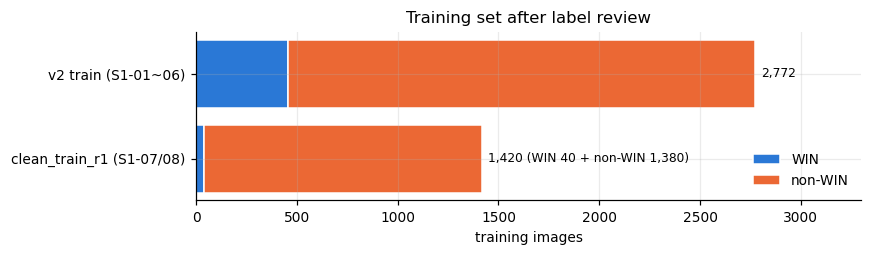

In [7]:
# 검수에서 학습 목록까지(영상 수). 출처: #134·#136·#137·#139, data/splits/clean_train_r1/manifest.json
flow = pd.DataFrame([
    ("재분할 v2 train", 2772, "출발점(#128 감사 대상)"),
    ("  WIN 계열", 458, "#134 행 단위 전수 판정"),
    ("    #134 정상 영상", 315, "#136 대상(258장 재열람 + 57장 #134 판정 승계)"),
    ("    → 사용 가능", 40, "#136 builder 재확인 통과. 수정필요 7·판단불가 211·제외 57"),
    ("  비-WIN 계열", 2314, "#137(desk 612·z-hash 1,220·other 363·NNN_png 83·M6_frame 36)"),
    ("    desk(검토 안 함)", 612, "너트 1,143개, Q5 결정 대기라 제외"),
    ("    원장 검수 통과", 1376, "#137 후보 1,383행 = 통과 1,376 + 강등 5 + 보류 2"),
    ("    → 학습에 넣음", 1375, "#139: G1499를 보류로 더 빼서 1,375"),
    ("    사전 앵커(비-desk 사용 가능)", 5, "N03·N04·N06·N07·N08"),
    ("clean_train_r1 train", 1420, "1,375 + 5 + 40 = S1-07·S1-08 학습 자료"),
], columns=["단계", "영상", "근거"])
display(flow.set_index("단계"))

m = load_json("data/splits/clean_train_r1/manifest.json")
print("manifest 대조: train", m["counts"]["train"]["images"], "장, 출처별", json.dumps(m.get("train_by_source"), ensure_ascii=False))
print("manifest 제외 기록:", m["excluded"]["ledger_or_anchor_excluded_in_v2_train"], "건 /", len(m["excluded"]["held_or_demoted"]), "개 보류·강등 항목")

# 그림 4: 학습 자료 구성 변화(영상 수)
fig, ax = plt.subplots(figsize=(8, 2.4))
labels = ["v2 train (S1-01~06)", "clean_train_r1 (S1-07/08)"]
ax.barh(labels[0], 458, color=C1, edgecolor="white", label="WIN")
ax.barh(labels[0], 2314, left=458, color=C2, edgecolor="white", label="non-WIN")
ax.barh(labels[1], 40, color=C1, edgecolor="white")
ax.barh(labels[1], 1380, left=40, color=C2, edgecolor="white")
ax.text(2772 + 30, 0, "2,772", va="center", fontsize=8)
ax.text(1420 + 30, 1, "1,420 (WIN 40 + non-WIN 1,380)", va="center", fontsize=8)
ax.set_xlim(0, 3300)
ax.invert_yaxis()
ax.set_xlabel("training images")
ax.set_title("Training set after label review")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [8]:
# #144 재라벨링 실행 여부: 재라벨 저장 폴더(Git 제외)가 이 PC에 있으면 파일 수를 센다.
p = ROOT / "data" / "derived" / "win_relabel_prep_r0" / "new_labels"
if p.is_dir():
    n = sum(1 for _ in p.iterdir())
    print(f"new_labels 파일 {n}개 →", "재라벨링 미실행" if n == 0 else "재라벨 파일 있음(내용 미검토)")
else:
    print("data/derived/win_relabel_prep_r0 없음: 확인 불가. 2026-11-23 작성 PC에서는 파일 0개(재라벨링 미실행)")

new_labels 파일 0개 → 재라벨링 미실행


**무엇을 고치고, 빼고, 보류했나**

- **고친 것: 없습니다.** 라벨 파일은 하나도 바꾸지 않았습니다. 수정 초안(#131 T025 재윤곽, #135 10행)은 A 검수 전이라 적용하지 않았습니다.
- **뺀 것:** 학습 목록에서만 뺐습니다(원본 파일은 그대로).
  - 확정 결함·판단불가·혼합 상태 영상
  - 강등 5(G0308·G0458·G0463·G0473·G0686)·보류 3(G1499·G1502·G1504)
  - A 삭제 승인 T120 영상(삭제 자체는 미적용)
  - 검토하지 않은 desk 612장, WIN 사용 가능 40장 밖의 WIN 영상
- **보류한 것:** Q3~Q7 정책(교차 클래스, desk 너트, 못·핀, 한 실물 분할, 가림 분할), T018·T022·T032·T116·T117, #144 WIN 재라벨링(준비만 함, 실행 여부는 A 결정)

**한계**

- `clean_train_r1` train은 **A 승인 전 검수 후보**입니다(manifest `description`). 하위 검토자 판정과 표본 재확인에 기댄 행이 있고, 기억 기반 비후보 95건은 다시 보지 않았습니다(#137).
- **val·test는 보정하지 않았습니다.** test에 확정 결함 12행(위치 어긋남 8·과대 4)과 교차 클래스 2쌍이 남아 있어, 공개 test는 평가가 오염된 점검용입니다(#130).
- 정상 판정 행에도 가림 분할을 하나로 합친 윤곽이 있어, 가림 정책(Q-A·Q-B)이 정해지면 다시 분류될 수 있습니다(#134).
- 선별로 학습 영상이 2,772 → 1,420장, 너트가 1,685 → 140개로 줄었고, 영상의 81 %가 한 장면 계열(z-hash)입니다(#137). S1-07부터 공개 test mAP가 떨어진 것과 관련 있을 수 있습니다(미확인).
- 위치오류 판정은 격자 눈어림(±3 px)이고 검토자마다 기준(8 px 이상 / 5~6 px도 경미)이 달랐습니다(#134).

## 4. 전처리

| 단계 | 내용 | 도구·근거 |
|---|---|---|
| 형식 변환 | COCO 분할 주석 → ultralytics YOLO 분할 라벨(2클래스 bolt·nut). 원본은 그대로 두고 `data/derived/bolt_nut_v2/`(Git 제외)에 링크와 라벨을 만듭니다 | `scripts/coco_to_yolo_seg.py` |
| 재분할 | 장면 묶음 단위 목록(§3.2) | `scripts/resplit_dataset.py` |
| 선별 | 검수 통과 1,420장 목록, 누수(줄기·sha256 교차 0) 검사 | `scripts/prepare_clean_train_r1.py`, #139 |
| 증강 표기 불일치 | Roboflow 안내문은 「No image augmentation」이라 했지만 train에는 줄기당 최대 3장의 사본(뒤집기·회전·잡음·밝기 차)이 있습니다. 증강 사본으로 보고, 같은 줄기를 한 분할에 두고 valid·test에는 줄기당 1장만 씁니다 | `data/raw/README.md`, manifest `notes` |
| 밝기 증강 | ultralytics 기본은 `hsv_v` 0.4(V 배율 0.6~1.4)입니다. S1-08부터 **0.6**(0.4~1.6, A 개발 시험값)으로 올렸습니다. 학습 영상마다 늘 적용하고, val·test에는 적용하지 않습니다 | #141 |
| 입력 크기 | 학습 imgsz 640, 실행 imgsz 1280. 공개 자료는 640×640이라 학습 입력과 같은 크기입니다 | §3.4 |
| 타일 | Gazebo 1280×720 영상을 원래 화소 크기 그대로 640×640 조각으로 자릅니다(§5). 640으로 줄여 학습하면 M3×20 폭이 약 3.5 px가 되기 때문입니다 | `scripts/gz_train_plan.py`, #275 §4.1 |

- **라벨 정의 한계:** 공개 자료와 Gazebo 라벨 모두 「보이는 실루엣 전체」입니다. 설계의 「윗면 윤곽」 라벨이 아닙니다(A 상세 §7.1). 그래서 AI 결과는 표시용 관측(`valid=False`)이고, B 입력은 끝점 두 개입니다.

In [9]:
# 전처리 도구가 저장소에 있는지, 각 도구의 첫 설명 줄을 읽는다.
tools = ["scripts/coco_to_yolo_seg.py", "scripts/resplit_dataset.py", "scripts/prepare_clean_train_r1.py",
         "scripts/gz_train_plan.py", "scripts/gz_eval_scene.py", "scripts/gz_eval_capture.py",
         "scripts/train_candidates.py", "scripts/eval_size_recall.py"]
rows = []
for t in tools:
    p = ROOT / t
    doc = ast.get_docstring(ast.parse(p.read_text(encoding="utf-8"))) if p.is_file() else None
    rows.append({"도구": t, "있음": p.is_file(), "설명 첫 줄": next((ln for ln in (doc or "").splitlines() if ln.strip()), "-")})
display(pd.DataFrame(rows).set_index("도구"))

,있음,설명 첫 줄
도구,,
scripts/coco_to_yolo_seg.py,True,COCO 분할 주석과 재분할 목록을 ultralytics YOLO 분할 형식(2클래스)으로 바꾼다.
scripts/resplit_dataset.py,True,공개 데이터(Bolt nut segmentation v1)를 장면 묶음 단위로 train·valid·test에 재분할한다.
scripts/prepare_clean_train_r1.py,True,검수 train 후보와 기존 v2 val/test로 학습용 데이터 구성(clean_train_r1)을 만든다.
scripts/gz_train_plan.py,True,"Gazebo 학습·판정용 장면 계획과 학습 조각 라벨 계산(#278, Gazebo·ROS 실행 없음)."
scripts/gz_eval_scene.py,True,Gazebo 평가 세트의 월드 사본 SDF와 표본 계획 JSON을 만든다(Gazebo는 실행하지 않음).
scripts/gz_eval_capture.py,True,"Gazebo 평가 세트를 수집한다(묶음마다 `gz sim` 실행, 표본마다 pose 변경 뒤 캡처·라벨 생성)."
scripts/train_candidates.py,True,AI 후보 학습기 CLI(check·prepare-weights·train·resume·status·recover·register-legacy·eval).
scripts/eval_size_recall.py,True,YOLO 분할 모델의 클래스별·크기 구간별 재현율 평가(파일럿).


### 4.1 밝기·대비 감사, 증강 계획, 새 자료 조사

- **밝기·대비 감사(#132, E-132a~c):** 영상 밝기 평균은 공개 train과 Gazebo가 비슷했습니다(p50 128.5 대 126.4). 가장 큰 차이는 **물체–주변 밝기 극성**입니다. Gazebo 볼트·너트 663개는 모두 주변보다 밝았지만(dY > 0), 공개 train desk 볼트는 거의 모두 어두웠습니다(밝은 물체 비율 0.003). Gazebo 실패는 저대비·소형·원거리와 함께 나타났지만, 셋 중 무엇이 원인인지는 정적 상관으로 확정하지 못했습니다. 통제 밝기 실험 B1~B4는 계획만 했습니다.
- **증강 계획(#133, E-133):** 추가 증강 후보와 같은 seed 쌍 비교를 계획했지만, 계획대로는 실행하지 않았습니다. A3(`hsv_v` 0.6) 한 항목만 #141 준비를 거쳐 S1-08로 학습했습니다(seed 0, 1회). 학습 설정의 Albumentations 증강은 패키지가 설치되지 않아 실제로 적용되지 않았습니다.
- **새 Screw 자료(#143, E-143):** Roboflow screw-xawp6 v2를 조사했습니다. 라벨 667행이 모두 상자(다각형 0)이고 클래스는 Metal_Screw 하나, 너트가 없습니다. 지금 분할 학습 경로에 그대로 쓸 수 없어 넣지 않았습니다(처리안은 A 결정 대기).
- **계산 기준점(#149, E-149):** Gazebo 정답 12사례로 볼트·너트 계산 기준점을 정했습니다. 메시–마스크 IoU는 0.972~0.990이었습니다.

## 5. Gazebo 자료(S1-09)

S1-08에는 Gazebo 학습 자료가 없습니다. S1-08은 가로로 놓인 M3×20(D0)을 거의 찾지 못했고(#267 V2 촬영 2/24, 정의는 §7.1 주), 상자 테두리·팔 그림자를 볼트로 오검출했습니다. 학습 자료에 그 크기·배경이 없었기 때문으로 봤습니다(#275 §3.2, 추정). 그래서 Gazebo 장면을 만들어 더했습니다(#275 계획, #278 실행).

| 묶음 | 영상 | 내용 |
|---|---|---|
| G1 | 600 | 현재 월드(`sort_cell.sdf` 사본), 링크 카메라 HOME 자세 중심. M3×20 비중을 높이고, 영상에서 가로로 보이는 자세를 2배로 |
| G2 | 200 | 집기 접근 구간의 카메라 자세 |
| N1 | 200 | 팔·그림자 장면의 음성(부품 없음, 빈 라벨). 실시간 스택에서 원본 영상을 저장해 골랐습니다 |
| E1 | 200 | **판정 전용** 평가 세트(`gz_eval_link_v3`, 평가 시드 구간) |

- **라벨:** Gazebo 분할 카메라(semantic)와 슬롯마다 고유 라벨(`gz-sim-label-system`)로 자동으로 만듭니다(`scripts/gz_eval_scene.py`·`gz_eval_capture.py`). 원본 월드는 바꾸지 않고 사본을 씁니다.
- **시드:** 학습 1,000,000번대, 평가 9,000,000번대로 나눠 섞이지 않게 합니다(`gz_train_plan.py`).
- **분할:** 묶음(`gz sim` 1회) 단위로 val을 나눕니다(아래 `val_rule`).

In [10]:
# S1-09 분할 manifest(저장소 파일): 타일 규칙과 수량.
m = load_json("data/splits/gz_r1/manifest.json")
print("설명:", m["description"])
print("val 규칙:", m["val_rule"])
print("타일:", m["tiles"])
s = m["stats"]
rows = []
for g in ("G1", "G2"):
    rows.append({"묶음": g, "train 조각": s[f"{g}_train_tiles"], "train 라벨 있음": s[f"{g}_train_tiles_labeled"],
                 "train 빈 조각": s[f"{g}_train_tiles_empty"], "train 인스턴스": s[f"{g}_train_inst"],
                 "val 조각": s[f"{g}_val_tiles"], "val 인스턴스": s[f"{g}_val_inst"], "모호해 뺀 조각": s[f"{g}_tile_ambiguous"]})
rows.append({"묶음": "N1", "train 조각": s["N1_train_tiles"], "train 라벨 있음": 0, "train 빈 조각": s["N1_train_tiles"],
             "train 인스턴스": 0, "val 조각": s["N1_val_tiles"], "val 인스턴스": 0, "모호해 뺀 조각": None})
display(pd.DataFrame(rows).set_index("묶음").astype("Int64"))
gz = s["G1_train_tiles"] + s["G2_train_tiles"] + s["N1_train_tiles"]
print(f'train = 공개 {s["pub_train"]} + Gazebo 조각 {gz} = {s["pub_train"] + gz}장 (모델 카드 train_images와 대조)')

설명: #278 S1-09 학습 자료. 공개 clean_train_r1 그대로 + Gazebo 학습 시드(1,000,000번대) 조각 + N1 음성
val 규칙: {'G1': '(index // 20) % 10 == 9', 'G2': 'G2_v4', 'N1': 'SIM 시각 뒤쪽 10 %'}
타일: {'size': 640, 'xs': [0, 320, 640], 'y0': 40, 'N1_xs': [0, 640], 'keep_frac': 0.15, 'min_area_px': 8.0}


,train 조각,train 라벨 있음,train 빈 조각,train 인스턴스,val 조각,val 인스턴스,모호해 뺀 조각
묶음,,,,,,,
G1,1583,1352,231,2812,177,298,40
G2,477,344,133,770,71,114,52
N1,360,0,360,0,40,0,<NA>


train = 공개 1420 + Gazebo 조각 2420 = 3840장 (모델 카드 train_images와 대조)


## 6. 학습

### 6.1 후보와 실험

- **후보 3종**(A 확정 2026-11-12): YOLOv8n-seg, YOLO11n-seg, YOLO26n-seg. 각 공식 COCO 사전학습 가중치(Ultralytics assets v8.4.0, sha256 확인)에서 시작합니다.
- **S1-00 파일럿**(2026-11-12, YOLO11n-seg, 기록 형식 이전): 640 학습·1280 추론에서 작은 물체 재현율이 크게 올랐습니다. 1280 학습은 Gazebo에서 가장 나빴습니다(A 상세 §7.1 「비교 조건 ①」). 그래서 학습 640·추론 1280 조합을 유지했습니다.
- **실험 순서**
  - S1-01~03: 세 후보, 재분할 v2, batch 16
  - S1-04~06: 같은 세 후보, batch 64(A 설정 `s1_batch64_*`)
  - S1-07: YOLOv8n-seg, 선별 자료 `clean_train_r1`
  - S1-08: S1-07 + `hsv_v` 0.6
  - S1-09: S1-08 + Gazebo 조각(`gz_r1`)
  - S1-10a·b·c: S1-08에서 방향만 바꿔 본 회전 실험(§6.5.1). a = 학습 중 무작위 회전, b = 학습 사진 절반을 90° 회전 사본으로, c = b + 라벨 없는 배경 조각 100장

### 6.2 학습기 고정값

추적 학습기 `scripts/train_candidates.py`가 공통 설정 파일을 읽고, 데이터 목록 지문(sha256·줄 수)이 맞을 때만 학습합니다. 결과와 적용 인자를 `outputs/training/<run_set>/`에 남깁니다. S1-01~03은 임시 실행기로 학습한 뒤 `register-legacy`로 원본을 바꾸지 않고 등록했습니다.

In [11]:
# 학습 공통 설정(저장소 config/training)을 실험 묶음별로 비교한다.
runs = {"S1-01~03": "config/training/s1_common.json",
        "S1-04~06": "config/training/s1_batch64_common.json",
        "S1-07": "config/training/s1_clean_train_r1_common.json",
        "S1-08": "config/training/s1_clean_hsvv06_r1_common.json",
        "S1-10a": "config/training/s1_rot_r1_a_common.json",
        "S1-10b": "config/training/s1_rot_r1_b_common.json",
        "S1-10c": "config/training/s1_rot_r1_c_common.json"}
rows = []
for exp, rel in runs.items():
    c = load_json(rel)
    t = dict(c["train"])
    rows.append({"실험": exp, "설정 파일": rel.split("/")[-1], "자료": c["data"]["data_yaml"].split("/")[-2], **t})
card9 = load_json("models/vision/s1_09/MODEL_CARD.json")["training"]
rows.append({"실험": "S1-09", "설정 파일": "_workspace/278_k/training/s1_gz_r1_common.json(Git 제외)",
             "자료": card9["data_yaml"].split("/")[-2],
             **{k: card9.get(k) for k in ("imgsz", "epochs", "seed", "deterministic", "batch", "hsv_v")}})
df = pd.DataFrame(rows).set_index("실험")
df = df.loc[["S1-01~03", "S1-04~06", "S1-07", "S1-08", "S1-09", "S1-10a", "S1-10b", "S1-10c"]]   # 실험 번호 순서로
display(df.fillna("-"))
print("평가 설정 config/training/s1_eval.json:", json.dumps(load_json("config/training/s1_eval.json"), ensure_ascii=False))

,설정 파일,자료,imgsz,epochs,seed,deterministic,batch,device,workers,cache,plots,hsv_v,degrees
실험,,,,,,,,,,,,,
S1-01~03,s1_common.json,bolt_nut_v2,640,50,0,True,16,0,2.0,False,False,-,-
S1-04~06,s1_batch64_common.json,bolt_nut_v2,640,50,0,True,64,0,2.0,False,False,-,-
S1-07,s1_clean_train_r1_common.json,bolt_nut_clean_train_r1,640,50,0,True,16,0,2.0,False,False,-,-
S1-08,s1_clean_hsvv06_r1_common.json,bolt_nut_clean_train_r1,640,50,0,True,16,0,2.0,False,False,0.6,-
S1-09,_workspace/278_k/training/s1_gz_r1_common.json(Git 제외),bolt_nut_gz_r1,640,50,0,True,16,-,-,-,-,0.6,-
S1-10a,s1_rot_r1_a_common.json,bolt_nut_clean_train_r1,640,50,0,True,16,0,2.0,False,False,0.6,180.0
S1-10b,s1_rot_r1_b_common.json,bolt_nut_clean_rot90_r1,640,50,0,True,16,0,2.0,False,False,0.6,-
S1-10c,s1_rot_r1_c_common.json,bolt_nut_clean_rot90_bg_r1,640,50,0,True,16,0,2.0,False,False,0.6,-


평가 설정 config/training/s1_eval.json: {"format_version": 1, "conf": 0.25, "iou": 0.5, "device": "0", "edges_px": [10, 12, 15, 25], "public": {"data_dir": "data/derived/bolt_nut_v2", "split": "test", "imgsz": [640]}, "gazebo": {"data_dir": "data/derived/gz_eval_v1", "split": "test", "imgsz": [640, 1280], "manifest": "data/derived/gz_eval_v1/manifest.jsonl"}, "timing": {"imgsz": [640, 1280], "warmup_n": 10, "measure_n": 200}, "val": {"batch": 8, "workers": 0}}


### 6.2.1 파일럿·smoke 실행과 실패·중단한 학습

| 실행 | 결과 | 일지 |
|---|---|---|
| S1-00 640(yolo11n-seg) | 완료. 50 에포크 약 727 s, GPU 최대 2.7 GB | E-P00a |
| S1-00 1280 첫 시도(workers 4) | **실패.** 3 에포크 뒤 WSL 메모리 부족(rc 137) | E-P00b |
| S1-00 1280 재시도 | **중단.** 1 에포크 78 %에서 끝남(rc 143) | E-P00c |
| S1-00 1280 r2·r3 | **중단.** 다른 gz 프로세스 감지로 감시 규칙이 멈춤(5·3 에포크) | E-P00d |
| S1-00 1280 r4(workers 2) | 완료. 50 에포크, GPU 최대 5,927 MiB | E-P00e |
| S1-10b 첫 시도 | **중단.** 35 s 뒤 학습기 메모리 감시로 멈춤(1 에포크). 새 실행 묶음에서 처음부터 다시 학습 | E-348b |
| smoke_i4a | 1 에포크·자료 5 %로 추적 학습기의 학습·평가 경로만 확인(비교에 안 씀) | E-SM1 |
| smoke_i4b | 부모에 SIGTERM을 보내는 **의도된 중단** 시험(정리 확인) | E-SM2 |
| smoke_b64_a | batch 64 사전 점검 통과. S1-03은 GPU 15,867 MiB(장치의 97 %)까지 써 여유가 작음 | E-SM3 |

- S1-00에서 1280 학습·1280 추론은 Gazebo에서 볼트 0.03·너트 0.00으로 가장 나빴고, 640 학습·1280 추론이 가장 나았습니다(E-P00h). 그래서 이후 모든 실험은 학습 640·추론 1280입니다.
- S1-04(batch 64)는 S1-01보다 Gazebo 볼트·너트를 크게 놓쳤습니다(E-128b: 너트 TP 23 대 2). 학습 직접 출력 단계에서 이미 생긴 차이이고, 원인은 확정하지 못했습니다(첫 3 에포크 lr이 다름, 스텝 수 미확인).

### 6.3 S1-01~S1-09 실험 표

값은 학습 묶음 요약 `outputs/training/<run_set>/summary.md`(Git 제외)에서 옮겼습니다. 평가 조건은 `config/training/s1_eval.json`입니다(conf 0.25, 마스크 IoU ≥ 0.5 일대일 매칭).

- **공개 test:** 161장(볼트 301·너트 84), imgsz 640. 누수 한계가 있는 점검용입니다.
- **gz_eval_v1:** 고정 경사 카메라 Gazebo 200장(볼트 444·너트 219). BOLT_A는 옛 규격 M6×12입니다. S1-08을 고르는 데 썼으므로 지금은 조정용입니다.
- **S1-10a·b·c:** 같은 열 구성의 표를 이 절 끝에 따로 두었습니다. 값은 학습기 `eval.json`에서 옮긴 `docs/reports/data/s1_10_gate.json`입니다.
- **추론 P95:** 새 프로세스에서 Gazebo 영상 200장을 batch 1로 잰 값입니다(워밍업 10회 뒤 200회). 같은 GPU를 다른 일과 나눠 쓴 정도에 따라 흔들립니다. S1-04의 1280 값 8.7 ms처럼 640보다 빠른 행이 있으므로, 모델 사이 작은 차이는 해석하지 않습니다.

In [12]:
# 실험 표. 출처: outputs/training/{s1_legacy,s1_b64,s1_clean_r1,s1_clean_hsvv06_r1,s1_gz_r1}/summary.md
EXPS = pd.DataFrame([
    # 실험, 모델, run_set, 자료, batch, hsv_v, 학습 s, 공개 mAP50 박스, 마스크, gz640 볼트, 너트, gz1280 볼트, 너트, BOLT_A, BOLT_B, NUT, gz1280 오검출 볼트, 너트, P95 640, P95 1280
    ("S1-01", "yolov8n-seg", "s1_legacy", "resplit_v2", 16, 0.4, 631.4, 0.947, 0.905, 0.10, 0.01, 0.60, 0.81, 0.60, 0.60, 0.81, 5, 1, 27.2, 30.3),
    ("S1-02", "yolo11n-seg", "s1_legacy", "resplit_v2", 16, 0.4, 698.5, 0.954, 0.916, 0.11, 0.17, 0.45, 0.95, 0.23, 0.65, 0.95, 5, 7, 22.8, 20.5),
    ("S1-03", "yolo26n-seg", "s1_legacy", "resplit_v2", 16, 0.4, 1154.2, 0.957, 0.904, 0.00, 0.02, 0.06, 0.59, 0.08, 0.04, 0.59, 37, 0, 36.4, 38.2),
    ("S1-04", "yolov8n-seg", "s1_b64", "resplit_v2", 64, 0.4, 546.5, 0.953, 0.898, 0.01, 0.00, 0.18, 0.01, 0.09, 0.25, 0.01, 15, 0, 25.7, 8.7),
    ("S1-05", "yolo11n-seg", "s1_b64", "resplit_v2", 64, 0.4, 572.3, 0.952, 0.902, 0.00, 0.05, 0.46, 0.92, 0.46, 0.46, 0.92, 0, 4, 32.4, 35.7),
    ("S1-06", "yolo26n-seg", "s1_b64", "resplit_v2", 64, 0.4, 921.7, 0.957, 0.912, 0.00, 0.00, 0.05, 0.08, 0.09, 0.01, 0.08, 0, 0, 36.3, 35.6),
    ("S1-07", "yolov8n-seg", "s1_clean_r1", "clean_train_r1", 16, 0.4, 403.6, 0.563, 0.558, 0.33, 0.31, 0.82, 0.97, 0.90, 0.76, 0.97, 77, 1, 7.9, 19.7),
    ("S1-08", "yolov8n-seg", "s1_clean_hsvv06_r1", "clean_train_r1", 16, 0.6, 401.4, 0.554, 0.546, 0.41, 0.47, 0.87, 0.97, 0.89, 0.86, 0.97, 136, 2, 21.0, 21.6),
    ("S1-09", "yolov8n-seg", "s1_gz_r1", "gz_r1", 16, 0.6, 970.7, 0.562, 0.556, 0.65, 0.74, 0.90, 1.00, 0.90, 0.91, 1.00, 2, 3, 18.1, 13.0),
], columns=["실험", "모델", "run_set", "자료", "batch", "hsv_v", "학습 s", "공개 mAP50 박스", "공개 mAP50 마스크",
            "gz640 볼트", "gz640 너트", "gz1280 볼트", "gz1280 너트", "gz1280 BOLT_A", "gz1280 BOLT_B", "gz1280 NUT",
            "gz1280 오검출 볼트", "gz1280 오검출 너트", "P95 640 ms", "P95 1280 ms"]).set_index("실험")
display(EXPS.drop(columns=["run_set"]))

,모델,자료,batch,hsv_v,학습 s,공개 mAP50 박스,공개 mAP50 마스크,gz640 볼트,gz640 너트,gz1280 볼트,gz1280 너트,gz1280 BOLT_A,gz1280 BOLT_B,gz1280 NUT,gz1280 오검출 볼트,gz1280 오검출 너트,P95 640 ms,P95 1280 ms
실험,,,,,,,,,,,,,,,,,,
S1-01,yolov8n-seg,resplit_v2,16,0.4,631.4,0.947,0.905,0.10,0.01,0.60,0.81,0.60,0.60,0.81,5,1,27.2,30.3
S1-02,yolo11n-seg,resplit_v2,16,0.4,698.5,0.954,0.916,0.11,0.17,0.45,0.95,0.23,0.65,0.95,5,7,22.8,20.5
S1-03,yolo26n-seg,resplit_v2,16,0.4,1154.2,0.957,0.904,0.00,0.02,0.06,0.59,0.08,0.04,0.59,37,0,36.4,38.2
S1-04,yolov8n-seg,resplit_v2,64,0.4,546.5,0.953,0.898,0.01,0.00,0.18,0.01,0.09,0.25,0.01,15,0,25.7,8.7
S1-05,yolo11n-seg,resplit_v2,64,0.4,572.3,0.952,0.902,0.00,0.05,0.46,0.92,0.46,0.46,0.92,0,4,32.4,35.7
S1-06,yolo26n-seg,resplit_v2,64,0.4,921.7,0.957,0.912,0.00,0.00,0.05,0.08,0.09,0.01,0.08,0,0,36.3,35.6
S1-07,yolov8n-seg,clean_train_r1,16,0.4,403.6,0.563,0.558,0.33,0.31,0.82,0.97,0.90,0.76,0.97,77,1,7.9,19.7
S1-08,yolov8n-seg,clean_train_r1,16,0.6,401.4,0.554,0.546,0.41,0.47,0.87,0.97,0.89,0.86,0.97,136,2,21.0,21.6
S1-09,yolov8n-seg,gz_r1,16,0.6,970.7,0.562,0.556,0.65,0.74,0.90,1.00,0.90,0.91,1.00,2,3,18.1,13.0


In [13]:
# 원본 대조: outputs/training이 있는 PC에서만. 요약 문자열에 표 값이 그대로 들어 있는지 본다.
def check_against_outputs():
    base = ROOT / "outputs" / "training"
    if not base.is_dir():
        print("outputs/training 없음: 대조를 건너뜁니다(값은 위 표의 출처를 따릅니다).")
        return
    bad = 0
    for exp, r in EXPS.iterrows():
        p = base / r["run_set"] / "summary.json"
        if not p.is_file():
            print(exp, "summary.json 없음"); bad += 1; continue
        row = next((x for x in json.loads(p.read_text(encoding="utf-8"))["rows"] if x["번호"] == exp), None)
        text = json.dumps(row, ensure_ascii=False)
        need = [f'{r["공개 mAP50 박스"]:.3f}/{r["공개 mAP50 마스크"]:.3f}',
                f'1280: {r["gz1280 볼트"]:.2f}/{r["gz1280 너트"]:.2f}',
                f'gz1280: {r["gz1280 오검출 볼트"]}/{r["gz1280 오검출 너트"]}',
                f'1280: P95 {r["P95 1280 ms"]:.1f} ms']
        miss = [n for n in need if n not in text]
        bad += bool(miss)
        print(exp, "일치" if not miss else f"불일치 {miss}")
    print("대조 결과:", "모두 일치" if bad == 0 else f"{bad}개 실험 확인 필요")

check_against_outputs()

S1-01 일치
S1-02 일치
S1-03 일치
S1-04 일치
S1-05 일치
S1-06 일치
S1-07 일치
S1-08 일치
S1-09 일치
대조 결과: 모두 일치


In [14]:
# S1-10a·b·c를 위 실험 표와 같은 열로. 출처: docs/reports/data/s1_10_gate.json(학습기 eval.json 값, 원본 경로·sha256 포함)
GATE = load_json("docs/reports/data/s1_10_gate.json")
S10 = ["S1-10a", "S1-10b", "S1-10c"]
S10_DATA = {"S1-10a": "clean_train_r1", "S1-10b": "clean_rot90_r1", "S1-10c": "clean_rot90_bg_r1"}
S10_RUNSET = {"S1-10a": "s1_rot_r1_a", "S1-10b": "s1_rot_r1_b_try2", "S1-10c": "s1_rot_r1_c"}
rows = []
for e in S10:
    t = GATE["models"][e]["trainer_eval"]
    cfg = load_json(f"config/training/s1_rot_r1_{e[-1]}_common.json")["train"]
    fine = t["gz1280_fine"]
    rows.append((e, "yolov8n-seg", S10_RUNSET[e], S10_DATA[e], cfg["batch"], cfg["hsv_v"], cfg.get("degrees", 0),
                 round(float(t["train_wall_text"].split()[0]), 1), round(t["test640_map50_box"], 3), round(t["test640_map50_mask"], 3),
                 round(t["gz640_recall"]["bolt"], 2), round(t["gz640_recall"]["nut"], 2),
                 round(t["gz1280_recall"]["bolt"], 2), round(t["gz1280_recall"]["nut"], 2),
                 round(fine["BOLT_A"]["recall"], 2), round(fine["BOLT_B"]["recall"], 2), round(fine["NUT"]["recall"], 2),
                 t["gz1280_predictions"]["bolt"]["fp"], t["gz1280_predictions"]["nut"]["fp"],
                 round(t["p95_640_ms"], 1), round(t["p95_1280_ms"], 1)))
EXPS10 = pd.DataFrame(rows, columns=["실험", "모델", "run_set", "자료", "batch", "hsv_v", "degrees", "학습 s", "공개 mAP50 박스", "공개 mAP50 마스크",
                                     "gz640 볼트", "gz640 너트", "gz1280 볼트", "gz1280 너트", "gz1280 BOLT_A", "gz1280 BOLT_B", "gz1280 NUT",
                                     "gz1280 오검출 볼트", "gz1280 오검출 너트", "P95 640 ms", "P95 1280 ms"]).set_index("실험")
display(EXPS10.drop(columns=["run_set"]))


def check_s10_against_outputs():
    # 원본 대조: outputs/training이 있는 PC에서만. 학습 묶음 요약에 표 값이 그대로 들어 있는지 본다.
    base = ROOT / "outputs" / "training"
    if not base.is_dir():
        return "건너뜀(outputs/ 없음)"
    bad = []
    for e in S10:
        t = GATE["models"][e]["trainer_eval"]
        p = base / S10_RUNSET[e] / "summary.json"
        if not p.is_file():
            bad.append(f"{e} summary.json 없음")
            continue
        text = json.dumps(json.loads(p.read_text(encoding="utf-8"))["rows"][0], ensure_ascii=False)
        need = [f'{t["test640_map50_box"]:.3f}/{t["test640_map50_mask"]:.3f}',
                f'1280: {t["gz1280_recall"]["bolt"]:.2f}/{t["gz1280_recall"]["nut"]:.2f}',
                f'gz1280: {t["gz1280_predictions"]["bolt"]["fp"]}/{t["gz1280_predictions"]["nut"]["fp"]}',
                f'1280: P95 {t["p95_1280_ms"]:.1f} ms', f'학습 {t["train_wall_text"]}']
        bad += [f"{e} {n}" for n in need if n not in text]
    return "모두 일치" if not bad else f"확인 필요 {bad}"


print("원본 대조(S1-10a·b·c 학습 묶음 요약):", check_s10_against_outputs())

,모델,자료,batch,hsv_v,degrees,학습 s,공개 mAP50 박스,공개 mAP50 마스크,gz640 볼트,gz640 너트,gz1280 볼트,gz1280 너트,gz1280 BOLT_A,gz1280 BOLT_B,gz1280 NUT,gz1280 오검출 볼트,gz1280 오검출 너트,P95 640 ms,P95 1280 ms
실험,,,,,,,,,,,,,,,,,,,
S1-10a,yolov8n-seg,clean_train_r1,16,0.6,180,380.1,0.573,0.558,0.33,0.04,0.89,0.80,0.88,0.90,0.80,1,1,25.5,29.7
S1-10b,yolov8n-seg,clean_rot90_r1,16,0.6,0,415.2,0.573,0.566,0.39,0.36,0.90,0.89,0.90,0.89,0.89,148,5,21.9,15.3
S1-10c,yolov8n-seg,clean_rot90_bg_r1,16,0.6,0,528.6,0.551,0.527,0.55,0.45,0.85,0.97,0.91,0.81,0.97,5,8,26.7,20.5


원본 대조(S1-10a·b·c 학습 묶음 요약): 모두 일치


### 6.3.1 실험별 가설·바꾼 것·결과·결론

| 실험 | 가설·목적 | 바꾼 것 | 결과(gz_eval_v1 1280, conf 0.25) | 결론 |
|---|---|---|---|---|
| S1-00 | 공개 자료만으로 Gazebo 부품을 찾을 수 있는가, 학습·추론 크기 조합 | yolo11n-seg, 640/1280 학습 × 640/1280 추론 | 640·1280 볼트 0.51·너트 0.62, BOLT_A 0.27. 1280 학습은 OOM 등으로 4번 실패·중단 뒤 완주 | 공개 자료만으로는 약함. 학습 640·추론 1280 유지(E-P00a~i) |
| S1-01~03 | 세 후보 중 무엇이 나은가 | 모델 계열(같은 조건) | 볼트 0.60 / 0.45 / 0.06 | YOLOv8n-seg가 Gazebo 볼트에서 가장 나음. 해석은 A 판단(E-S1a) |
| S1-04~06 | 큰 batch가 나은가 | batch 16 → 64 | 볼트 0.18 / 0.46 / 0.05 | 나아지지 않음, 원인 미확정(M-04, E-128b) |
| S1-07 | 라벨이 맞는 영상만 학습하면 나아지는가(#128~#137) | 학습 자료 → clean_train_r1 1,420장 | 볼트 0.82·너트 0.97, 오검출 77 | Gazebo 크게 오름(M-05) |
| S1-08 | 밝기 증강을 넓히면 나아지는가(#132·#133) | `hsv_v` 0.4 → 0.6 | 볼트 0.87·너트 0.97, 오검출 136(S1-07 77) | 재현율은 후보 중 최고지만 오검출도 최다. 링크 v2에서는 오검출 34 → 11로 반대. 운영 채택(M-06) |
| S1-10b | 가로 M3×20을 놓치는 것은 학습 자료에 가로로 놓인 볼트가 없어서인가(#348) | 학습 사진 1,420장 중 710장을 90° 회전 사본으로 | 볼트 0.90·너트 0.89, 오검출 148. 가로 M3×20 14/15 | 가로 M3×20은 찾지만 상자 벽 테두리를 볼트로 봄. 불합격(E-348c) |
| S1-10a | 학습 중 무작위 회전이면 상자 벽 부작용 없이 되는가(#350) | `degrees` 0 → 180(자료는 S1-08과 같음) | 볼트 0.89·너트 0.80, 오검출 1. 가로 M3×20 0/15 | 상자 벽 오검출은 없지만 M3×20·너트를 놓침. 불합격(E-350a) |
| S1-10c | 볼트 없는 배경 사진을 보여 주면 상자 벽 오검출이 없어지는가(#353) | S1-10b 자료 + 라벨 없는 배경 조각 100장 | 볼트 0.85·너트 0.97, 오검출 5. 가로 M3×20 9/15 | 상자 벽은 없어졌지만 가로 M3×20이 떨어짐. 불합격(E-353a) |
| S1-09 | 가로 M3×20·상자 테두리·그림자 결함은 자료 부족 때문인가(#275) | Gazebo 조각 G1·G2·N1 추가 | 볼트 0.90·너트 1.00, 오검출 2. 판정 기준 모두 통과 | 자료와 함께 학습량(갱신 약 2.7배)도 바뀜. 평가용 후보, 교체는 A 결정(E-275c, E-278a~) |

### 6.4 운영 모델 S1-08

S1-08은 지금 운영하는 검출 모델입니다(A 결정 2026-11-21). 이 절은 S1-08 하나만 모아 적습니다.

**한눈에 보기**

| 항목 | 값 |
|---|---|
| 모델 | YOLOv8n-seg, 공식 사전학습 가중치(Ultralytics assets v8.4.0, sha256 `a7cd8f92…`)에서 새로 학습 |
| 가중치 | `models/vision/s1_08/best.pt`(sha256 `99be54c2…`, 7,041,268 바이트) |
| 학습 자료 | `clean_train_r1`: 검수 통과 train 1,420장(볼트 1,446·너트 140) + 재분할 v2의 val 162·test 161 그대로 |
| 학습 설정 | imgsz 640, 50 에포크, batch 16, seed 0, deterministic, workers 2, **hsv_v 0.6**, 그 밖은 ultralytics 기본값 |
| 학습 시간 | 401 s(RTX 5080) |
| 실행 설정 | conf 0.05, imgsz 1280, NMS IoU 0.7, FP32, retina 마스크(`config/vision/ai_s1_08_*.json`) |
| 끝점·보정 | M2 끝점 추출, 시야 보정 C1 k 1.39 mm·평면 0.105 m(`ai_s1_08_axis_m2_viewbias.json`) |

**데이터(§3.3)**

- 공개 자료 Bolt nut segmentation v1(CC BY 4.0)에서, 사람이 라벨을 다시 확인해 통과한 train 영상만 골랐습니다(#134~#137 검수, #139 준비).
- 라벨을 고쳐 쓰지 않았습니다. 윤곽이 맞는 영상만 남기고, 강등·보류 영상과 검토하지 않은 desk 612장은 뺐습니다.
- val·test는 재분할 v2와 바이트까지 같습니다. 그래서 S1-01~06과 같은 공개 test로 비교됩니다.
- 분할 사이 누수 검사(줄기·sha256 교차)는 0건입니다.
- 편중: 학습 영상의 81 %(1,153장)가 한 장면 계열(z-hash)이고, 너트는 140개뿐입니다(#137). train 목록은 A 승인 전 검수 후보입니다(manifest `description`).

**전처리(§4)**

- COCO → YOLO 분할 2클래스 변환, 640×640 학습 입력(공개 자료 그대로)
- 밝기 증강 `hsv_v` 0.6: 학습 영상마다 V 배율을 0.4~1.6에서 고릅니다. 기본값 0.4는 0.6~1.4입니다.
- 실행 때는 1280으로 추론합니다. 링크 카메라 1280×720 영상을 줄이지 않아 작은 부품이 모델 입력에서 12 px 기준을 넘게 하려는 것입니다(§3.4).

**S1-01~S1-07에서 S1-08로 온 과정**

| 단계 | 바꾼 것 | 이유(기록) | 결과(gz_eval_v1 1280, conf 0.25) |
|---|---|---|---|
| S1-01~03 | 후보 3종을 같은 조건(재분할 v2, batch 16)으로 학습 | 후보 비교(A 확정 2026-11-12) | 볼트 재현율 0.60 / 0.45 / 0.06. YOLOv8n-seg(S1-01)가 가장 높음 |
| S1-04~06 | batch 64 | 학습 설정 비교(A 설정) | 볼트 0.18 / 0.46 / 0.05. 나아지지 않음 |
| S1-07 | 학습 자료를 검수 통과 1,420장으로(모델은 YOLOv8n-seg 하나) | S1-01 오검출·누락 사례(#129)와 라벨 검수(#134~#137)에서 라벨이 맞지 않는 학습 영상이 확인됨. A 지시 「일단 학습 준비해줘」(#139)로 검수 통과 영상만 학습 | 볼트 0.82·너트 0.97로 크게 오름. 공개 test mAP는 0.95 → 0.56 |
| **S1-08** | `hsv_v` 0.4 → **0.6**(그 밖 S1-07과 같음) | A 결정 「밝기 증강 후 재학습」(#141). 강도 0.6은 A 개발 시험값 | **볼트 0.87·너트 0.97**, BOLT_A 0.89·BOLT_B 0.86. 같은 세트 볼트 오검출은 **77 → 136으로 늘어남**. 링크 v2(conf 0.05)에서는 오검출 34 → 11로 줄어 세트마다 엇갈림 |

- S1-07에서 YOLOv8n-seg 하나만 학습한 결정 문서는 찾지 못했습니다(미확인). 당시 실시간 확인 모델이 S1-01(YOLOv8n-seg)이었고(#129), S1-01~03 중 Gazebo 볼트 재현율도 가장 높았습니다.
- 밝기 증강의 한계(#141): 영상 전체 밝기를 바꾸므로 물체–배경의 밝고 어두운 관계(극성)는 바뀌지 않습니다. 효과도 보장되지 않습니다.

**conf 0.05 선택**

- 실행 conf는 0.05입니다(A 상세 §13 11-17 행). **0.05를 고른 경위 문서는 찾지 못했습니다(미확인, #219도 같음).**
- 링크 v2에서 S1-08 conf 0.05는 볼트 재현율 0.96·정밀도 0.97, 너트 0.95·0.98입니다(§7.3 그림 3).
- 0.025로 낮추면 볼트 오검출이 11 → 217개로 크게 늘고, 0.25로 올리면 너트 재현율이 0.75로 떨어집니다. 0.05는 그 사이의 값입니다(해석).
- 같은 0.05에서 S1-07은 볼트 오검출이 34개, S1-08은 11개입니다(아래 표).

**한계**

- `gz_eval_v1`로 후보를 골라서 이 세트는 조정용이 됐고, 독립 판정 세트가 없습니다.
- 가로로 놓인 M3×20을 거의 찾지 못합니다(D0, #267 V2 2/24, #278 E2 1/15. 두 분모의 차이는 §7.1 주).
- 상자 테두리 (700, −112) mm를 볼트로 오검출합니다(실시간 확정 11~15번, #278 E3). 실행 경로에서는 벨트 밖 제외(§7.4)가 이를 거릅니다(#293 r2 5,316건 제외, 정답 위 제외 0).
- 팔 그림자·손가락을 볼트로 오검출합니다(#262, #278 E3 3조건에서 3번씩).
- 공개 test 볼트 재현율은 0.53입니다(누수 한계가 있는 점검용, A 상세 §7.1).
- 세운·기운 볼트, 실제 카메라 영상은 평가하지 않았습니다.

In [15]:
# S1-08 평가 결과 모음. 출처는 각 행.
s108 = pd.DataFrame([
    ("공개 test mAP50 박스/마스크", "eval imgsz 640, conf 0.25", "0.554 / 0.546", "outputs/training/s1_clean_hsvv06_r1/summary.md"),
    ("gz_eval_v1 재현율 볼트/너트", "1280, conf 0.25", "0.87 / 0.97", "같음"),
    ("gz_eval_v1 세부 BOLT_A(M6×12)/BOLT_B/NUT", "1280, conf 0.25", "0.89 / 0.86 / 0.97", "같음"),
    ("gz_eval_v1 오검출 볼트/너트", "1280, conf 0.25", "136 / 2", "같음"),
    ("링크 v2 볼트", "1280, conf 0.05", "425/442 (평가 도구 424)", "#219, conf_sweep green_link"),
    ("E1 재현율 M3×20/M6×12/M6×40/NUT", "운영 조건", "0.553 / 0.930 / 0.894 / 0.948, 오검출 122", "#278"),
    ("D0 가로 M3×20", "E2", "1/15", "#278"),
    ("M3×20 / M6×40 끝점까지 통과", "E2 단독", "13/40 / 30/40", "#278"),
    ("상자 테두리 오검출 확정", "E3 3조건", "11·15·13번", "#278"),
    ("추론 P95 1280", "timing / E3 실측", "21.6 / 21.4~21.6 ms", "summary.md, #278"),
], columns=["지표", "조건", "S1-08", "출처"]).set_index("지표")
display(s108)

# 같은 링크 v2, conf 0.05에서 S1-07과 S1-08. 출처: outputs/conf_sweep/s107_s108_green_link_20261117_110321_89c80b/summary.tsv
s0708 = pd.DataFrame([
    ("S1-07", "bolt", 442, 424, 458), ("S1-07", "nut", 236, 225, 229),
    ("S1-08", "bolt", 442, 424, 435), ("S1-08", "nut", 236, 225, 230),
], columns=["모델", "class", "gt_n", "tp", "pred_n"])
s0708["fp"] = s0708["pred_n"] - s0708["tp"]
s0708["recall"] = (s0708["tp"] / s0708["gt_n"]).round(3)
s0708["precision"] = (s0708["tp"] / s0708["pred_n"]).round(3)
display(s0708.set_index(["모델", "class"]))

# 실험 표(6.3)에서 S1-01→S1-08 흐름만 다시 본다.
display(EXPS.loc[["S1-01", "S1-04", "S1-07", "S1-08"], ["모델", "자료", "batch", "hsv_v", "gz1280 볼트", "gz1280 너트",
                                                        "gz1280 오검출 볼트", "공개 mAP50 마스크", "P95 1280 ms"]])

,조건,S1-08,출처
지표,,,
공개 test mAP50 박스/마스크,"eval imgsz 640, conf 0.25",0.554 / 0.546,outputs/training/s1_clean_hsvv06_r1/summary.md
gz_eval_v1 재현율 볼트/너트,"1280, conf 0.25",0.87 / 0.97,같음
gz_eval_v1 세부 BOLT_A(M6×12)/BOLT_B/NUT,"1280, conf 0.25",0.89 / 0.86 / 0.97,같음
gz_eval_v1 오검출 볼트/너트,"1280, conf 0.25",136 / 2,같음
링크 v2 볼트,"1280, conf 0.05",425/442 (평가 도구 424),"#219, conf_sweep green_link"
E1 재현율 M3×20/M6×12/M6×40/NUT,운영 조건,"0.553 / 0.930 / 0.894 / 0.948, 오검출 122",#278
D0 가로 M3×20,E2,1/15,#278
M3×20 / M6×40 끝점까지 통과,E2 단독,13/40 / 30/40,#278
상자 테두리 오검출 확정,E3 3조건,11·15·13번,#278


gt_n   tp  pred_n  fp  recall  precision
모델    class                                          
S1-07 bolt    442  424     458  34   0.959      0.926
      nut     236  225     229   4   0.953      0.983
S1-08 bolt    442  424     435  11   0.959      0.975
      nut     236  225     230   5   0.953      0.978

,모델,자료,batch,hsv_v,gz1280 볼트,gz1280 너트,gz1280 오검출 볼트,공개 mAP50 마스크,P95 1280 ms
실험,,,,,,,,,
S1-01,yolov8n-seg,resplit_v2,16,0.4,0.60,0.81,5,0.905,30.3
S1-04,yolov8n-seg,resplit_v2,64,0.4,0.18,0.01,15,0.898,8.7
S1-07,yolov8n-seg,clean_train_r1,16,0.4,0.82,0.97,77,0.558,19.7
S1-08,yolov8n-seg,clean_train_r1,16,0.6,0.87,0.97,136,0.546,21.6


### 6.5 재학습 후보 S1-09(평가용)

S1-09는 S1-08의 설정을 그대로 두고 학습 자료에 Gazebo 조각(§5)만 더한 후보입니다(#275·#278). 바꾼 설정은 자료 하나지만, 학습 영상이 1,420 → 3,840장으로 늘어 같은 50 에포크에서도 가중치 갱신 횟수가 약 2.7배입니다(학습 시간 401 → 971 s). 그래서 **자료와 학습량이 함께 바뀌었고**, 결과 차이를 자료만의 효과로 볼 수 없습니다. 판정 기준은 결과를 보기 전에 고정했고(§7.1), 모두 통과했습니다. 운영은 S1-08 그대로이며, 교체는 A 결정 대기입니다(§8.2). S1-08과의 비교는 §7.1·§7.4에 있습니다.

### 6.5.1 회전 실험 S1-10a·b·c(모두 불합격, 운영 반영 없음)

- **목적:** 운영 모델 S1-08은 영상 가로 방향으로 놓인 M3×20(1280 영상에서 폭 약 7 px)을 거의 찾지 못합니다(재촬영 15장 중 1장). S1-09는 Gazebo 조각을 더해 15장을 모두 찾았습니다. S1-10은 **Gazebo 자료 없이 실사진만으로** 이 문제가 풀리는지 본 실험입니다(#348·#350·#353).
- **사전 확인(학습 없음, 일지 E-348a):** S1-08이 놓친 가로 M3×20 22개를 잘라 45° 이상 돌려 넣으면 22개를 모두 찾았습니다. 그래서 놓치는 주원인을 방향으로 보고, 방향만 바꾸는 세 실험을 했습니다.
- **세 실험이 바꾼 것:** 나머지 학습 조건은 S1-08과 같습니다(YOLOv8n-seg, 640 입력, 50 에포크, batch 16, seed 0, `hsv_v` 0.6). 아래 셀이 설정 파일에서 차이를 읽습니다.

| 실험 | 바꾼 것 | 설정·자료 |
|---|---|---|
| S1-10a | 학습 중 사진을 매번 무작위 각도(−180°~+180°)로 돌림(`degrees` 180). 크기 증강 `scale`은 기본값 0.5 그대로 | `config/training/s1_rot_r1_a_*.json`, 자료는 S1-08과 같은 `clean_train_r1` |
| S1-10b | 학습 사진 1,420장 중 710장을 90° 시계 방향으로 돌린 사본으로 바꿈 | `config/training/s1_rot_r1_b_*.json`, `data/splits/clean_rot90_r1/` |
| S1-10c | S1-10b 자료에 라벨 없는 배경 조각 100장(학습 사진에서 볼트가 없는 자리를 잘라 냄)을 더함 | `config/training/s1_rot_r1_c_*.json`, `data/splits/clean_rot90_bg_r1/` |

- **실행 순서:** b → a → c입니다. 학습 기록에는 셋 다 `S1-10`으로 남아, 실행 묶음 이름으로 구분합니다(§0 일지).
- **합격 기준:** 결과를 보기 전에 정했습니다. 기준과 판정표는 §7.1.1에 있습니다.
- **결과 요약**
  - **S1-10b:** 가로 M3×20을 14/15 찾았습니다. 그러나 링크 카메라 세트 200장 모두에서 분류 상자 벽 테두리를 볼트로 봤고(잘못 넘긴 볼트 253), 너트 재현율이 0.886으로 떨어졌습니다. 기준 6개 중 3개 미달입니다.
  - **S1-10a:** 상자 벽 오검출은 0이지만 가로 M3×20을 0/15 찾았습니다. 방향과 관계없이 M3×20 전체를 거의 못 찾게 됐습니다(끝점 통과 2/40). 기준 6개 중 4개 미달입니다.
  - **S1-10c:** 상자 벽 오검출이 200 → 0으로 없어지고 너트 재현율도 0.968로 돌아왔습니다. 그러나 가로 M3×20이 9/15로 떨어졌고, 너트 위에 볼트 예측을 함께 내는 경우가 64개 생겼습니다. 기준 8개 중 3개 미달입니다.
- **결론:** 셋 다 불합격이라 실시간 시험과 다른 seed 재현 학습은 하지 않았습니다. **운영 모델은 S1-08 그대로**이고 가중치·운영 설정은 바뀌지 않았습니다. 추가 학습은 보류 중입니다.
- **한계**
  - 학습은 실험마다 seed 0 한 번입니다.
  - S1-10c는 학습 사진 수가 1,420 → 1,520장으로 바뀌어 학습 순서와 단계 수(약 7 % 증가)도 함께 달라졌습니다. S1-10b와의 차이를 배경 조각만의 효과로 볼 수 없습니다.
  - 학습 전 증강 미리보기 기준(가로·가는 볼트가 S1-08 자료의 3배 이상)은 a·b 모두 미달이었고(1.9배·2.3배), A 결정으로 학습을 진행했습니다.

In [16]:
# S1-10 세 실험의 설정과 자료(저장소 파일에서 읽음). 학습 설정은 S1-08과 비교한 차이만 적는다.
base = load_json("config/training/s1_clean_hsvv06_r1_common.json")
rows = []
for e in S10:
    c = load_json(f"config/training/s1_rot_r1_{e[-1]}_common.json")
    diff = {k: v for k, v in c["train"].items() if base["train"].get(k) != v}
    n_train = sum(1 for _ in open(ROOT / "data" / "splits" / S10_DATA[e] / "train.txt", encoding="utf-8"))
    rows.append({"실험": e, "설정 파일": f"s1_rot_r1_{e[-1]}_common.json", "자료": c["data"]["data_yaml"].split("/")[-2],
                 "학습 사진(장)": n_train, "S1-08과 다른 학습 설정": json.dumps(diff) if diff else "없음(자료만 다름)"})
display(pd.DataFrame(rows).set_index("실험"))

rot = load_json("data/splits/clean_rot90_r1/manifest.json")["verify"]
bg = load_json("data/splits/clean_rot90_bg_r1/manifest.json")["verify"]
print(f"회전 사본 자료(clean_rot90_r1): 학습 {rot['n_train']}장 중 {rot['n_rot90']}장을 90° 사본으로(seed {rot['seed']}). "
      f"볼트·너트 수 {rot['instances_before']} → {rot['instances_after']}")
print(f"  가로로 놓인 가는 볼트 {rot['orient_before']['thin_horizontal']} → {rot['orient_after']['thin_horizontal']}개, "
      f"세로 {rot['orient_before']['thin_vertical']} → {rot['orient_after']['thin_vertical']}개. "
      f"라벨 겹침(IoU) 최소 {rot['iou']['min']:.4f}({rot['iou']['n']}개), 검증·시험과 겹치는 사본 {rot['leak']['names'] + rot['leak']['pixel_hash']}")
print(f"배경 조각 자료(clean_rot90_bg_r1): 학습 {bg['n_train']}장 = S1-10b {bg['n_train_src']}장 + 조각 {bg['n_bg']}장"
      f"(곧은 경계가 있는 조각 {bg['n_bg_straight']}장). 검증·시험과 화소가 겹치는 조각 {bg['leak_pix_vs_valtest']}")


def names(rel):
    # 분할 목록의 영상 이름(폴더·확장자 제외)
    return sorted(Path(line.strip()).stem for line in open(ROOT / rel, encoding="utf-8") if line.strip())


same = all(names(f"data/splits/{d}/{k}.txt") == names(f"data/splits/clean_train_r1/{k}.txt")
           for d in ("clean_rot90_r1", "clean_rot90_bg_r1") for k in ("valid", "test"))
print("검증 162장·시험 161장이 S1-08 자료(clean_train_r1)와 같은 영상인가:", same)

,설정 파일,자료,학습 사진(장),S1-08과 다른 학습 설정
실험,,,,
S1-10a,s1_rot_r1_a_common.json,bolt_nut_clean_train_r1,1420,"{""degrees"": 180}"
S1-10b,s1_rot_r1_b_common.json,bolt_nut_clean_rot90_r1,1420,없음(자료만 다름)
S1-10c,s1_rot_r1_c_common.json,bolt_nut_clean_rot90_bg_r1,1520,없음(자료만 다름)


회전 사본 자료(clean_rot90_r1): 학습 1420장 중 710장을 90° 사본으로(seed 0). 볼트·너트 수 {'bolt': 1446, 'nut': 140} → {'bolt': 1446, 'nut': 140}
  가로로 놓인 가는 볼트 5 → 75개, 세로 156 → 86개. 라벨 겹침(IoU) 최소 0.9815(800개), 검증·시험과 겹치는 사본 0
배경 조각 자료(clean_rot90_bg_r1): 학습 1520장 = S1-10b 1420장 + 조각 100장(곧은 경계가 있는 조각 50장). 검증·시험과 화소가 겹치는 조각 0
검증 162장·시험 161장이 S1-08 자료(clean_train_r1)와 같은 영상인가: True


### 6.6 학습 곡선(S1-01~S1-10, 에포크별)

- **출처:** Ultralytics가 학습 중 에포크마다 남긴 `results.csv`입니다(`outputs/`, Git 제외).
  - 노트북이 저장소만으로 다시 그려지도록 값을 `docs/reports/data/s1_train_curves.csv`로 그대로 옮겼습니다.
  - 원본 경로·sha256은 `s1_train_curves_sources.json`에 있습니다(#347, S1-10a·b·c는 #386에서 같은 방식으로 더함).
- **같은 학습인지:** 12개 모두 `best.pt` sha256이 등록 기록과 같습니다(아래 표의 `same_training`). 등록 기록은 `eval.json`, `SHA256SUMS`, S1-01~03은 `s1_legacy/run_set.json`, S1-08·09는 모델 카드와 `models/vision/*/best.pt`입니다.
- **best 에포크의 뜻:** 이 절의 「best」는 Ultralytics가 실제로 저장한 `best.pt`의 에포크입니다.
  - Ultralytics 8.4.211은 박스 mAP50-95와 마스크 mAP50-95를 더한 값이 가장 큰 에포크의 가중치를 `best.pt`로 남깁니다(`SegmentMetrics.fitness`).
  - `best.pt` 안에 저장된 학습 지표가 이 에포크의 `results.csv` 값과 12개 모두 같음을 확인했습니다(#386, `s1_train_curves_sources.json`의 `best_pt_epoch`).
  - 이전 판은 마스크 mAP50-95만 가장 큰 에포크를 best로 적었습니다. 두 기준이 다른 실험은 S1-05(48 → 49)와 S1-08(47 → 49)입니다.
- **검증 세트:**
  - S1-01~S1-08은 모두 같은 공개 val 162장입니다. 영상 목록과 라벨 파일이 바이트까지 같습니다.
  - S1-10a·b·c도 같은 공개 val 162장입니다(§6.5.1 셀이 영상 이름을 대조). 그래서 S1-08과 val 손실·지표를 직접 비교할 수 있습니다. 학습 손실은 학습 사진과 증강이 달라 직접 비교하지 않습니다.
  - S1-09는 공개 val 162장에 Gazebo 조각 288장을 더한 450장입니다.
  - 그래서 S1-09의 val 손실·지표는 다른 실험과 직접 비교하지 않습니다.
- **열:** box·seg·cls 손실은 모든 실험에 있습니다.
  - 네 번째 손실은 YOLOv8·YOLO11이 `dfl`, YOLO26(S1-03·S1-06)이 `l1`입니다.
  - `sem`은 YOLO26 학습 손실에만 값이 있습니다(val은 0).
  - 학습률은 `lr/pg0`·`pg1`·`pg2`가 모든 에포크에서 같아서 한 줄로 그렸습니다.
- **학습 중 지표의 조건:** Ultralytics 기본값(conf 0.001, NMS IoU 0.7, 학습 val 세트)입니다. 우리 평가(§7, conf 0.25·0.05, Gazebo·링크 세트)와 조건이 다릅니다.

In [17]:
# 학습 곡선 원자료(저장소 docs/reports/data). outputs/가 있으면 원본 results.csv와 값 전부를 대조한다.
CURVES = pd.read_csv(ROOT / "docs/reports/data/s1_train_curves.csv")
CURVE_SRC = load_json("docs/reports/data/s1_train_curves_sources.json")
src_rows = [{"실험": e, "에포크 수": s["rows"], "best.pt sha256(앞 16)": s["weights_sha256"][:16],
             "등록 기록": ", ".join(k for k in s["registered_sha256"]), "same_training": s["same_training"]}
            for e, s in CURVE_SRC["sources"].items()]
display(pd.DataFrame(src_rows))


def check_curves_against_outputs():
    # 원본 results.csv(있을 때만)와 옮긴 값을 칸마다 비교한다.
    n_ok = n_all = 0
    for e, s in CURVE_SRC["sources"].items():
        p = ROOT / s["results_csv"]
        if not p.is_file():
            return "건너뜀(outputs/ 없음)"
        raw = pd.read_csv(p)
        raw.columns = [c.strip() for c in raw.columns]
        mine = CURVES[CURVES.exp == e].reset_index(drop=True)
        for c in raw.columns:
            a, b = raw[c].astype(float).to_numpy(), mine[c].astype(float).to_numpy()
            n_all += len(a)
            n_ok += int((abs(a - b) <= 1e-9).sum())
    return f"{n_ok}/{n_all}칸 일치"


print("원본 대조:", check_curves_against_outputs())


def fitness_epoch(e):
    # Ultralytics가 best.pt를 고르는 기준(박스 mAP50-95 + 마스크 mAP50-95)이 가장 큰 에포크
    g = CURVES[CURVES.exp == e].sort_values("epoch")
    return int(g.loc[(g["metrics/mAP50-95(B)"] + g["metrics/mAP50-95(M)"]).idxmax(), "epoch"])


BEST_EP = {e: fitness_epoch(e) for e in CURVE_SRC["sources"]}   # 실제로 저장된 best.pt의 에포크
print("best.pt 에포크(곡선에서 다시 계산):", BEST_EP)
print("best.pt 안에 저장된 지표로 확인한 에포크(best_pt_epoch)와 같은가:",
      BEST_EP == {e: s["best_pt_epoch"] for e, s in CURVE_SRC["sources"].items()})

,실험,에포크 수,best.pt sha256(앞 16),등록 기록,same_training
0,S1-01,50,68ed4d1139d4d19f,s1_legacy/run_set.json,True
1,S1-02,50,b889a77c1e55f153,s1_legacy/run_set.json,True
2,S1-03,50,f5b44d31533d6455,s1_legacy/run_set.json,True
3,S1-04,50,c5ffc46e986e5bea,"eval.json, outputs/training/s1_b64/SHA256SUMS",True
4,S1-05,50,0fcf8dbfde3ed5ab,"eval.json, outputs/training/s1_b64/SHA256SUMS",True
5,S1-06,50,51d72409e18c8a08,"eval.json, outputs/training/s1_b64/SHA256SUMS",True
6,S1-07,50,f921ae2dc9d2bc70,"eval.json, outputs/training/s1_clean_r1/SHA256SUMS",True
7,S1-08,50,99be54c285cd05a7,"eval.json, outputs/training/s1_clean_hsvv06_r1/SHA256SUMS, models/vision/s1_08/MODEL_CARD.json, models/vision/s1_08/best.pt (파일)",True
8,S1-09,50,ac4176ee492dc97e,"eval.json, outputs/training/s1_gz_r1/SHA256SUMS, models/vision/s1_09/MODEL_CARD.json, models/vision/s1_09/best.pt (파일)",True
9,S1-10a,50,8b41d4fcd5cc462f,"eval.json, outputs/training/s1_rot_r1_a/SHA256SUMS",True


원본 대조: 13800/13800칸 일치
best.pt 에포크(곡선에서 다시 계산): {'S1-01': 46, 'S1-02': 50, 'S1-03': 50, 'S1-04': 48, 'S1-05': 49, 'S1-06': 49, 'S1-07': 49, 'S1-08': 49, 'S1-09': 46, 'S1-10a': 49, 'S1-10b': 43, 'S1-10c': 39}
best.pt 안에 저장된 지표로 확인한 에포크(best_pt_epoch)와 같은가: True


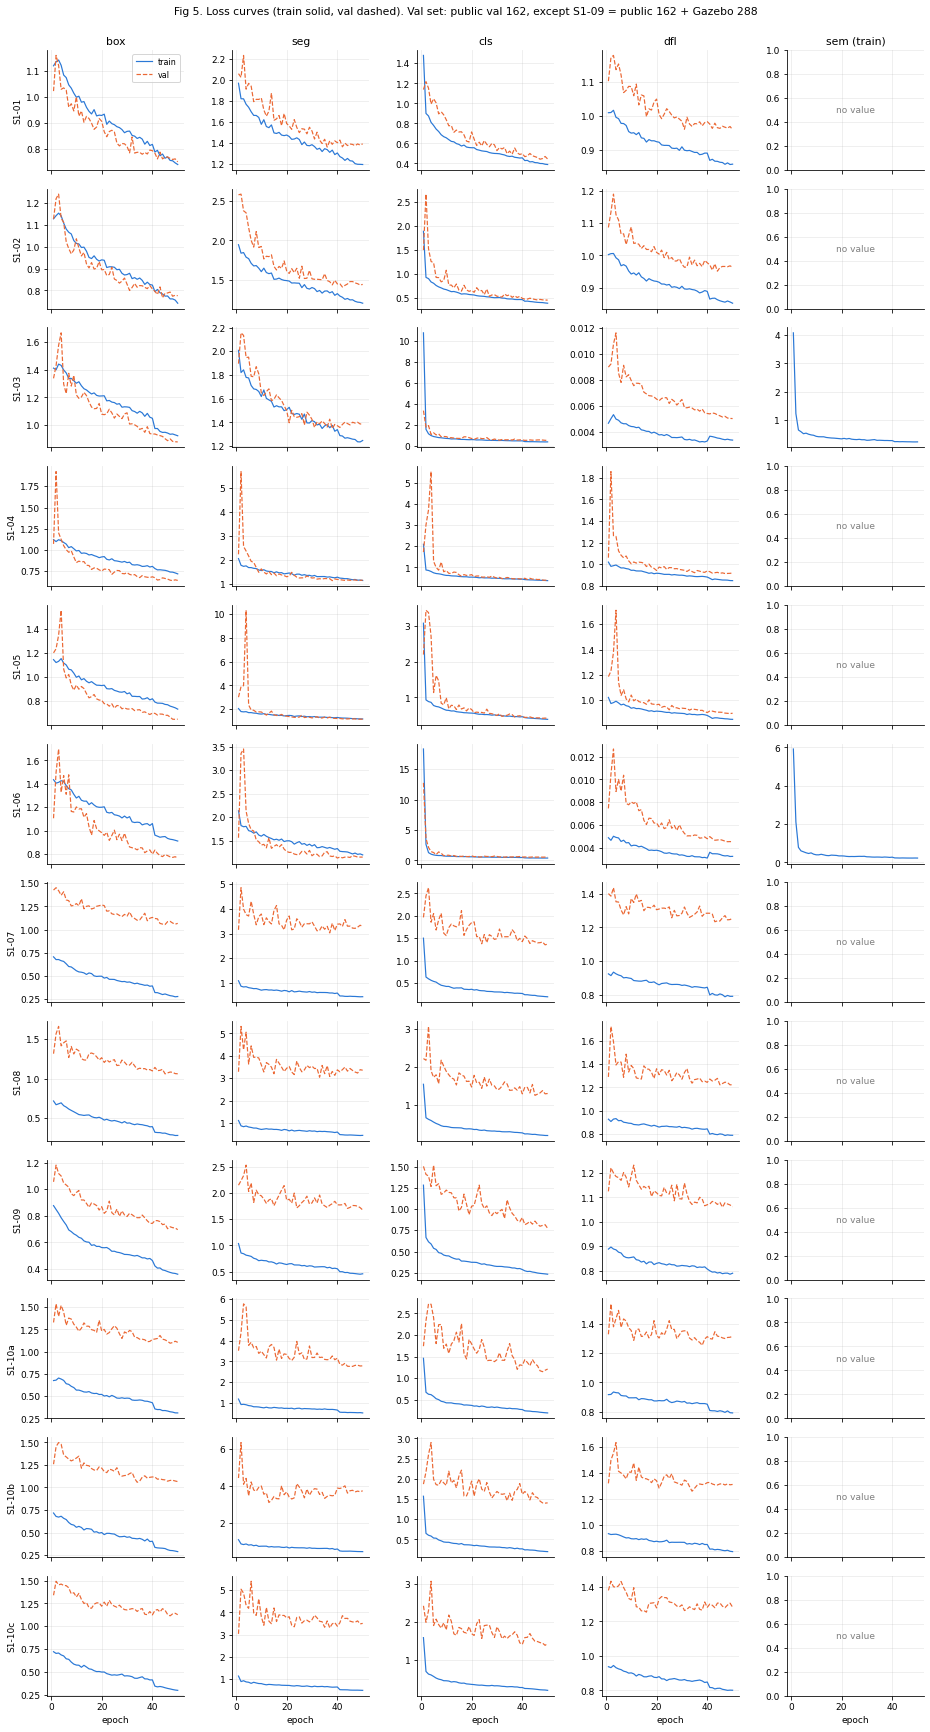

In [18]:
# 그림 5: 손실 곡선. 칸마다 학습(실선)·검증(점선)을 겹쳐 그린다. 행 = 실험, 열 = 손실 종류.
EXP_IDS = sorted(CURVES.exp.unique())
LOSS_COLS = [("box", "box_loss"), ("seg", "seg_loss"), ("cls", "cls_loss"), ("dfl / l1", None), ("sem (train)", "sem_loss")]
fig, axes = plt.subplots(len(EXP_IDS), len(LOSS_COLS), figsize=(13, 2.0 * len(EXP_IDS)), sharex=True, dpi=72)
for i, e in enumerate(EXP_IDS):
    g = CURVES[CURVES.exp == e].sort_values("epoch")
    for j, (title, col) in enumerate(LOSS_COLS):
        ax = axes[i, j]
        if col is None:   # YOLOv8·11은 dfl, YOLO26은 l1
            col = "dfl_loss" if g["train/dfl_loss"].notna().any() else "l1_loss"
            title = col.replace("_loss", "")
        tr, va = g.get(f"train/{col}"), g.get(f"val/{col}")
        if tr is not None and tr.notna().any() and tr.abs().sum() > 0:
            ax.plot(g.epoch, tr, color=C1, lw=1.2, label="train")
        if va is not None and va.notna().any() and va.abs().sum() > 0:
            ax.plot(g.epoch, va, color=C2, lw=1.2, ls="--", label="val")
        if not ax.lines:
            ax.text(0.5, 0.5, "no value", ha="center", va="center", transform=ax.transAxes, color="gray")
        if i == 0:
            ax.set_title(title)
        if j == 0:
            ax.set_ylabel(e)
        if i == len(EXP_IDS) - 1:
            ax.set_xlabel("epoch")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Fig 5. Loss curves (train solid, val dashed). Val set: public val 162, except S1-09 = public 162 + Gazebo 288", y=1.0)
fig.tight_layout()

lr/pg0 = pg1 = pg2 (모든 실험·에포크): True


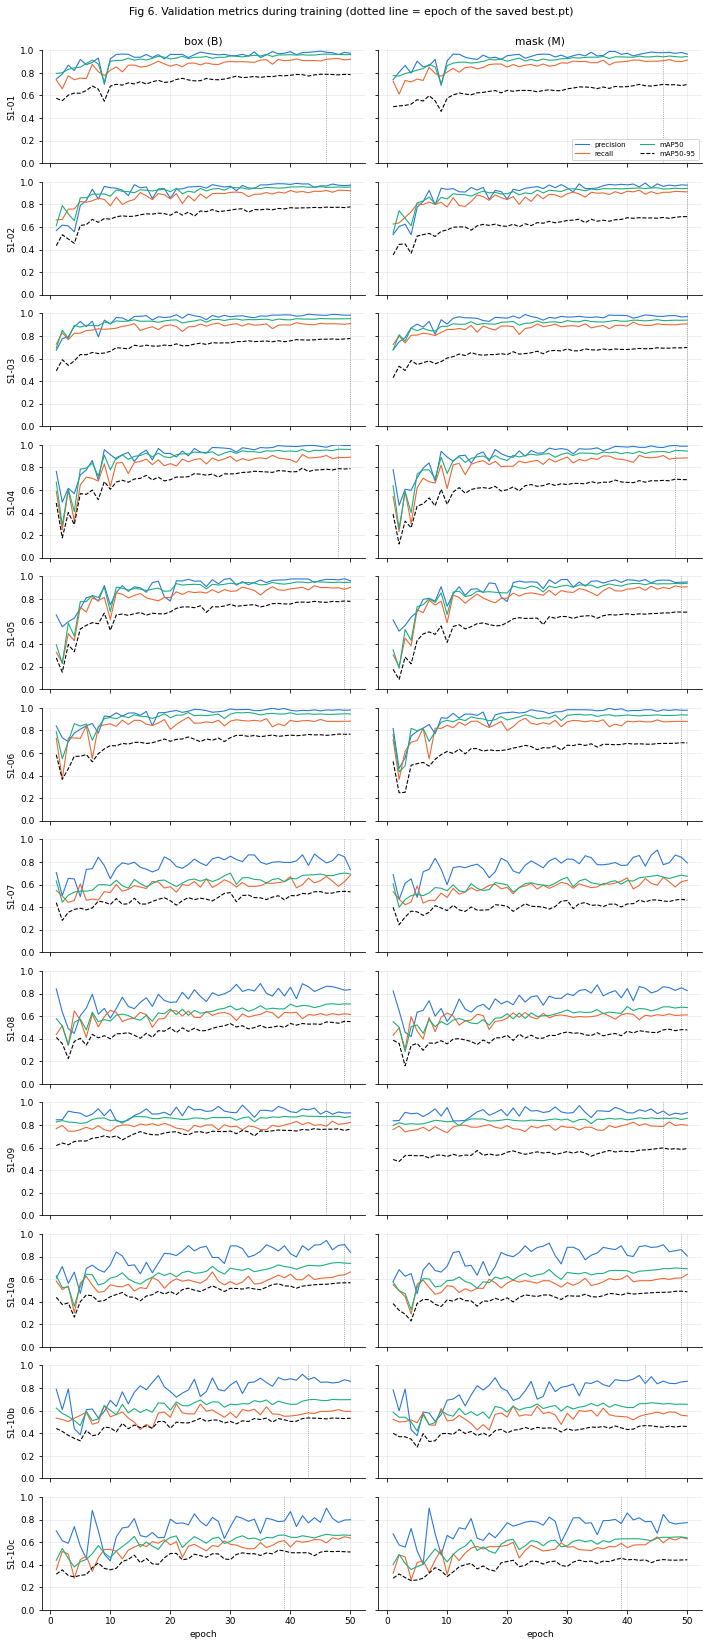

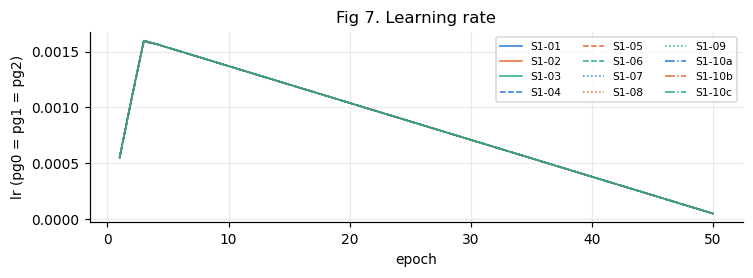

In [19]:
# 그림 6: 학습 중 검증 지표(박스 B·마스크 M). 그림 7: 학습률.
MET = [("precision", C1, "-"), ("recall", C2, "-"), ("mAP50", C3, "-"), ("mAP50-95", "black", "--")]
fig, axes = plt.subplots(len(EXP_IDS), 2, figsize=(10, 1.9 * len(EXP_IDS)), sharex=True, sharey=True, dpi=72)
for i, e in enumerate(EXP_IDS):
    g = CURVES[CURVES.exp == e].sort_values("epoch")
    for j, bm in enumerate(("B", "M")):
        ax = axes[i, j]
        for m, c, ls in MET:
            ax.plot(g.epoch, g[f"metrics/{m}({bm})"], color=c, ls=ls, lw=1.1, label=m)
        ax.axvline(BEST_EP[e], color="gray", lw=0.8, ls=":")
        ax.set_ylim(0, 1)
        if i == 0:
            ax.set_title("box (B)" if bm == "B" else "mask (M)")
        if j == 0:
            ax.set_ylabel(e)
axes[0, 1].legend(loc="lower right", fontsize=7, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel("epoch")
fig.suptitle("Fig 6. Validation metrics during training (dotted line = epoch of the saved best.pt)", y=1.0)
fig.tight_layout()

fig, ax = plt.subplots(figsize=(7, 2.6))
for k, e in enumerate(EXP_IDS):
    g = CURVES[CURVES.exp == e].sort_values("epoch")
    ax.plot(g.epoch, g["lr/pg0"], lw=1.0, color=[C1, C2, C3][k % 3], ls=["-", "--", ":", "-."][k // 3], label=e)
ax.set_xlabel("epoch")
ax.set_ylabel("lr (pg0 = pg1 = pg2)")
ax.set_title("Fig 7. Learning rate")
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()
same_pg = bool(((CURVES["lr/pg0"] - CURVES["lr/pg1"]).abs().max() == 0) and ((CURVES["lr/pg0"] - CURVES["lr/pg2"]).abs().max() == 0))
print("lr/pg0 = pg1 = pg2 (모든 실험·에포크):", same_pg)

In [20]:
# 실험별 최종·best 에포크, 손실, 일반화 격차(val − train), best 뒤 val 손실 상승(과적합 징후).
# best.pt 에포크: Ultralytics가 실제로 저장한 best.pt의 에포크(박스 mAP50-95 + 마스크 mAP50-95가 가장 큰 에포크, 위 셀의 BEST_EP).
#   「(best)」 열은 모두 이 에포크의 값이다. 마스크 mAP50-95만 가장 큰 에포크는 참고로 따로 적는다(S1-05·S1-08에서 다름).
# 과적합 징후 판정(이 표의 규칙): box·seg·cls 중 하나라도 마지막 val 손실이 그 손실의 최저값보다 5 % 넘게 높으면 「있음」.
def loss_table():
    rows = []
    for e in EXP_IDS:
        g = CURVES[CURVES.exp == e].sort_values("epoch").reset_index(drop=True)
        b = g[g.epoch == BEST_EP[e]].iloc[0]
        mask_top = g.loc[g["metrics/mAP50-95(M)"].idxmax()]
        f = g.iloc[-1]
        row = {"실험": e, "최종 에포크": int(f.epoch), "best.pt 에포크(박스+마스크 mAP50-95 합 최고)": int(b.epoch),
               "마스크 mAP50-95만 최고인 에포크": int(mask_top.epoch),
               "best.pt mAP50-95(M)": round(b["metrics/mAP50-95(M)"], 3), "최종 mAP50-95(M)": round(f["metrics/mAP50-95(M)"], 3)}
        signs = []
        for k in ("box", "seg", "cls"):
            tr, va = f"train/{k}_loss", f"val/{k}_loss"
            row[f"{k} train/val(best)"] = f"{b[tr]:.3f} / {b[va]:.3f}"
            row[f"{k} train/val(최종)"] = f"{f[tr]:.3f} / {f[va]:.3f}"
            row[f"{k} 격차(최종 val−train)"] = round(f[va] - f[tr], 3)
            vmin_i = g[va].idxmin()
            rise = f[va] - g.loc[vmin_i, va]
            row[f"val {k} 최저 에포크"] = int(g.loc[vmin_i, "epoch"])
            if rise > 0.05 * g.loc[vmin_i, va]:
                signs.append(f"{k} +{rise:.3f}(에포크 {int(g.loc[vmin_i, 'epoch'])} 뒤)")
        row["과적합 징후(val 손실 상승)"] = "있음: " + ", ".join(signs) if signs else "없음"
        rows.append(row)
    return pd.DataFrame(rows)


LOSS_TABLE = loss_table()
display(LOSS_TABLE[["실험", "최종 에포크", "best.pt 에포크(박스+마스크 mAP50-95 합 최고)", "마스크 mAP50-95만 최고인 에포크",
                    "best.pt mAP50-95(M)", "최종 mAP50-95(M)", "과적합 징후(val 손실 상승)"]])
display(LOSS_TABLE[["실험"] + [c for c in LOSS_TABLE.columns if "train/val" in c]])
display(LOSS_TABLE[["실험"] + [c for c in LOSS_TABLE.columns if "격차" in c or "최저" in c]])

,실험,최종 에포크,best.pt 에포크(박스+마스크 mAP50-95 합 최고),마스크 mAP50-95만 최고인 에포크,best.pt mAP50-95(M),최종 mAP50-95(M),과적합 징후(val 손실 상승)
0,S1-01,50,46,46,0.699,0.698,없음
1,S1-02,50,50,50,0.692,0.692,없음
2,S1-03,50,50,50,0.697,0.697,없음
3,S1-04,50,48,48,0.697,0.692,없음
4,S1-05,50,49,48,0.684,0.684,없음
5,S1-06,50,49,49,0.692,0.690,없음
6,S1-07,50,49,49,0.469,0.462,있음: seg +0.256(에포크 37 뒤)
7,S1-08,50,49,47,0.480,0.477,있음: seg +0.312(에포크 33 뒤)
8,S1-09,50,46,46,0.597,0.592,없음
9,S1-10a,50,49,49,0.493,0.488,있음: cls +0.060(에포크 48 뒤)


,실험,box train/val(best),box train/val(최종),seg train/val(best),seg train/val(최종),cls train/val(best),cls train/val(최종)
0,S1-01,0.768 / 0.768,0.739 / 0.749,1.227 / 1.386,1.194 / 1.392,0.406 / 0.458,0.389 / 0.444
1,S1-02,0.742 / 0.776,0.742 / 0.776,1.208 / 1.445,1.208 / 1.445,0.397 / 0.461,0.397 / 0.461
2,S1-03,0.924 / 0.880,0.924 / 0.880,1.247 / 1.389,1.247 / 1.389,0.388 / 0.531,0.388 / 0.531
3,S1-04,0.739 / 0.639,0.718 / 0.641,1.164 / 1.156,1.152 / 1.164,0.388 / 0.403,0.375 / 0.401
4,S1-05,0.743 / 0.647,0.732 / 0.649,1.190 / 1.170,1.184 / 1.167,0.394 / 0.425,0.389 / 0.413
5,S1-06,0.919 / 0.779,0.912 / 0.767,1.223 / 1.156,1.202 / 1.156,0.379 / 0.534,0.377 / 0.531
6,S1-07,0.273 / 1.058,0.276 / 1.067,0.448 / 3.336,0.451 / 3.283,0.195 / 1.351,0.191 / 1.366
7,S1-08,0.278 / 1.063,0.278 / 1.061,0.454 / 3.384,0.459 / 3.361,0.193 / 1.287,0.192 / 1.295
8,S1-09,0.381 / 0.703,0.362 / 0.696,0.468 / 1.762,0.459 / 1.676,0.248 / 0.822,0.234 / 0.773
9,S1-10a,0.312 / 1.117,0.311 / 1.105,0.535 / 2.779,0.520 / 2.785,0.203 / 1.185,0.199 / 1.213


,실험,box 격차(최종 val−train),val box 최저 에포크,seg 격차(최종 val−train),val seg 최저 에포크,cls 격차(최종 val−train),val cls 최저 에포크
0,S1-01,0.010,50,0.197,36,0.055,47
1,S1-02,0.034,44,0.237,42,0.064,50
2,S1-03,-0.044,50,0.142,38,0.144,50
3,S1-04,-0.077,48,0.013,38,0.026,49
4,S1-05,-0.083,49,-0.017,48,0.024,50
5,S1-06,-0.145,50,-0.046,40,0.153,43
6,S1-07,0.791,45,2.832,37,1.175,49
7,S1-08,0.782,45,2.902,33,1.104,45
8,S1-09,0.334,50,1.218,50,0.539,50
9,S1-10a,0.794,47,2.265,45,1.015,48


**곡선 읽기(위 표·그림 근거)**

- **S1-01~S1-06(학습 자료 = 원래 공개 분할)**
  - best.pt 에포크는 46~50입니다.
  - 마지막 val 손실이 최저값보다 5 % 넘게 오른 항목은 없습니다(표의 「과적합 징후」).
  - 다만 val seg 손실은 최저점(에포크 36~48) 뒤 0.015~0.041 올라 평평해집니다. 학습 seg 손실은 끝까지 내려갑니다.
  - S1-04~S1-06(batch 64)은 에포크 2~4에 val 손실이 크게 튑니다(seg 최대 약 10). 학습률 예열 구간이고, 에포크 6 무렵부터 안정됩니다(그림 5).
- **S1-07·S1-08(선별 자료 `clean_train_r1`)**
  - val seg 손실이 에포크 37·33에서 가장 낮고, 마지막에는 0.256·0.312 높습니다(약 +8 %·+10 %).
  - 같은 때 학습 seg 손실은 계속 내려가, 마지막 격차(val − train)가 2.83·2.90입니다. S1-01~06은 −0.05~0.24입니다.
  - 표 규칙으로 「과적합 징후 있음」입니다. 그래도 best.pt 에포크(둘 다 49)의 mAP50-95(M)는 마지막과 0.003~0.007만 다릅니다.
  - **해석(미분리):** 검증 세트는 S1-01~06과 같은 공개 val 162장입니다. 그런데 선별 자료는 desk 장면 612장을 학습에서 뺐습니다(§3.3).
    - 그래서 val 손실이 높고 오르는 것은 「같은 분포에 대한 과적합」보다 **학습에 없는 장면을 검증하는 격차**가 섞인 것으로 봅니다.
    - 공개 test mAP가 0.95대에서 0.55대로 떨어진 것(§6.3, 미확인 3)과 같은 원인 후보입니다.
- **S1-09(공개 val + Gazebo 조각 288장)**
  - best.pt 에포크는 46/50입니다.
  - val box·seg·cls 손실이 모두 마지막 에포크(50)에서 가장 낮습니다. box 1.055 → 0.696, seg 2.149 → 1.676, cls 1.502 → 0.773.
  - 학습·검증 기준 과적합 징후는 없습니다. 환경 과적합은 §7.9에 따로 적었습니다.
- **S1-10a·b·c(검증은 S1-08과 같은 공개 val 162장)**
  - best.pt 에포크는 49·43·39입니다.
  - **S1-10b:** val seg 손실이 에포크 13에서 가장 낮고(3.111) 마지막에 3.737로 20.1 % 높습니다. S1-08(+10.2 %)보다 일찍 바닥을 찍고 더 많이 올랐습니다. 그동안 val box 손실은 거의 그대로이고(+0.7 %) 검증 지표는 에포크 43까지 올랐습니다.
  - **S1-10c:** S1-10b와 같은 모양입니다. val seg 손실은 마지막에 3.505이고 학습과의 격차는 3.02입니다. 표의 최저 에포크 1(3.033)은 학습 초반에 크게 흔들린 값이라 의미 있는 최저점이 아닙니다.
  - **S1-10a:** val seg 손실이 에포크 45까지 내려가고(2.759) 마지막에 +1.0 %입니다. 격차도 2.27로 가장 작습니다. S1-07·S1-08·S1-10b·c에서 보이는 seg 손실 상승이 없습니다. 표 규칙으로는 cls 손실(+5.2 %) 때문에 「있음」으로 나옵니다.
  - 실사진 검증에서 가장 나은 S1-10a가 Gazebo 판정에서는 가장 나빴습니다(§7.1.1). 공개 val 곡선만으로는 Gazebo 영상의 작은 물체 성능을 알 수 없습니다.
- **학습률:** 세 묶음(pg0~2)이 같고, 모든 실험이 첫 3 에포크 예열(최고 약 0.0016) 뒤 선형으로 줄어 50 에포크에 0.00005가 됩니다. 실험 사이 차이는 예열 구간 0.00001 이하입니다(그림 7).

## 7. 평가

### 7.1 미리 고정한 합격 기준(S1-09 재학습 판정, #275 §6)

결과를 보기 전에 A가 기준을 고정했고(#275 r0 §6), 기준값은 바꾸지 않았습니다. **다만 D0은 결과 뒤 분모를 24 → 15로 바꿔 비율로 적용했습니다**(아래 표 주). 운영 조건(conf 0.05, imgsz 1280, M2 끝점 추출)에서 쟀습니다.

- **D0:** 영상에서 가로로 놓인 M3×20(yaw 67.5~112.5°) 검출
- **mAP:** 공개 test mAP50(회귀 확인)
- **P95 추론 시간:** 1280 ≤ 25 ms
- **오검출:** 실시간 경로(E3)에서 상자 테두리 확정 0, 그림자·손가락 집기 목표 0

세트 E1(새 판정 세트)·E2(#267 V2 촬영 120장 재추론)·E3(실시간 재실측 3조건)로 판정했고, 링크 v2·gz_eval_v1·공개 test는 회귀 확인용입니다.

In [21]:
# #278 판정표. 출처: _workspace/278_builder3_report.md §2 (기준은 _workspace/275_builder3_retrain_plan_r0.md §6)
gate = pd.DataFrame([
    ("D0 가로 M3×20 검출", "E2", "1/15", "15/15", "≥ 20/24 (83 %)", "통과"),
    ("M3×20 끝점까지 통과", "E2 단독", "13/40", "30/40", "기록(목표 ≥ 20/32)", "목표 넘음"),
    ("M6×40 통과", "E2 단독/함께", "30/40 / 37/40", "32/40 / 40/40", "≥ 30/32, 회귀 금지", "통과"),
    ("상자 테두리 오검출 확정", "E3 3조건", "11·15·13번", "0·0·0", "0", "통과"),
    ("그림자·손가락 집기 목표", "E3 3조건", "0·2·0", "0·0·0", "0", "통과"),
    ("볼트 재현율 / B 오검출", "링크 v2 conf 0.05", "425/442 / 14", "441/442 / 1", "≥ 420/442, ≤ 1", "통과"),
    ("볼트/너트 재현율 1280", "gz_eval_v1 conf 0.25", "0.87/0.97", "0.90/1.00", "각 −0.02 이내", "통과"),
    ("공개 test mAP50 박스/마스크", "eval 640", "0.554/0.546", "0.562/0.556", "≥ 0.524/0.516", "통과"),
    ("E1 재현율 M3×20/M6×12/M6×40/NUT", "E1", "0.553/0.930/0.894/0.948", "1.000/1.000/0.994/1.000", "기록", "기록"),
    ("추론 P95 1280", "timing / E3 실측", "21.6 / 21.4~21.6 ms", "13.0 / 20.4~23.2 ms", "≤ 25 ms", "통과"),
], columns=["지표", "세트", "S1-08", "S1-09", "합격 기준", "판정"]).set_index("지표")
display(gate)
print("주: S1-08 B 오검출 14 = 너트 9 + 같은 볼트 2중 4 + 위치 1 (#278 표의 NUT 9·DUP 4·LOC 1).")
print("주(D0 분모): 기준 '≥ 20/24'의 24는 #275가 #267 V2 자료 m3·both 두 조건 합산, 시야 안 4줄(y −0.05~+0.40) × 가로 yaw 3개로 센 값입니다(#275 §2.1, 정의는 기록 대조 추정).")
print("          판정에 쓴 E2의 15는 단독 조건 1개, y 5줄 × yaw 3개(가장자리 잘림 3행 포함)입니다(#278 ※1).")
print("          결과를 본 뒤 분모를 15로 바꿔 비율(≥ 83 %)로 적용했으므로, '기준 무변'이 아니라 '기준 적용 방식 변경'입니다. 15/15는 24행 기준으로도 넘을지 확인하지 않았습니다.")
print("주(P95): S1-08·S1-09는 같은 구조·같은 크기라 timing 21.6 대 13.0 ms는 측정 시점 차이로 봅니다. 실시간 E3 값이 대표입니다.")

,세트,S1-08,S1-09,합격 기준,판정
지표,,,,,
D0 가로 M3×20 검출,E2,1/15,15/15,≥ 20/24 (83 %),통과
M3×20 끝점까지 통과,E2 단독,13/40,30/40,기록(목표 ≥ 20/32),목표 넘음
M6×40 통과,E2 단독/함께,30/40 / 37/40,32/40 / 40/40,"≥ 30/32, 회귀 금지",통과
상자 테두리 오검출 확정,E3 3조건,11·15·13번,0·0·0,0,통과
그림자·손가락 집기 목표,E3 3조건,0·2·0,0·0·0,0,통과
볼트 재현율 / B 오검출,링크 v2 conf 0.05,425/442 / 14,441/442 / 1,"≥ 420/442, ≤ 1",통과
볼트/너트 재현율 1280,gz_eval_v1 conf 0.25,0.87/0.97,0.90/1.00,각 −0.02 이내,통과
공개 test mAP50 박스/마스크,eval 640,0.554/0.546,0.562/0.556,≥ 0.524/0.516,통과
E1 재현율 M3×20/M6×12/M6×40/NUT,E1,0.553/0.930/0.894/0.948,1.000/1.000/0.994/1.000,기록,기록


주: S1-08 B 오검출 14 = 너트 9 + 같은 볼트 2중 4 + 위치 1 (#278 표의 NUT 9·DUP 4·LOC 1).
주(D0 분모): 기준 '≥ 20/24'의 24는 #275가 #267 V2 자료 m3·both 두 조건 합산, 시야 안 4줄(y −0.05~+0.40) × 가로 yaw 3개로 센 값입니다(#275 §2.1, 정의는 기록 대조 추정).
          판정에 쓴 E2의 15는 단독 조건 1개, y 5줄 × yaw 3개(가장자리 잘림 3행 포함)입니다(#278 ※1).
          결과를 본 뒤 분모를 15로 바꿔 비율(≥ 83 %)로 적용했으므로, '기준 무변'이 아니라 '기준 적용 방식 변경'입니다. 15/15는 24행 기준으로도 넘을지 확인하지 않았습니다.
주(P95): S1-08·S1-09는 같은 구조·같은 크기라 timing 21.6 대 13.0 ms는 측정 시점 차이로 봅니다. 실시간 E3 값이 대표입니다.


### 7.1.1 S1-10 회전 실험 판정(#348·#350·#353)

- **기준:** S1-10b 학습 전에 6개를 정했고(#348 계획 §5.1), S1-10a에도 그대로 썼습니다. S1-10c에는 결과를 보기 전에 2개를 더했습니다(가로 M3×20 유지 ≥ 14/15, 상자 벽 테두리 오검출 ≤ 1).
- **조건:** 가로 M3×20·M6×40·링크 카메라 세트는 운영 조건(입력 1280, 신뢰도 0.05)입니다. Gazebo 재현율과 공개 test는 학습기 평가 조건(신뢰도 0.25)입니다.
- **가로 M3×20의 분모:** #267에서 다시 찍은 영상 중 M3×20만 놓은 장면에서 yaw 67.5°·90°·112.5° × 자리 5곳 = 15장입니다(가장자리에서 잘린 3장 포함). §7.1의 S1-09 판정에 쓴 15장과 같은 장면입니다.
- **값의 출처:** `docs/reports/data/s1_10_gate.json`입니다. 재촬영 영상 분석 행, 링크 카메라 세트 평가, 학습기 `eval.json`에서 다시 세었고, 각 실험 보고의 판정표 원값과 같음을 확인했습니다. 원자료 경로와 sha256이 같은 파일에 있습니다.

In [22]:
# S1-10 판정표. 출처: docs/reports/data/s1_10_gate.json (기준은 학습 전에 고정, S1-10c의 추가 2개는 #353 계획)
M = GATE["models"]
ORDER = ["S1-08", "S1-09", "S1-10a", "S1-10b", "S1-10c"]


def frac(v):
    return f"{v[0]}/{v[1]}"


def te(m):
    return M[m]["trainer_eval"]


# (지표, 세트, 값을 글로, 합격 기준, 통과 여부) — 통과 여부는 실험 이름과 그 모델 값으로 판단
ITEMS = [
    ("가로 M3×20 검출", "재촬영 영상, M3 단독 15장", lambda m: frac(M[m]["e2"]["horizontal_m3_detected"]), "≥ 13/15",
     lambda m: M[m]["e2"]["horizontal_m3_detected"][0] >= 13),
    ("M6×40 끝점까지 통과", "재촬영 영상, M6 단독 화면 안 32장", lambda m: frac(M[m]["e2"]["m6x40_endpoint_pass"]), "≥ 30/32",
     lambda m: M[m]["e2"]["m6x40_endpoint_pass"][0] >= 30),
    ("링크 세트 볼트 검출 / 잘못 넘긴 볼트", "링크 카메라 200장, 볼트 442",
     lambda m: f'{M[m]["link"]["bolts_found"]} / {M[m]["link"]["wrong_bolt_predictions"]}', "≥ 420 / ≤ 1",
     lambda m: M[m]["link"]["bolts_found"] >= 420 and M[m]["link"]["wrong_bolt_predictions"] <= 1),
    ("Gazebo 재현율 볼트 / 너트", "gz_eval_v1 1280, 신뢰도 0.25",
     lambda m: f'{te(m)["gz1280_recall"]["bolt"]:.3f} / {te(m)["gz1280_recall"]["nut"]:.3f}', "≥ 0.85 / ≥ 0.95",
     lambda m: te(m)["gz1280_recall"]["bolt"] >= 0.85 and te(m)["gz1280_recall"]["nut"] >= 0.95),
    ("공개 test mAP50 박스 / 마스크", "161장, 640", lambda m: f'{te(m)["test640_map50_box"]:.3f} / {te(m)["test640_map50_mask"]:.3f}',
     "≥ 0.524 / ≥ 0.516", lambda m: te(m)["test640_map50_box"] >= 0.524 and te(m)["test640_map50_mask"] >= 0.516),
    ("추론 P95(1280)", "학습기 시간 측정 200회", lambda m: f'{te(m)["p95_1280_ms"]:.1f} ms', "≤ 25 ms", lambda m: te(m)["p95_1280_ms"] <= 25.0),
]
ITEMS_C = [
    ("가로 M3×20 유지(S1-10c만)", "위 15장", lambda m: frac(M[m]["e2"]["horizontal_m3_detected"]), "≥ 14/15",
     lambda m: M[m]["e2"]["horizontal_m3_detected"][0] >= 14),
    ("상자 벽 테두리 오검출(S1-10c만 기준)", "링크 카메라 200장", lambda m: str(M[m]["box_wall"]["box_wall"]), "≤ 1",
     lambda m: M[m]["box_wall"]["box_wall"] <= 1),
]
gate10 = pd.DataFrame([{"지표": name, "세트": where, **{m: text(m) for m in ORDER}, "합격 기준": crit}
                       for name, where, text, crit, _ in ITEMS + ITEMS_C]).set_index("지표")
display(gate10)

verdict = pd.DataFrame([{"지표": name, **{m: ("통과" if ok(m) else "불합격") if (m == "S1-10c" or (name, where, text, crit, ok) in ITEMS) else "기준 아님(기록)"
                                          for m in S10}}
                        for name, where, text, crit, ok in ITEMS + ITEMS_C]).set_index("지표")
display(verdict)
for m in S10:
    col = verdict[m]
    print(f"{m}: 기준 {int((col != '기준 아님(기록)').sum())}개 중 불합격 {int((col == '불합격').sum())}개")

# 판정 밖 기록: M3×20 끝점 통과, 방향별 검출, 잘못 넘긴 볼트의 내역, E1(현재 월드 200장) 재현율
CAT = {"TP": "맞음", "BG": "배경(상자 벽 등)", "NUT": "너트 위", "DUP": "같은 볼트 중복", "LOC": "위치 틀림"}
rec = pd.DataFrame([{"실험": m, "M3×20 끝점까지 통과": frac(M[m]["e2"]["m3_endpoint_pass"]),
                     **{f"yaw {float(y):g}°": frac(v) for y, v in M[m]["e2"]["m3_detected_by_yaw"].items()}} for m in ORDER]).set_index("실험")
display(rec)
cats = pd.DataFrame([{"실험": m, **{CAT[k]: v for k, v in M[m]["link"]["bolt_prediction_categories"].items()},
                      "상자 벽 테두리": M[m]["box_wall"]["box_wall"]} for m in ORDER]).set_index("실험").fillna(0).astype(int)
display(cats[[c for c in ("맞음", "배경(상자 벽 등)", "너트 위", "같은 볼트 중복", "위치 틀림", "상자 벽 테두리") if c in cats.columns]])
e1 = pd.DataFrame([{"실험": m, **{k: round(v["recall"], 3) for k, v in M[m]["e1"]["recall"].items()},
                    "볼트 오검출": M[m]["e1"]["false_positives"].get("bolt", 0)} for m in ORDER]).set_index("실험")
display(e1)
print("주(방향별 검출): 위 표는 M3×20 단독 40장을 yaw별 5장씩 센 것입니다. 가로는 67.5°·90°·112.5°입니다.")
print("주(잘못 넘긴 볼트): 정답 볼트와 맞지 않은 볼트 예측 수입니다. 「상자 벽 테두리」는 배경 오검출 중 영상 왼쪽 아래(x ≤ 100, y ≥ 520 px) 안에 있는 것입니다.")
print("    S1-08의 상자 벽 값은 #348에서 같은 세트를 다시 돌린 결과로 센 것이고, S1-09는 #350 집계에 있습니다.")
print("주(E1): 현재 월드 200장(#278의 S1-09 판정 세트)입니다. 판정에는 쓰지 않은 기록입니다.")
print("주(P95): 다섯 모델은 구조와 입력 크기가 같습니다. S1-10a의 1280 중앙값은 "
      f"{te('S1-10a')['median_1280_ms']:.1f} ms이고 P95만 큽니다. 측정 때 부하 영향으로 보이나 다시 재지 않았고 판정은 그대로 둡니다.")

,세트,S1-08,S1-09,S1-10a,S1-10b,S1-10c,합격 기준
지표,,,,,,,
가로 M3×20 검출,"재촬영 영상, M3 단독 15장",1/15,15/15,0/15,14/15,9/15,≥ 13/15
M6×40 끝점까지 통과,"재촬영 영상, M6 단독 화면 안 32장",30/32,32/32,30/32,29/32,31/32,≥ 30/32
링크 세트 볼트 검출 / 잘못 넘긴 볼트,"링크 카메라 200장, 볼트 442",425 / 14,441 / 1,339 / 3,414 / 253,422 / 72,≥ 420 / ≤ 1
Gazebo 재현율 볼트 / 너트,"gz_eval_v1 1280, 신뢰도 0.25",0.874 / 0.968,0.903 / 0.995,0.892 / 0.804,0.896 / 0.886,0.854 / 0.968,≥ 0.85 / ≥ 0.95
공개 test mAP50 박스 / 마스크,"161장, 640",0.554 / 0.546,0.562 / 0.556,0.573 / 0.558,0.573 / 0.566,0.551 / 0.527,≥ 0.524 / ≥ 0.516
추론 P95(1280),학습기 시간 측정 200회,21.6 ms,13.0 ms,29.7 ms,15.3 ms,20.5 ms,≤ 25 ms
가로 M3×20 유지(S1-10c만),위 15장,1/15,15/15,0/15,14/15,9/15,≥ 14/15
상자 벽 테두리 오검출(S1-10c만 기준),링크 카메라 200장,0,0,0,200,0,≤ 1


,S1-10a,S1-10b,S1-10c
지표,,,
가로 M3×20 검출,불합격,통과,불합격
M6×40 끝점까지 통과,통과,불합격,통과
링크 세트 볼트 검출 / 잘못 넘긴 볼트,불합격,불합격,불합격
Gazebo 재현율 볼트 / 너트,불합격,불합격,통과
공개 test mAP50 박스 / 마스크,통과,통과,통과
추론 P95(1280),불합격,통과,통과
가로 M3×20 유지(S1-10c만),기준 아님(기록),기준 아님(기록),불합격
상자 벽 테두리 오검출(S1-10c만 기준),기준 아님(기록),기준 아님(기록),통과


S1-10a: 기준 6개 중 불합격 4개
S1-10b: 기준 6개 중 불합격 3개
S1-10c: 기준 8개 중 불합격 3개


,M3×20 끝점까지 통과,yaw 0°,yaw 22.5°,yaw 45°,yaw 67.5°,yaw 90°,yaw 112.5°,yaw 135°,yaw 157.5°
실험,,,,,,,,,
S1-08,13/40,5/5,4/5,4/5,0/5,0/5,1/5,4/5,5/5
S1-09,30/40,5/5,5/5,5/5,5/5,5/5,5/5,5/5,5/5
S1-10a,2/40,0/5,0/5,0/5,0/5,0/5,0/5,1/5,1/5
S1-10b,24/40,5/5,5/5,5/5,5/5,4/5,5/5,5/5,5/5
S1-10c,24/40,5/5,5/5,5/5,5/5,0/5,4/5,5/5,5/5


,맞음,배경(상자 벽 등),너트 위,같은 볼트 중복,위치 틀림,상자 벽 테두리
실험,,,,,,
S1-08,425,0,9,4,1,0
S1-09,441,0,0,0,1,0
S1-10a,339,0,0,2,1,0
S1-10b,414,204,8,17,24,200
S1-10c,422,1,64,4,3,0


,BOLT_M3X20,BOLT_M6X12,BOLT_M6X40,NUT_M6,볼트 오검출
실험,,,,,
S1-08,0.553,0.930,0.894,0.948,122
S1-09,1.000,1.000,0.994,1.000,0
S1-10a,0.207,0.747,0.856,0.341,24
S1-10b,0.800,0.944,0.944,0.931,63
S1-10c,0.676,0.944,0.944,0.919,54


주(방향별 검출): 위 표는 M3×20 단독 40장을 yaw별 5장씩 센 것입니다. 가로는 67.5°·90°·112.5°입니다.
주(잘못 넘긴 볼트): 정답 볼트와 맞지 않은 볼트 예측 수입니다. 「상자 벽 테두리」는 배경 오검출 중 영상 왼쪽 아래(x ≤ 100, y ≥ 520 px) 안에 있는 것입니다.
    S1-08의 상자 벽 값은 #348에서 같은 세트를 다시 돌린 결과로 센 것이고, S1-09는 #350 집계에 있습니다.
주(E1): 현재 월드 200장(#278의 S1-09 판정 세트)입니다. 판정에는 쓰지 않은 기록입니다.
주(P95): 다섯 모델은 구조와 입력 크기가 같습니다. S1-10a의 1280 중앙값은 7.0 ms이고 P95만 큽니다. 측정 때 부하 영향으로 보이나 다시 재지 않았고 판정은 그대로 둡니다.


### 7.2 실험별 그림

**그림 1.** 실험별 재현율과 공개 test 마스크 mAP50입니다. 왼쪽은 Gazebo 평가 세트 `gz_eval_v1`(1280 추론, conf 0.25)의 볼트·너트 재현율, 오른쪽은 공개 test(640) 마스크 mAP50입니다.

- S1-01~06(재분할 v2 전체로 학습)은 공개 test가 높지만 Gazebo 볼트 재현율이 낮습니다.
- S1-07~09(선별 자료)는 반대입니다. 공개 test가 0.55 안팎으로 떨어진 원인은 확인하지 않았습니다(미확인). 가능한 설명은 셋이고 무게를 가리지 못했습니다.
  - 학습에서 빠진 desk 612장과 줄어든 너트(1,685 → 140개)가 test 장면과 겹침
  - test 라벨 자체의 결함(확정 12행, 교차 클래스 2쌍, §3.5)이 평가를 오염시킴
  - 선별 자료의 장면 편중(학습 영상의 81 %가 z-hash 계열)

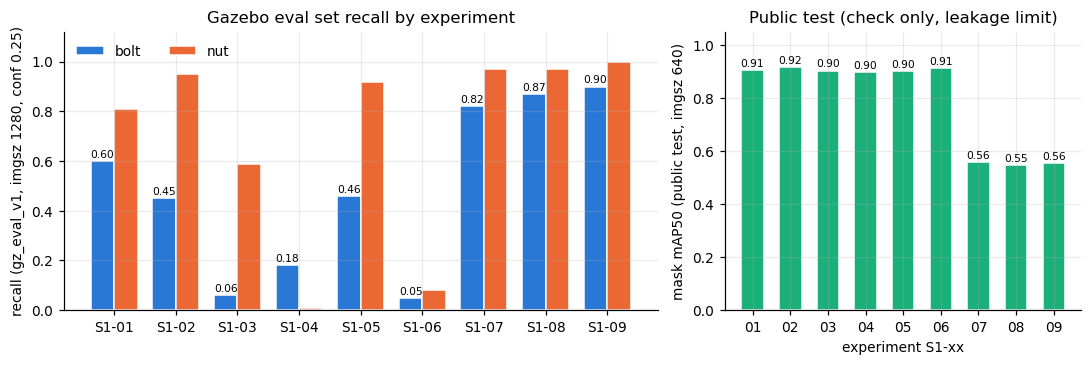

In [23]:
# 그림 1: 실험별 Gazebo 재현율(볼트·너트)과 공개 test 마스크 mAP50
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1.2]})
x = range(len(EXPS))
w = 0.38
b1 = ax1.bar([i - w / 2 for i in x], EXPS["gz1280 볼트"], w, color=C1, label="bolt", edgecolor="white", linewidth=1)
b2 = ax1.bar([i + w / 2 for i in x], EXPS["gz1280 너트"], w, color=C2, label="nut", edgecolor="white", linewidth=1)
ax1.bar_label(b1, fmt="%.2f", fontsize=7, padding=1)
ax1.set_xticks(list(x), EXPS.index, rotation=0)
ax1.set_ylim(0, 1.12)
ax1.set_ylabel("recall (gz_eval_v1, imgsz 1280, conf 0.25)")
ax1.set_title("Gazebo eval set recall by experiment")
ax1.legend(loc="upper left", frameon=False, ncol=2)
b3 = ax2.bar(list(x), EXPS["공개 mAP50 마스크"], 0.6, color=C3, edgecolor="white", linewidth=1)
ax2.bar_label(b3, fmt="%.2f", fontsize=7, padding=1)
ax2.set_xticks(list(x), [s.replace("S1-", "") for s in EXPS.index])
ax2.set_xlabel("experiment S1-xx")
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("mask mAP50 (public test, imgsz 640)")
ax2.set_title("Public test (check only, leakage limit)")
plt.tight_layout()
plt.show()

**그림 2.** 실험별 추론 P95(측정 도구, batch 1, GPU RTX 5080)와 학습 시간입니다. 두 값은 단위가 달라 따로 그렸습니다.

- 1280 P95가 S1-09 판정 기준 25 ms 아래인 실험은 S1-02·S1-04·S1-07·S1-08·S1-09입니다. 실시간 경로(E3)에서 S1-08·S1-09의 P95는 20.4~23.2 ms였습니다(#278).
- YOLO26n-seg(S1-03·S1-06)는 학습이 가장 오래 걸렸고 추론도 가장 느렸습니다.
- **S1-07~09는 같은 구조(YOLOv8n-seg)·같은 가중치 크기(7,041,268 B)입니다.** 이들 사이 P95 차이(7.9~21.6 ms, 13.0 ms 등)는 측정 시점의 GPU 부하 차이로 보고 모델 차이로 해석하지 않습니다. 실시간 E3에서는 S1-08 21.4~21.6 ms, S1-09 20.4~23.2 ms로 같습니다(#278).

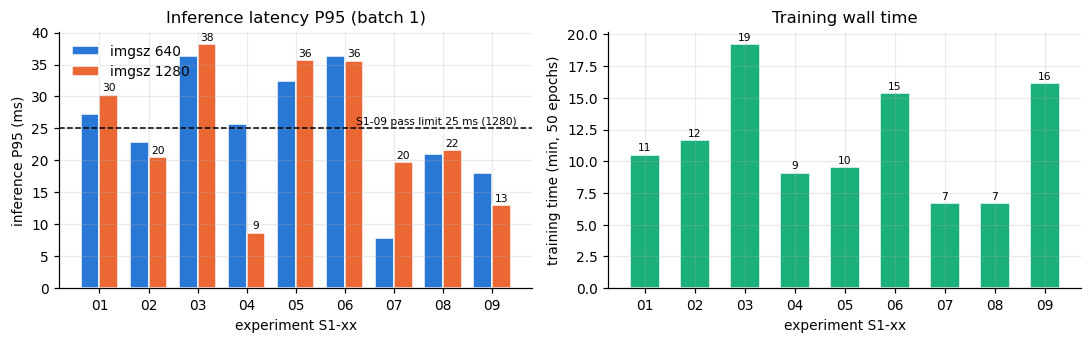

In [24]:
# 그림 2: 추론 P95(640·1280)와 학습 시간
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
x = list(range(len(EXPS)))
w = 0.38
ax1.bar([i - w / 2 for i in x], EXPS["P95 640 ms"], w, color=C1, label="imgsz 640", edgecolor="white", linewidth=1)
b = ax1.bar([i + w / 2 for i in x], EXPS["P95 1280 ms"], w, color=C2, label="imgsz 1280", edgecolor="white", linewidth=1)
ax1.bar_label(b, fmt="%.0f", fontsize=7, padding=1)
ax1.axhline(25, color="black", lw=1, ls="--")
ax1.text(len(x) - 0.5, 25.6, "S1-09 pass limit 25 ms (1280)", ha="right", fontsize=7)
ax1.set_xticks(x, [s.replace("S1-", "") for s in EXPS.index])
ax1.set_xlabel("experiment S1-xx")
ax1.set_ylabel("inference P95 (ms)")
ax1.set_title("Inference latency P95 (batch 1)")
ax1.legend(frameon=False, loc="upper left")
b = ax2.bar(x, EXPS["학습 s"] / 60, 0.6, color=C3, edgecolor="white", linewidth=1)
ax2.bar_label(b, fmt="%.0f", fontsize=7, padding=1)
ax2.set_xticks(x, [s.replace("S1-", "") for s in EXPS.index])
ax2.set_xlabel("experiment S1-xx")
ax2.set_ylabel("training time (min, 50 epochs)")
ax2.set_title("Training wall time")
plt.tight_layout()
plt.show()

### 7.3 conf 비교

- 실행 conf는 0.05입니다. **0.05를 고른 경위 문서는 찾지 못했습니다(미확인, #219에서도 같은 결론).**
- 아래는 링크 카메라 세트 `gz_eval_green_link_v2`(팔에 달린 실제 링크 카메라, 200장, 볼트 442·너트 236)에서 S1-08의 conf를 바꿔 잰 결과입니다(출처 `outputs/conf_sweep/s107_s108_green_link_20261117_110321_89c80b/summary.tsv`, Git 제외).
- 이 표의 conf 0.05 볼트 TP 424는 모델 카드의 425/442와 1개 다릅니다. 425는 #219의 A 실행 경로 집계이고, 424는 평가 도구(`eval_size_recall.py`) 집계입니다. 차이의 원인은 확인하지 않았습니다(미확인).

**그림 3.** S1-08 conf별 재현율·정밀도(링크 v2). 세로 점선은 실행값 0.05와 평가 기본값 0.25입니다.

recall        precision          fp    
class   bolt    nut      bolt    nut bolt nut
conf                                         
0.025  0.971  0.992     0.664  0.971  217   7
0.050  0.959  0.953     0.975  0.978   11   5
0.075  0.952  0.932     0.975  0.982   11   4
0.100  0.948  0.903     0.986  0.986    6   3
0.150  0.932  0.864     0.993  0.990    3   2
0.200  0.919  0.818     0.993  0.995    3   1
0.250  0.905  0.754     0.993  1.000    3   0
0.350  0.885  0.653     0.992  1.000    3   0
0.500  0.851  0.513     0.995  1.000    2   0
0.625  0.814  0.352     0.997  1.000    1   0
0.700  0.776  0.267     0.997  1.000    1   0

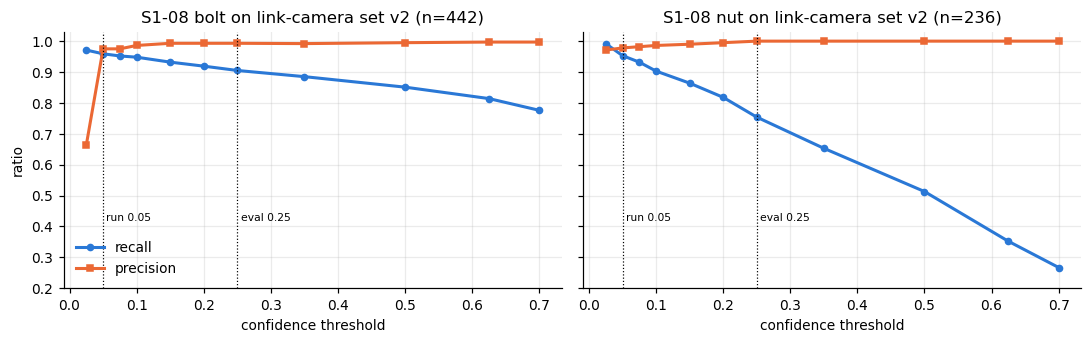

In [25]:
# S1-08 링크 v2 conf 비교. 출처: outputs/conf_sweep/s107_s108_green_link_20261117_110321_89c80b/summary.tsv
sweep = pd.DataFrame([
    # conf, class, gt, tp, pred
    (0.025, "bolt", 442, 429, 646), (0.025, "nut", 236, 234, 241),
    (0.05, "bolt", 442, 424, 435), (0.05, "nut", 236, 225, 230),
    (0.075, "bolt", 442, 421, 432), (0.075, "nut", 236, 220, 224),
    (0.1, "bolt", 442, 419, 425), (0.1, "nut", 236, 213, 216),
    (0.15, "bolt", 442, 412, 415), (0.15, "nut", 236, 204, 206),
    (0.2, "bolt", 442, 406, 409), (0.2, "nut", 236, 193, 194),
    (0.25, "bolt", 442, 400, 403), (0.25, "nut", 236, 178, 178),
    (0.35, "bolt", 442, 391, 394), (0.35, "nut", 236, 154, 154),
    (0.5, "bolt", 442, 376, 378), (0.5, "nut", 236, 121, 121),
    (0.625, "bolt", 442, 360, 361), (0.625, "nut", 236, 83, 83),
    (0.7, "bolt", 442, 343, 344), (0.7, "nut", 236, 63, 63),
], columns=["conf", "class", "gt_n", "tp", "pred_n"])
sweep["fp"] = sweep["pred_n"] - sweep["tp"]
sweep["recall"] = (sweep["tp"] / sweep["gt_n"]).round(3)
sweep["precision"] = (sweep["tp"] / sweep["pred_n"]).round(3)
display(sweep.pivot(index="conf", columns="class", values=["recall", "precision", "fp"]).astype({("fp", "bolt"): int, ("fp", "nut"): int}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, cls in zip(axes, ("bolt", "nut")):
    d = sweep[sweep["class"] == cls]
    ax.plot(d["conf"], d["recall"], color=C1, lw=2, marker="o", ms=4, label="recall")
    ax.plot(d["conf"], d["precision"], color=C2, lw=2, marker="s", ms=4, label="precision")
    for c in (0.05, 0.25):
        ax.axvline(c, color="black", lw=0.8, ls=":")
    ax.text(0.055, 0.42, "run 0.05", fontsize=7)
    ax.text(0.255, 0.42, "eval 0.25", fontsize=7)
    ax.set_title(f"S1-08 {cls} on link-camera set v2 (n={int(d['gt_n'].iloc[0])})")
    ax.set_xlabel("confidence threshold")
    ax.set_ylim(0.2, 1.03)
axes[0].set_ylabel("ratio")
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

- conf 0.05는 볼트 재현율 0.96·정밀도 0.97입니다. 0.025로 더 낮추면 볼트 오검출이 11 → 217개로 크게 늘어납니다.
- 너트는 conf를 올리면 재현율이 빠르게 떨어집니다(0.25에서 0.75). 낮은 conf가 너트에 유리합니다.
- 같은 conf를 고정 경사 세트 `gz_eval_v1`에 쓰면 볼트 오검출이 294개(0.05)입니다(`outputs/conf_sweep/s107_s108_low_20261117_100024_305a31/`). 실행 경로에서는 끝점 자격·벨트 밖 제외·팔 영역 제외·W 추적 확정이 이를 거릅니다(A 상세 §7.2~§7.4).

### 7.4 Gazebo 링크 카메라 평가와 S1-08 vs S1-09

- **링크 v2 200장(#146):** 팔에 달린 링크 카메라의 실제 입력으로 모은 초록 벨트 평가 자료입니다(볼트 442·너트 236). 옛 상자 배치라 상자 테두리·팔 그림자는 없습니다(#275 §3.2).
- **V2 촬영 120장(#267):** 팔 HOME에서 M3×20·M6×40을 위치 × yaw로 놓고 찍었습니다. D0 미검출을 처음 찾은 자료이고, #278에서 E2로 다시 썼습니다.
- **Gazebo 짝 비교(#293):** 같은 장면에서 운영 설정만 모델을 바꿔 실시간으로 돌렸습니다(D1 4쌍 + D2 1쌍).

In [26]:
# S1-08 vs S1-09 실시간 짝 비교. 출처: docs/design/A담당_통합시험_결과.md §10.5 (#293)
pair = pd.DataFrame([
    ("유효 끝점 프레임", "기준", "+40~50 %"),
    ("머리 판별 모호(AXIS_HEAD_AMBIGUOUS)", "88~130", "6~29"),
    ("같은 볼트 2중 검출 무효(MULTIPLE_CANDIDATES)", "114~214 (#292 뒤 58)", "0"),
    ("B 목표 중심 오차 M3×20 p50", "0.87~1.11 mm", "0.36~0.51 mm"),
    ("B 목표 중심 오차 M6×40 p50", "1.07~1.51 mm", "0.44~0.61 mm"),
    ("집기(손끝 0.0543)", "M6 4/4, M3 0", "M6 4/4, M3 0 (그리퍼 원인)"),
], columns=["지표", "S1-08", "S1-09"]).set_index("지표")
display(pair)

,S1-08,S1-09
지표,,
유효 끝점 프레임,기준,+40~50 %
머리 판별 모호(AXIS_HEAD_AMBIGUOUS),88~130,6~29
같은 볼트 2중 검출 무효(MULTIPLE_CANDIDATES),114~214 (#292 뒤 58),0
B 목표 중심 오차 M3×20 p50,0.87~1.11 mm,0.36~0.51 mm
B 목표 중심 오차 M6×40 p50,1.07~1.51 mm,0.44~0.61 mm
집기(손끝 0.0543),"M6 4/4, M3 0","M6 4/4, M3 0 (그리퍼 원인)"


- 실시간 처리 시간(#326, 육각 볼트, 단독·짝 실행): 영상 촬영 → A 처리 끝 SIM p50이 정지 장면 51~73 ms, 이동 장면 137~171 ms였습니다. 이동 장면은 추적·그리퍼 깊이 처리가 더해집니다(`_workspace/326_builder3_report.md`).

### 7.5 conf 재평가, 크기별 재현율, 오류 사례

- **conf 스윕(E-CS01~CS12):** `outputs/conf_sweep/`의 12개 폴더를 모두 일지에 옮겼습니다. 주요 값은 다음과 같습니다.
  - S1-01 gz1280: conf 0.25에서 볼트 266/444·오검출 5, 0.084(당시 실시간값)에서 338·9(E-CS01)
  - batch 64(S1-04 추정)는 conf 0.001까지 내려도 너트 42/219뿐이었습니다(E-CS09).
  - 링크 v2 conf 0.05: S1-07·S1-08 모두 볼트 424/442, 오검출은 34 대 11
  - 일곱 폴더는 기록에 결론이 없고, 다섯 폴더에는 manifest가 없습니다(가중치 해시 기록 없음).
- **B 넘기기 conf(#219, E-219):** conf 0.05에서 B로 간 오검출은 1건(너트를 볼트로)이었고, 0.10부터 0건이었습니다. 정답과 맞은 볼트 425개 중 253개(60 %)가 끝점 자격에서 빠졌습니다. 기록의 결론은 **「B 후보가 적은 주원인은 신뢰도가 아니라 축 추출 실패」**였고, B 후보 자격에만 0.10을 권했습니다(A 결정 대기).
- **크기별 재현율(`scripts/eval_size_recall.py`):** 모든 S1 평가가 짧은 변 구간(<10, 10~12, 12~15, 15~25, ≥25 px)별 재현율을 남깁니다(§6.3 원자료). S1-00에서 640 학습·640 추론은 모델 입력 12 px 미만 너트를 하나도 찾지 못했습니다(n 159, A 상세 §7.1).
- **오류 사례(#129, E-129):** S1-01(conf 0.084)의 Gazebo 1280 실패 51건은 모두 모델 실패였습니다(누락 46·IoU 미달 4·병합 1). 공개 640 사례 121건은 모델 실패 43·GT 결함 20·복합 23·A 판단 대기 27이었습니다. 이 결과가 라벨 점검(§3.5)으로 이어졌습니다.

### 7.6 Gazebo 평가 자료 촬영

| 자료 | 장수 | 실패·무효 | 용도 | 일지 |
|---|---|---|---|---|
| gz_eval_v1(고정 경사) | 200 | 수집 중 스크립트 결함 2건 수정 | S1 후보 비교 | M-03 |
| green_v1(초록 벨트) | 200 | 무효 0. 다만 링크 카메라가 아니라는 A 정정으로 참고 세트 | 참고 | E-145 |
| link v1 | 유효 196 | 1차가 105장에서 서비스 시간 초과(rc 4)로 멈춤, 재개 뒤 무효 4장 | 대체됨 | E-146a |
| **link v2** | 200 | 저장 전 검사(계획과 장면이 어긋난 사진은 저장하지 않음)를 켜고 다시 찍어 무효 0(볼트 442·너트 236) | S1-08 채택 근거·회귀 확인 | E-146b |
| 연속 영상 V(볼트) | 150프레임 | r1·r2가 set_pose 시간 초과(rc 11), r4 정상 | 추적·검출 연속성 | E-152a |
| #267 V2 | 120 | m3 회차 기록기 비정상 종료(기록은 온전) | D0 발견, k 적합, E2 | E-267a |
| #278 G1·G2·E1·N1 | 600·200·200·200 | N1 1회차 113장뿐이라 2회차로 보충, 두 회차 모두 정리 단계 기록기 비정상 종료 | S1-09 학습·판정 | E-278b |
| #323 육각 | 40장면 | 첫 촬영 2회 런치 실패(rc 9) | 육각 영향, k 재적합 | E-323 |

### 7.7 처리 시간과 추론 경로

- **검출 호출 시간(#114, E-114a~c):** OpenCV는 실사진 중앙값 2.27 ms지만 최댓값 48.96 ms이고, 시간이 윤곽 수에 비례해(상관 0.98) 정해진 상한이 없습니다. GPU YOLO는 중앙값 5.87~9.08 ms, 첫 호출 2.3~4.1 s였습니다. CPU YOLO는 중앙값 13~18 ms입니다.
- **약 6 fps의 원인(#256, E-256):** Gazebo 카메라가 CPU 소프트웨어 렌더링(llvmpipe)으로 돌았기 때문입니다. D3D12 GPU 렌더링으로 6.92 → 31.5 Hz가 됐습니다.
- **약 16 fps의 원인(#258, E-258):** A 프로세스 안 Python 스레드의 GIL 경합입니다. 추론을 별도 프로세스로 옮기자(#259) 16.68 → 28.02 Hz, `infer_ms` 중앙값 41.1 → 12.4 ms가 됐고, 결과는 100/100 같았습니다.
- **팔 영역 필터 1차(#262, E-262a):** detect가 27.39 → 10.96~17.56 Hz로 떨어졌고(기준 미충족), 계산을 벡터화해 회복했습니다(E-262b).
- **전후 처리(#264·#265):** 프로파일에서 M2 끝점 추출이 변환 시간의 72 %였습니다(E-264a). 전경 범위 창 계산으로 바꿔 결과는 바이트까지 같고(마스크 4,961/4,961) 변환 중앙값이 줄었습니다(E-265a). **TensorRT는 조사·계획만 하고 실행하지 않았습니다**(A 보류, E-264b).
- **실시간(#326):** 촬영 → A 처리 끝 SIM p50 정지 51~73 ms, 이동 137~171 ms. WSL 벽시계가 약 30 s마다 2.4 s 뒤로 되돌려져, 벽시계로 잰 값은 단조 시계로 다시 쟀습니다(E-326).

### 7.8 최종 딥러닝 평가지표(best 가중치, #347)

- **무엇을 새로 냈나:** 저장된 `best.pt` 9개를 읽기 전용으로 평가했습니다(`model.val`, 기존 `.venv`, 패키지 설치·가중치 변경 없음). S1-10a·b·c 3개는 각 실험 때(#350·#348·#353) 같은 도구의 사본으로 같은 조건에서 낸 값을 옮겼습니다. 세트는 다섯 가지입니다.
  - 학습 val
  - 공개 test 640
  - `gz_eval_v1` 640·1280
  - 링크 카메라 v2 1280
- **결과 위치:** `docs/reports/data/s1_eval_metrics.json`(요약), `s1_eval_curves_s1_08_09.json`(S1-08·S1-09 PR·F1 곡선), `s1_eval_curves_s1_10.json`(S1-10a·b·c PR·F1 곡선)
- **도구:** `_workspace/347_k/eval_347.py`(Git 제외)
- **조건(기존 평가와 다름)**
  - mAP·P·R은 Ultralytics 표준입니다(conf 0.001, NMS IoU 0.7, 매칭 IoU 0.50:0.95, batch 8, Ultralytics 8.4.211).
  - 이 P·R은 「전체 평균 F1이 가장 큰 conf」에서의 값입니다. 그래서 운영 conf에서의 P·R·F1을 따로 적었습니다(P-conf·R-conf 곡선에서 conf 0.25·0.05 값을 읽음).
  - 기존 `eval.json`의 재현율은 우리 평가기(conf 0.25, IoU 0.5, 마스크·크기별)로 낸 값이라 매칭 규칙이 다릅니다. 같은 이름의 재현율이라도 몇 % 다를 수 있습니다.
- **혼동 행렬**
  - 박스 IoU 0.5, 클래스 무관 일대일 매칭입니다. 행 = 예측, 열 = 정답, 「background」는 짝이 없는 것입니다.
  - Ultralytics는 혼동 행렬에도 평가 conf(0.001)를 그대로 써서, 평가 스크립트 안에서만 conf 0.25와 0.05로 고정했습니다(라이브러리 파일은 바꾸지 않음).
- **E1(S1-09 판정 세트):** YOLO 라벨 형식이 아니라 종류별 슬롯 기록이라 mAP·혼동 행렬을 낼 수 없습니다. #278 재현율·오검출을 그대로 옮겼습니다.
- **기존 수치와 대조:** 공개 test·`gz_eval_v1`의 mAP50(박스·마스크)은 기존 `eval.json`과 같은 계산입니다. 아래 셀이 대조합니다.
- **크기별 재현율·추론 P95:** §7.5·§7.7을 봅니다.

In [27]:
# 평가 결과(저장소 docs/reports/data). outputs/가 있으면 기존 eval.json의 mAP50과 대조한다.
EVAL = load_json("docs/reports/data/s1_eval_metrics.json")
EV = EVAL["results"]
SETS = ["train_val", "public_test640", "gz_eval_v1_640", "gz_eval_v1_1280", "link_v2_1280"]
print("평가 조건:", EVAL["conditions"])


def check_eval_against_outputs():
    # 기존 eval.json(S1-04~09)의 공개 test·gz_eval_v1 mAP50(박스·마스크)과 새 값의 차.
    pairs = {"public_test640": "test640", "gz_eval_v1_640": "gz640", "gz_eval_v1_1280": "gz1280"}
    rows = []
    for key, r in EV.items():
        old = ROOT / Path(r["weights"]).parent.parent / "eval" / "eval.json"
        if r["set"] not in pairs or not old.is_file():
            continue
        acc = json.loads(old.read_text())["accuracy"].get(pairs[r["set"]])
        if not acc:
            continue
        for bm, k in (("box", "map50_box"), ("mask", "map50_mask")):
            rows.append({"실험": r["exp"], "세트": r["set"], "종류": bm, "기존 eval.json": round(acc[k], 4),
                         "#347": round(r[bm]["all"]["mAP50"], 4), "차": round(r[bm]["all"]["mAP50"] - acc[k], 4)})
    return pd.DataFrame(rows)


# 학습 val 재평가 vs 학습 중 best.pt 에포크(results.csv, BEST_EP): 같은 가중치라 박스 mAP50이 같아야 한다.
def at_best(e, col):
    # best.pt 에포크의 학습 중 지표
    return float(CURVES[(CURVES.exp == e) & (CURVES.epoch == BEST_EP[e])][col].iloc[0])


tv = pd.DataFrame([{"실험": e, "best.pt 에포크": BEST_EP[e], "학습 중 best.pt 에포크 mAP50(B)": round(at_best(e, "metrics/mAP50(B)"), 3),
                    "재평가 mAP50(B)": round(EV[f"{e}|train_val"]["box"]["all"]["mAP50"], 3),
                    "학습 중 best.pt 에포크 mAP50-95(M)": round(at_best(e, "metrics/mAP50-95(M)"), 3),
                    "재평가 mAP50-95(M)": round(EV[f"{e}|train_val"]["mask"]["all"]["mAP50-95"], 3)} for e in EXP_IDS])
display(tv)
print(f"박스 mAP50 차(학습 중 − 재평가) 최대 {max(abs(at_best(e, 'metrics/mAP50(B)') - EV[f'{e}|train_val']['box']['all']['mAP50']) for e in EXP_IDS):.4f}, "
      f"마스크 mAP50-95 차 {min(at_best(e, 'metrics/mAP50-95(M)') - EV[f'{e}|train_val']['mask']['all']['mAP50-95'] for e in EXP_IDS):.3f}"
      f"~{max(at_best(e, 'metrics/mAP50-95(M)') - EV[f'{e}|train_val']['mask']['all']['mAP50-95'] for e in EXP_IDS):.3f}")
CHECK = check_eval_against_outputs()
if CHECK.empty:
    print("기존 eval.json 대조: 건너뜀(outputs/ 없음)")
else:
    print(f"기존 eval.json mAP50 대조 {len(CHECK)}건, |차| 최대 {CHECK['차'].abs().max():.4f}")

평가 조건: {'conf': 0.001, 'nms_iou': 0.7, 'match_iou': '0.50:0.95', 'batch': 8, 'ultralytics': '8.4.211', 'cm': 'box IoU 0.5, class-agnostic greedy match, conf 0.25 / 0.05', 'sets': {'train_val': '각 실험 학습 data yaml의 val', 'public_test640': 'bolt_nut_v2 test 161장 640', 'gz_eval_v1_640': 'gz_eval_v1 test 200장 640', 'gz_eval_v1_1280': 'gz_eval_v1 test 200장 1280', 'link_v2_1280': 'gz_eval_green_link_v2 200장 1280'}}


,실험,best.pt 에포크,학습 중 best.pt 에포크 mAP50(B),재평가 mAP50(B),학습 중 best.pt 에포크 mAP50-95(M),재평가 mAP50-95(M)
0,S1-01,46,0.967,0.967,0.699,0.690
1,S1-02,50,0.954,0.954,0.692,0.686
2,S1-03,50,0.954,0.954,0.697,0.690
3,S1-04,48,0.962,0.962,0.697,0.687
4,S1-05,49,0.946,0.947,0.684,0.679
5,S1-06,49,0.948,0.948,0.692,0.684
6,S1-07,49,0.702,0.702,0.469,0.463
7,S1-08,49,0.708,0.707,0.480,0.473
8,S1-09,46,0.873,0.873,0.597,0.582
9,S1-10a,49,0.741,0.741,0.493,0.486


박스 mAP50 차(학습 중 − 재평가) 최대 0.0008, 마스크 mAP50-95 차 0.004~0.015
기존 eval.json mAP50 대조 54건, |차| 최대 0.0000


In [28]:
# 표: 실험 × 세트, 전체(볼트+너트 평균) mAP50-95와 mAP50. 박스/마스크.
def pivot(metric, bm):
    t = pd.DataFrame([{"실험": r["exp"], "세트": r["set"], "v": round(r[bm]["all"][metric], 3)} for r in EV.values()])
    return t.pivot(index="실험", columns="세트", values="v")[SETS]


for bm in ("mask", "box"):
    for metric in ("mAP50-95", "mAP50"):
        print(f"[{bm} {metric}] 전체(볼트·너트 평균)")
        display(pivot(metric, bm))

[mask mAP50-95] 전체(볼트·너트 평균)


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-01,0.690,0.603,0.207,0.374,0.516
S1-02,0.686,0.599,0.156,0.344,0.585
S1-03,0.690,0.606,0.137,0.195,0.515
S1-04,0.687,0.606,0.014,0.144,0.524
S1-05,0.679,0.605,0.113,0.400,0.598
S1-06,0.684,0.608,0.043,0.195,0.574
S1-07,0.463,0.395,0.247,0.401,0.344
S1-08,0.473,0.384,0.250,0.397,0.322
S1-09,0.582,0.403,0.258,0.455,0.673


[mask mAP50] 전체(볼트·너트 평균)


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-01,0.944,0.905,0.483,0.875,0.888
S1-02,0.942,0.916,0.441,0.832,0.975
S1-03,0.941,0.904,0.381,0.518,0.863
S1-04,0.951,0.898,0.046,0.365,0.803
S1-05,0.935,0.902,0.313,0.882,0.972
S1-06,0.940,0.912,0.107,0.510,0.911
S1-07,0.683,0.558,0.634,0.905,0.947
S1-08,0.678,0.546,0.652,0.897,0.909
S1-09,0.858,0.556,0.726,0.956,0.995


[box mAP50-95] 전체(볼트·너트 평균)


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-01,0.789,0.739,0.281,0.612,0.663
S1-02,0.777,0.755,0.288,0.573,0.815
S1-03,0.777,0.745,0.221,0.324,0.653
S1-04,0.790,0.747,0.028,0.301,0.626
S1-05,0.781,0.750,0.173,0.594,0.762
S1-06,0.766,0.748,0.070,0.330,0.756
S1-07,0.540,0.453,0.425,0.622,0.598
S1-08,0.550,0.445,0.454,0.598,0.529
S1-09,0.764,0.463,0.523,0.669,0.925


[box mAP50] 전체(볼트·너트 평균)


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-01,0.967,0.947,0.501,0.957,0.888
S1-02,0.954,0.954,0.512,0.912,0.978
S1-03,0.954,0.957,0.422,0.546,0.863
S1-04,0.962,0.953,0.072,0.470,0.803
S1-05,0.947,0.952,0.341,0.913,0.976
S1-06,0.948,0.957,0.111,0.549,0.911
S1-07,0.702,0.563,0.691,0.950,0.982
S1-08,0.707,0.554,0.717,0.939,0.982
S1-09,0.873,0.562,0.857,0.977,0.994


In [29]:
# 표: 클래스별 P·R·F1·mAP50·mAP50-95. 실험 모두, 세트 모두(Ultralytics 기준: P·R·F1은 최대 F1 conf).
def detail(exps=None):
    rows = []
    for r in EV.values():
        if exps and r["exp"] not in exps:
            continue
        for bm in ("box", "mask"):
            for cls in ("bolt", "nut", "all"):
                m = r[bm][cls]
                rows.append({"실험": r["exp"], "세트": r["set"], "imgsz": r["imgsz"], "종류": bm, "클래스": cls,
                             "P": round(m["P"], 3), "R": round(m["R"], 3), "F1": round(m["F1"], 3),
                             "mAP50": round(m["mAP50"], 3), "mAP50-95": round(m["mAP50-95"], 3)})
    return pd.DataFrame(rows)


DETAIL = detail()
display(detail(["S1-08", "S1-09"]))
print(f"전체 표({DETAIL['실험'].nunique()} 실험 × 5 세트 × 박스·마스크 × 클래스): {len(DETAIL)}행 → docs/reports/data/s1_eval_metrics.json")

,실험,세트,imgsz,종류,클래스,P,R,F1,mAP50,mAP50-95
0,S1-08,train_val,640,box,bolt,0.941,0.424,0.584,0.584,0.459
1,S1-08,train_val,640,box,nut,0.720,0.817,0.765,0.831,0.642
2,S1-08,train_val,640,box,all,0.830,0.620,0.710,0.707,0.550
3,S1-08,train_val,640,mask,bolt,0.925,0.401,0.559,0.525,0.339
4,S1-08,train_val,640,mask,nut,0.776,0.817,0.796,0.831,0.608
5,S1-08,train_val,640,mask,all,0.851,0.609,0.710,0.678,0.473
6,S1-08,public_test640,640,box,bolt,0.949,0.475,0.633,0.624,0.486
7,S1-08,public_test640,640,box,nut,0.819,0.512,0.630,0.484,0.404
8,S1-08,public_test640,640,box,all,0.884,0.493,0.633,0.554,0.445
9,S1-08,public_test640,640,mask,bolt,0.936,0.468,0.624,0.605,0.392


전체 표(12 실험 × 5 세트 × 박스·마스크 × 클래스): 360행 → docs/reports/data/s1_eval_metrics.json


In [30]:
# 표: 운영 conf(0.25·0.05)에서의 P·R·F1(박스·마스크, 클래스별). S1-08·S1-09.
rows = []
for r in EV.values():
    if r["exp"] not in ("S1-08", "S1-09"):
        continue
    for bm in ("box", "mask"):
        for c in ("0.25", "0.05"):
            for cls, m in r[bm][f"at_conf_{c}"].items():
                rows.append({"실험": r["exp"], "세트": r["set"], "종류": bm, "conf": float(c), "클래스": cls,
                             "P": round(m["P"], 3), "R": round(m["R"], 3), "F1": round(m["F1"], 3)})
AT_CONF = pd.DataFrame(rows)
display(AT_CONF.pivot_table(index=["세트", "종류", "클래스"], columns=["실험", "conf"], values=["P", "R", "F1"]).round(3))

F1                           P                           R                     
실험                         S1-08         S1-09         S1-08         S1-09         S1-08         S1-09       
conf                        0.05   0.25   0.05   0.25   0.05   0.25   0.05   0.25   0.05   0.25   0.05   0.25
세트              종류   클래스                                                                                     
gz_eval_v1_1280 box  bolt  0.727  0.822  0.920  0.947  0.603  0.783  0.910  0.993  0.914  0.865  0.930  0.905
                     nut   0.964  0.981  0.979  0.990  0.948  0.994  0.958  0.982  0.982  0.968  1.000  0.999
                mask bolt  0.727  0.822  0.907  0.935  0.603  0.783  0.897  0.980  0.914  0.865  0.917  0.893
                     nut   0.897  0.912  0.952  0.963  0.882  0.924  0.932  0.955  0.913  0.900  0.973  0.971
gz_eval_v1_640  box  bolt  0.669  0.589  0.853  0.786  0.760  0.868  0.982  0.997  0.597  0.445  0.753  0.648
                     nut   0.706  0.630  0.856  0.832  0.811  0.954  0.887  0.953  0.626  0.471  0.827  0.739
                mask bolt  0.658  0.586  0.807  0.758  0.748  0.864  0.930  0.962  0.588  0.443  0.713  0.626
                     nut   0.645  0.582  0.742  0.720  0.740  0.880  0.770  0.825  0.571  0.434  0.717  0.639
link_v2_1280    box  bolt  0.781  0.949  0.996  0.995  0.661  0.995  0.995  0.996  0.955  0.907  0.997  0.995
                     nut   0.963  0.853  0.998  0.998  0.970  1.000  0.996  0.997  0.956  0.744  1.000  1.000
                mask bolt  0.777  0.946  0.997  0.998  0.658  0.993  0.996  0.998  0.950  0.904  0.998  0.998
                     nut   0.873  0.785  0.998  0.998  0.880  0.920  0.996  0.997  0.867  0.684  1.000  1.000
public_test640  box  bolt  0.667  0.680  0.646  0.669  0.781  0.923  0.738  0.881  0.582  0.538  0.575  0.539
                     nut   0.469  0.547  0.429  0.524  0.425  0.586  0.343  0.502  0.524  0.512  0.571  0.548
                mask bolt  0.656  0.667  0.646  0.673  0.768  0.906  0.738  0.886  0.572  0.528  0.575  0.543
                     nut   0.480  0.547  0.429  0.524  0.435  0.586  0.343  0.502  0.536  0.512  0.571  0.548
train_val       box  bolt  0.597  0.645  0.786  0.829  0.619  0.827  0.787  0.906  0.577  0.529  0.786  0.763
                     nut   0.370  0.495  0.607  0.698  0.233  0.344  0.443  0.555  0.900  0.883  0.961  0.942
                mask bolt  0.553  0.601  0.764  0.808  0.574  0.770  0.764  0.883  0.534  0.492  0.763  0.744
                     nut   0.370  0.495  0.607  0.698  0.233  0.344  0.443  0.555  0.900  0.883  0.961  0.942

In [31]:
# E1(S1-09 판정 세트, 200장, conf 0.05, imgsz 1280): 종류별 재현율·볼트 오검출. 출처: _workspace/278_evidence/e1/s1_0{8,9}_e1.json, #278 §2
E1 = pd.DataFrame([
    {"모델": "S1-08", "M3×20": "0.553", "M6×12": "0.930", "M6×40": "0.894", "NUT": "0.948", "볼트 오검출": 122},
    {"모델": "S1-09", "M3×20": "1.000 (275/275)", "M6×12": "1.000 (71/71)", "M6×40": "0.994 (179/180)", "NUT": "1.000 (173/173)", "볼트 오검출": 0},
])
display(E1)
e1 = load_json("_workspace/278_evidence/e1/s1_09_e1.json")
if e1:
    print("원본 대조(S1-09):", {k: f"{v['det']}/{v['n']}" for k, v in e1["recall"].items()}, "오검출:", e1["false_positives"] or 0)
else:
    print("원본 대조: 건너뜀(_workspace 없음)")

,모델,M3×20,M6×12,M6×40,NUT,볼트 오검출
0,S1-08,0.553,0.930,0.894,0.948,122
1,S1-09,1.000 (275/275),1.000 (71/71),0.994 (179/180),1.000 (173/173),0


원본 대조(S1-09): {'BOLT_M3X20': '275/275', 'BOLT_M6X12': '71/71', 'BOLT_M6X40': '179/180', 'NUT_M6': '173/173'} 오검출: 0


볼트 맞음  볼트→너트  볼트 놓침  너트 맞음  너트→볼트  너트 놓침  배경→볼트(오검출)  배경→너트(오검출)
실험     세트                                                                               
S1-01  train_val          235      0     27     59      0      1          22           0
       public_test640     268      0     33     80      0      4          47           3
       gz_eval_v1_640      80      0    364      4      7    208           2           0
       gz_eval_v1_1280    277      2    165    178      0     41           2           0
       link_v2_1280       364      0     78      5     24    207           0           0
S1-02  train_val          235      0     27     59      0      1          47           1
       public_test640     275      0     26     80      0      4          50           4
       gz_eval_v1_640      52      3    389     41      0    178           8           0
       gz_eval_v1_1280    223      6    215    207      0     12           3           1
       link_v2_1280       402      0     40    167      1     68           2           0
S1-03  train_val          232      0     30     58      1      1          30           0
       public_test640     280      0     21     80      0      4          36           1
       gz_eval_v1_640       4      0    440      4      0    215           0           0
       gz_eval_v1_1280     29      0    415    133      0     86          57           0
       link_v2_1280       367      0     75      2     68    166           1           0
S1-04  train_val          235      0     27     59      0      1          46          18
       public_test640     277      0     24     80      0      4          38           4
       gz_eval_v1_640       8      0    436      0      0    219           0           0
       gz_eval_v1_1280    102      0    342      3      0    216           2           0
       link_v2_1280       398      0     44      0     69    167           1           0
S1-05  train_val          225      0     37     59      0      1          35           3
       public_test640     270      1     30     80      0      4          48           2
       gz_eval_v1_640       1      0    443      9      0    210           0           0
       gz_eval_v1_1280    221      1    222    202      0     17           1           1
       link_v2_1280       391      0     51     18      8    210           1           2
S1-06  train_val          228      0     34     58      1      1          20          24
       public_test640     276      0     25     80      0      4          38           1
       gz_eval_v1_640       1      0    443      0      0    219           0           0
       gz_eval_v1_1280     29      0    415     18      0    201           0           0
       link_v2_1280       370      0     72      5    129    102           2           1
S1-07  train_val          140      0    122     52      0      8          41          49
       public_test640     158      1    142     43      3     38          12          23
       gz_eval_v1_640     152      0    292     67      0    152           0           0
       gz_eval_v1_1280    371      0     73    213      0      6           6           1
       link_v2_1280       403      0     39    166      3     67           6           1
S1-08  train_val          138      0    124     53      0      7          29         101
       public_test640     162      2    137     43      3     38          10          28
       gz_eval_v1_640     197      5    242    103      0    116          30           0
       gz_eval_v1_1280    384      0     60    212      0      7         106           1
       link_v2_1280       400      0     42    175      1     60           1           0
S1-09  train_val          442      0    137    146      1      8          45         117
       public_test640     161      2    138     45      1     38          22          45
       gz_eval_v1_640     287      5    152    161      0     58           1           3
       gz_eval_v1_1

볼트 맞음  볼트→너트  볼트 놓침  너트 맞음  너트→볼트  너트 놓침  배경→볼트(오검출)  배경→너트(오검출)
실험     세트                                                                               
S1-01  train_val          246      0     16     59      0      1          98           2
       public_test640     280      0     21     80      0      4         161          10
       gz_eval_v1_640     165      1    278     35     35    149           5           3
       gz_eval_v1_1280    366      5     73    205      4     10           8          12
       link_v2_1280       410      0     32     44     87    105          21          11
S1-02  train_val          240      0     22     59      0      1         142           9
       public_test640     287      0     14     80      0      4         151          11
       gz_eval_v1_640     102     18    324     93      2    124          52           9
       gz_eval_v1_1280    286     29    129    213      0      6          34          33
       link_v2_1280       419      0     23    219      8      9          33          13
S1-03  train_val          238      0     24     58      1      1          89          12
       public_test640     288      0     13     80      0      4         123           5
       gz_eval_v1_640      38      0    406     33      8    178           9           0
       gz_eval_v1_1280     93      0    351    175      1     43         414           2
       link_v2_1280       400      0     42      5    153     78           6           1
S1-04  train_val          245      0     17     59      0      1         111          32
       public_test640     281      0     20     80      0      4         155          11
       gz_eval_v1_640      22      0    422      0      0    219          10           0
       gz_eval_v1_1280    186      0    258      6      0    213           5           0
       link_v2_1280       413      0     29      1    213     22           7           0
S1-05  train_val          235      0     27     59      0      1         103          17
       public_test640     282      1     18     81      0      3         149          11
       gz_eval_v1_640      14      0    430     29      1    189           5           0
       gz_eval_v1_1280    304      5    135    211      1      7          24           9
       link_v2_1280       420      0     22    131     45     60          31          16
S1-06  train_val          238      0     24     58      1      1          91          48
       public_test640     287      0     14     80      1      3         123           7
       gz_eval_v1_640      11      0    433      0      0    219           0           0
       gz_eval_v1_1280     93      0    351     57      0    162           3           0
       link_v2_1280       396      0     46      9    203     24          10          30
S1-07  train_val          152      0    110     52      1      7         105         116
       public_test640     174      1    126     44      3     37          36          44
       gz_eval_v1_640     233      4    207    103      0    116          16           6
       gz_eval_v1_1280    395      3     46    217      0      2         230           8
       link_v2_1280       426      0     16    220      9      7          43          15
S1-08  train_val          151      0    111     54      0      6          93         178
       public_test640     175      2    124     44      3     37          46          57
       gz_eval_v1_640     263     22    159    137      1     81          84           9
       gz_eval_v1_1280    405      3     36    215      0      4         268           8
       link_v2_1280       421      2     19    219      7     10         210          11
S1-09  train_val          455      0    124    148      1      6         122         188
       public_test640     171      4    126     47      1     36          62          88
       gz_eval_v1_640     330      5    109    181      0     38          10          18
       gz_eval_v1_1

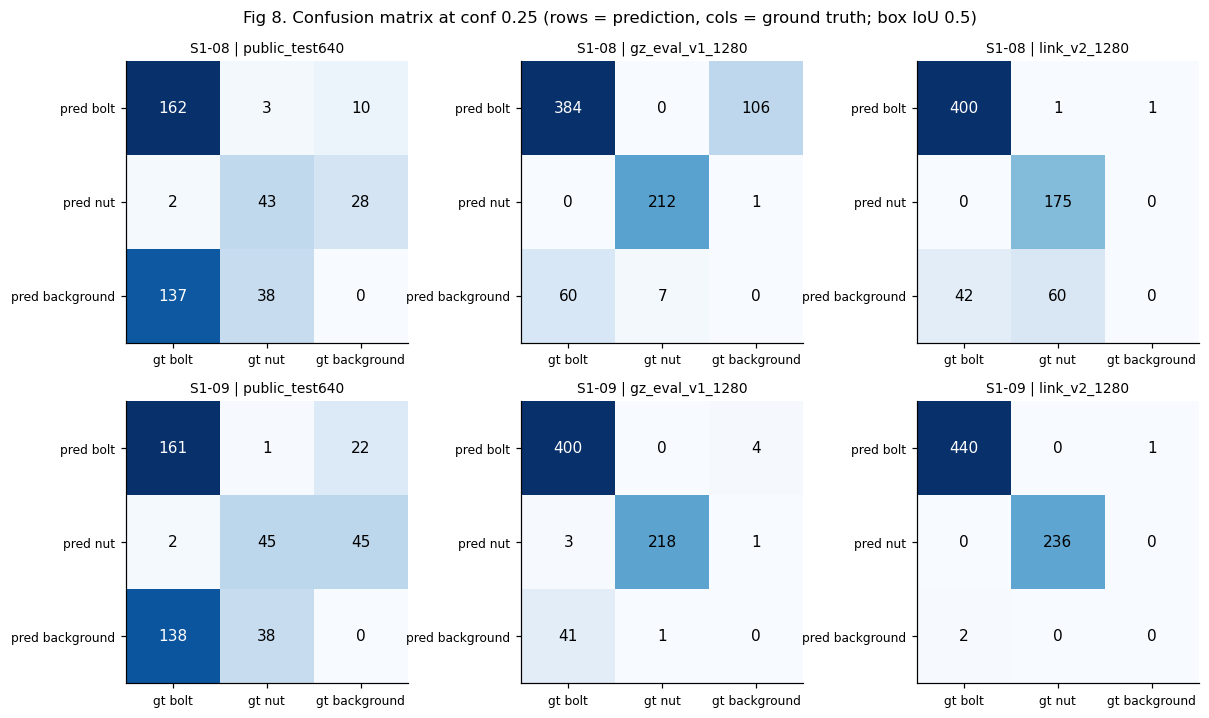

In [32]:
# 그림 8: 혼동 행렬(conf 0.25, 박스 IoU 0.5). 행 = 예측, 열 = 정답. S1-08·S1-09 × 공개 test·gz_eval_v1 1280·링크 v2.
CM_SETS = ["public_test640", "gz_eval_v1_1280", "link_v2_1280"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for i, e in enumerate(("S1-08", "S1-09")):
    for j, s in enumerate(CM_SETS):
        r = EV[f"{e}|{s}"]
        m = pd.DataFrame(r["confusion_0.25"], index=[f"pred {x}" for x in r["cm_labels"]], columns=[f"gt {x}" for x in r["cm_labels"]])
        ax = axes[i, j]
        ax.imshow(m.values, cmap="Blues")
        for (a, b), v in pd.DataFrame(m.values).stack().items():
            ax.text(b, a, int(v), ha="center", va="center", fontsize=10,
                    color="white" if v > m.values.max() * 0.6 else "black")
        ax.set_xticks(range(3), m.columns, fontsize=8)
        ax.set_yticks(range(3), m.index, fontsize=8)
        ax.grid(False)
        ax.set_title(f"{e} | {s}", fontsize=9)
fig.suptitle("Fig 8. Confusion matrix at conf 0.25 (rows = prediction, cols = ground truth; box IoU 0.5)")
fig.tight_layout()


# 표: 모든 실험·세트의 혼동 행렬(conf 0.25·0.05)을 한 줄로 편다.
def cm_rows():
    rows = []
    for r in EV.values():
        for c in ("0.25", "0.05"):
            m = r[f"confusion_{c}"]
            rows.append({"실험": r["exp"], "세트": r["set"], "conf": float(c),
                         "볼트 맞음": m[0][0], "볼트→너트": m[1][0], "볼트 놓침": m[2][0],
                         "너트 맞음": m[1][1], "너트→볼트": m[0][1], "너트 놓침": m[2][1],
                         "배경→볼트(오검출)": m[0][2], "배경→너트(오검출)": m[1][2]})
    return pd.DataFrame(rows)


CM_TABLE = cm_rows()
display(CM_TABLE[CM_TABLE.conf == 0.25].drop(columns="conf").set_index(["실험", "세트"]))
display(CM_TABLE[CM_TABLE.conf == 0.05].drop(columns="conf").set_index(["실험", "세트"]))

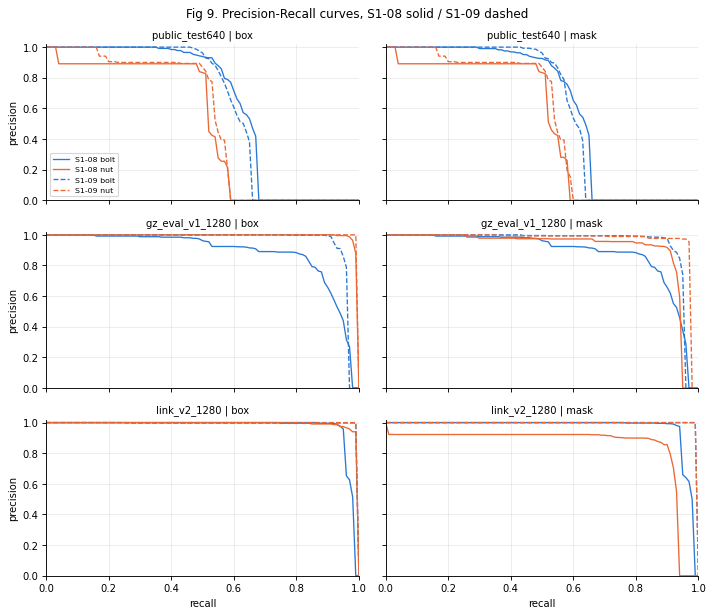

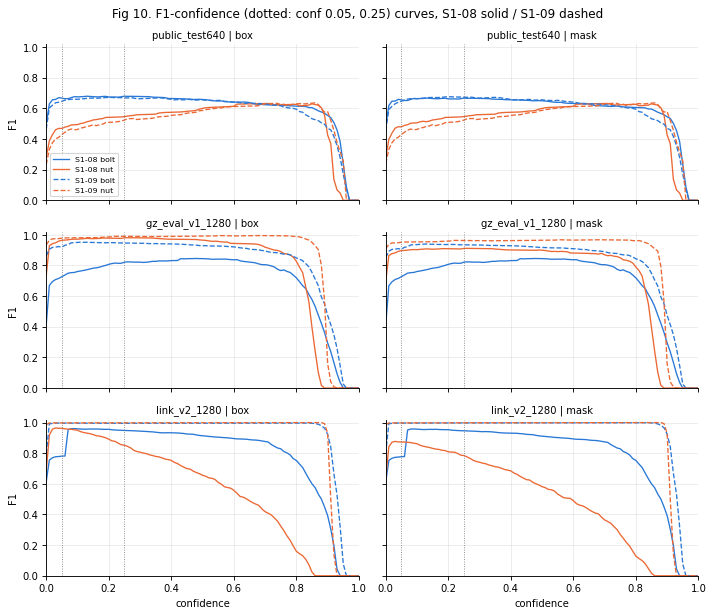

In [33]:
# 그림 9: PR 곡선, 그림 10: F1–conf 곡선. S1-08(실선)·S1-09(점선), 볼트 파랑·너트 주황. 열 = 박스·마스크.
CURV = load_json("docs/reports/data/s1_eval_curves_s1_08_09.json")
PR_SETS = ["public_test640", "gz_eval_v1_1280", "link_v2_1280"]
for kind, fig_no, xl, yl in (("PR", 9, "recall", "precision"), ("F1_conf", 10, "confidence", "F1")):
    fig, axes = plt.subplots(len(PR_SETS), 2, figsize=(9, 2.6 * len(PR_SETS)), sharex=True, sharey=True, dpi=80)
    for i, s in enumerate(PR_SETS):
        for j, bm in enumerate(("box", "mask")):
            ax = axes[i, j]
            for e, ls in (("S1-08", "-"), ("S1-09", "--")):
                cv = CURV[f"{e}|{s}"][bm][kind]
                for cls, col in (("bolt", C1), ("nut", C2)):
                    ax.plot(cv["x"], cv["by_class"][cls], color=col, ls=ls, lw=1.2, label=f"{e} {cls}")
            if kind == "F1_conf":
                for c in (0.05, 0.25):
                    ax.axvline(c, color="gray", lw=0.8, ls=":")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.02)
            ax.set_title(f"{s} | {bm}", fontsize=9)
            if i == len(PR_SETS) - 1:
                ax.set_xlabel(xl)
            if j == 0:
                ax.set_ylabel(yl)
    axes[0, 0].legend(fontsize=7, loc="lower left")
    fig.suptitle(f"Fig {fig_no}. {'Precision-Recall' if kind == 'PR' else 'F1-confidence (dotted: conf 0.05, 0.25)'} curves, S1-08 solid / S1-09 dashed")
    fig.tight_layout()

**S1-10a·b·c 평가지표(같은 조건, 같은 도구의 사본)**

- 값은 #348·#350·#353에서 §7.8과 같은 조건으로 낸 것을 `s1_eval_metrics.json`에 더했습니다(위 표들에 S1-10a·b·c 행이 함께 나옵니다). PR·F1 곡선은 `s1_eval_curves_s1_10.json`입니다.
- 아래 표는 세트별 전체(볼트·너트 평균) 지표를 S1-08·S1-09와 나란히 놓은 것입니다. 형식은 「P / R / F1 / mAP50 / mAP50-95」입니다.

In [34]:
# 표: S1-08·S1-09·S1-10a·b·c, 세트별 전체 지표(P / R / F1 / mAP50 / mAP50-95). 박스·마스크.
CMP = ["S1-08", "S1-09"] + S10
t = DETAIL[(DETAIL["클래스"] == "all") & DETAIL["실험"].isin(CMP)].copy()
t["값"] = t.apply(lambda r: f'{r["P"]:.3f} / {r["R"]:.3f} / {r["F1"]:.3f} / {r["mAP50"]:.3f} / {r["mAP50-95"]:.3f}', axis=1)
for bm in ("box", "mask"):
    print(f"[{bm}] P / R / F1 / mAP50 / mAP50-95")
    display(t[t["종류"] == bm].pivot(index="실험", columns="세트", values="값").loc[CMP, SETS])

# 표: 운영 conf(0.25·0.05)에서 S1-10a·b·c의 볼트·너트 재현율과 정밀도(박스). 링크 v2·gz_eval_v1 1280.
rows = []
for r in EV.values():
    if r["exp"] not in CMP or r["set"] not in ("gz_eval_v1_1280", "link_v2_1280"):
        continue
    for c in ("0.25", "0.05"):
        for cls, m in r["box"][f"at_conf_{c}"].items():
            rows.append({"실험": r["exp"], "세트": r["set"], "conf": float(c), "클래스": cls, "P": round(m["P"], 3), "R": round(m["R"], 3)})
display(pd.DataFrame(rows).pivot_table(index=["세트", "클래스", "conf"], columns="실험", values=["P", "R"])
        .reindex(columns=CMP, level=1).round(3))

[box] P / R / F1 / mAP50 / mAP50-95


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-08,0.830 / 0.620 / 0.710 / 0.707 / 0.550,0.884 / 0.493 / 0.633 / 0.554 / 0.445,0.804 / 0.601 / 0.688 / 0.717 / 0.454,0.930 / 0.886 / 0.908 / 0.939 / 0.598,0.985 / 0.912 / 0.947 / 0.982 / 0.529
S1-09,0.923 / 0.790 / 0.851 / 0.873 / 0.764,0.880 / 0.498 / 0.636 / 0.562 / 0.463,0.948 / 0.777 / 0.854 / 0.857 / 0.523,0.987 / 0.952 / 0.969 / 0.977 / 0.669,0.999 / 0.998 / 0.998 / 0.994 / 0.925
S1-10a,0.902 / 0.645 / 0.752 / 0.741 / 0.568,0.775 / 0.544 / 0.639 / 0.573 / 0.450,0.683 / 0.647 / 0.665 / 0.590 / 0.313,0.973 / 0.914 / 0.943 / 0.969 / 0.580,0.662 / 0.909 / 0.766 / 0.863 / 0.513
S1-10b,0.875 / 0.581 / 0.698 / 0.696 / 0.535,0.788 / 0.516 / 0.624 / 0.573 / 0.450,0.805 / 0.585 / 0.678 / 0.723 / 0.411,0.913 / 0.917 / 0.915 / 0.960 / 0.621,0.807 / 0.917 / 0.859 / 0.925 / 0.625
S1-10c,0.784 / 0.614 / 0.688 / 0.662 / 0.522,0.826 / 0.496 / 0.620 / 0.551 / 0.431,0.795 / 0.668 / 0.726 / 0.750 / 0.426,0.961 / 0.924 / 0.942 / 0.966 / 0.642,0.915 / 0.916 / 0.915 / 0.976 / 0.613


[mask] P / R / F1 / mAP50 / mAP50-95


세트,train_val,public_test640,gz_eval_v1_640,gz_eval_v1_1280,link_v2_1280
실험,,,,,
S1-08,0.851 / 0.609 / 0.710 / 0.678 / 0.473,0.877 / 0.490 / 0.629 / 0.546 / 0.384,0.766 / 0.573 / 0.655 / 0.652 / 0.250,0.894 / 0.851 / 0.872 / 0.897 / 0.397,0.936 / 0.869 / 0.901 / 0.909 / 0.322
S1-09,0.921 / 0.783 / 0.846 / 0.858 / 0.582,0.845 / 0.508 / 0.635 / 0.556 / 0.403,0.862 / 0.702 / 0.774 / 0.726 / 0.258,0.968 / 0.933 / 0.950 / 0.956 / 0.455,1.000 / 0.999 / 0.999 / 0.995 / 0.673
S1-10a,0.862 / 0.609 / 0.714 / 0.693 / 0.486,0.820 / 0.513 / 0.631 / 0.558 / 0.396,0.647 / 0.617 / 0.632 / 0.551 / 0.210,0.962 / 0.904 / 0.932 / 0.956 / 0.447,0.652 / 0.896 / 0.755 / 0.852 / 0.350
S1-10b,0.840 / 0.564 / 0.675 / 0.662 / 0.460,0.784 / 0.509 / 0.618 / 0.566 / 0.391,0.777 / 0.552 / 0.645 / 0.658 / 0.250,0.899 / 0.890 / 0.894 / 0.929 / 0.436,0.808 / 0.909 / 0.855 / 0.914 / 0.417
S1-10c,0.764 / 0.589 / 0.665 / 0.629 / 0.453,0.808 / 0.488 / 0.608 / 0.527 / 0.381,0.770 / 0.647 / 0.703 / 0.710 / 0.304,0.941 / 0.904 / 0.923 / 0.931 / 0.439,0.904 / 0.907 / 0.905 / 0.963 / 0.383


P                                  R                            
실험                         S1-08  S1-09 S1-10a S1-10b S1-10c  S1-08  S1-09 S1-10a S1-10b S1-10c
세트              클래스  conf                                                                      
gz_eval_v1_1280 bolt 0.05  0.603  0.910  0.981  0.641  0.929  0.914  0.930  0.930  0.928  0.899
                     0.25  0.783  0.993  0.995  0.879  0.977  0.865  0.905  0.892  0.905  0.860
                nut  0.05  0.948  0.958  0.966  0.948  0.916  0.982  1.000  0.910  0.990  0.982
                     0.25  0.994  0.982  0.994  0.975  0.959  0.968  0.999  0.810  0.886  0.968
link_v2_1280    bolt 0.05  0.661  0.995  0.986  0.609  0.769  0.955  0.997  0.769  0.939  0.959
                     0.25  0.995  0.996  1.000  0.652  0.897  0.907  0.995  0.583  0.916  0.930
                nut  0.05  0.970  0.996  0.957  0.971  0.886  0.956  1.000  0.280  0.932  0.958
                     0.25  1.000  0.997  1.000  0.994  0.985  0.744  1.000  0.029  0.675  0.809

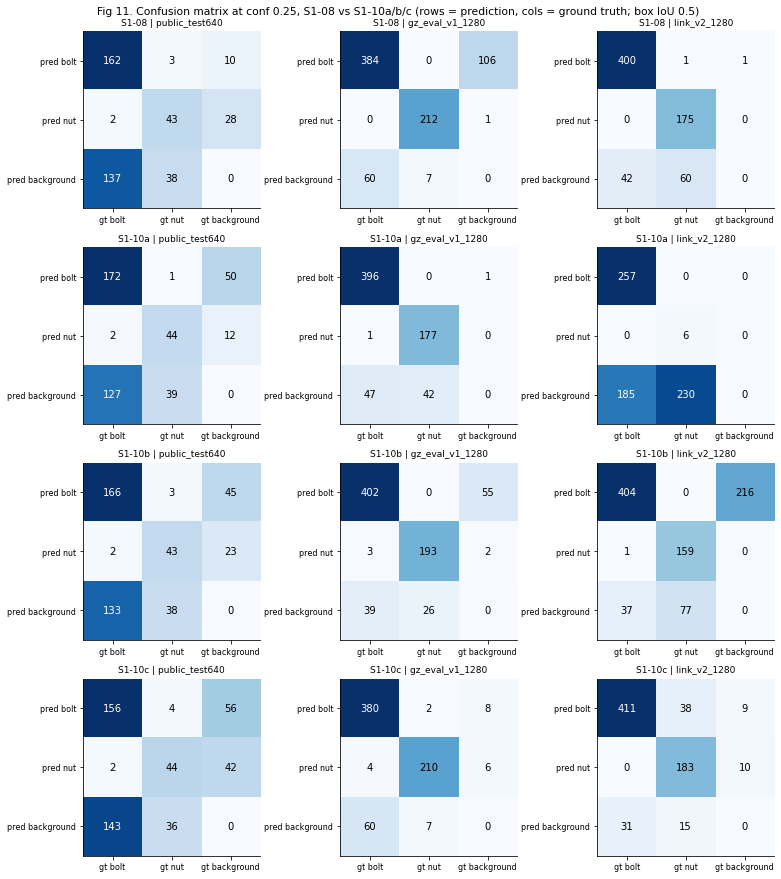

In [35]:
# 그림 11: 혼동 행렬(conf 0.25, 박스 IoU 0.5). 행 = 예측, 열 = 정답. S1-08·S1-10a·b·c × 공개 test·gz_eval_v1 1280·링크 v2.
CM_EXPS = ["S1-08"] + S10
fig, axes = plt.subplots(len(CM_EXPS), 3, figsize=(11, 3.1 * len(CM_EXPS)), dpi=72)
for i, e in enumerate(CM_EXPS):
    for j, s in enumerate(CM_SETS):
        r = EV[f"{e}|{s}"]
        m = pd.DataFrame(r["confusion_0.25"], index=[f"pred {x}" for x in r["cm_labels"]], columns=[f"gt {x}" for x in r["cm_labels"]])
        ax = axes[i, j]
        ax.imshow(m.values, cmap="Blues")
        for (a, b), v in pd.DataFrame(m.values).stack().items():
            ax.text(b, a, int(v), ha="center", va="center", fontsize=10,
                    color="white" if v > m.values.max() * 0.6 else "black")
        ax.set_xticks(range(3), m.columns, fontsize=8)
        ax.set_yticks(range(3), m.index, fontsize=8)
        ax.grid(False)
        ax.set_title(f"{e} | {s}", fontsize=9)
fig.suptitle("Fig 11. Confusion matrix at conf 0.25, S1-08 vs S1-10a/b/c (rows = prediction, cols = ground truth; box IoU 0.5)")
fig.tight_layout()

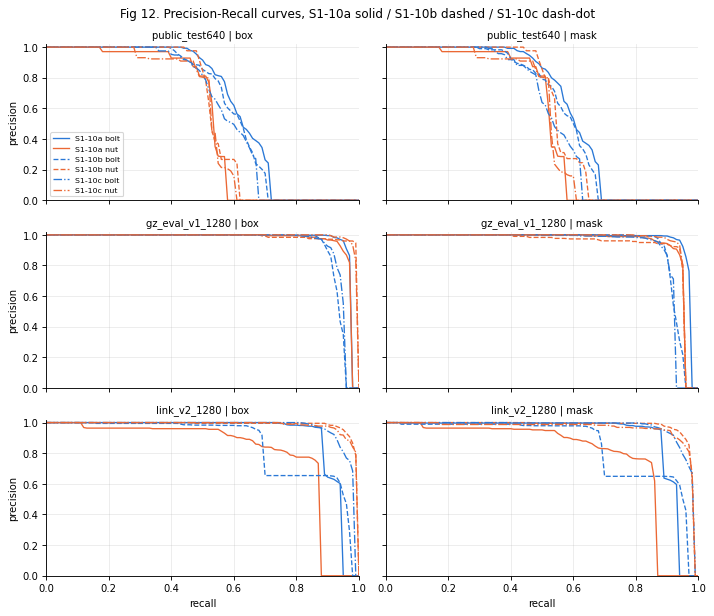

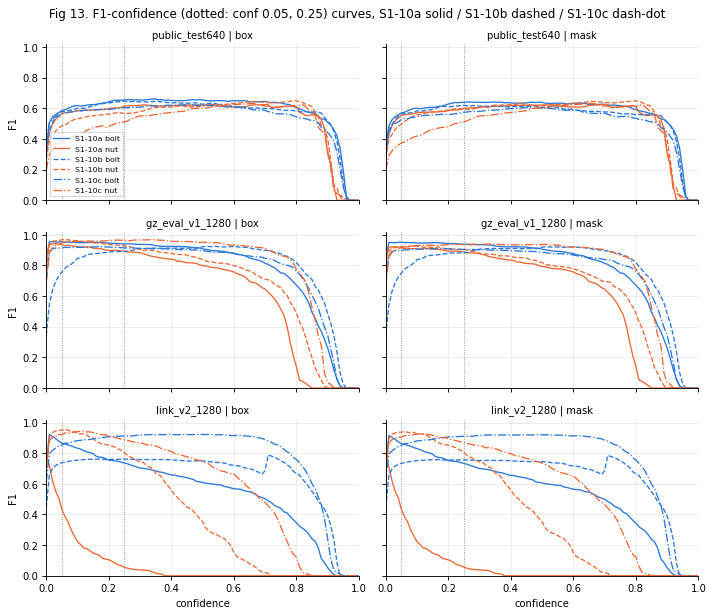

In [36]:
# 그림 12: PR 곡선, 그림 13: F1–conf 곡선. S1-10a(실선)·S1-10b(점선)·S1-10c(쇄선), 볼트 파랑·너트 주황. 열 = 박스·마스크.
CURV10 = load_json("docs/reports/data/s1_eval_curves_s1_10.json")
for kind, fig_no, xl, yl in (("PR", 12, "recall", "precision"), ("F1_conf", 13, "confidence", "F1")):
    fig, axes = plt.subplots(len(PR_SETS), 2, figsize=(9, 2.6 * len(PR_SETS)), sharex=True, sharey=True, dpi=80)
    for i, s in enumerate(PR_SETS):
        for j, bm in enumerate(("box", "mask")):
            ax = axes[i, j]
            for e, ls in zip(S10, ("-", "--", "-.")):
                cv = CURV10[f"{e}|{s}"][bm][kind]
                for cls, col in (("bolt", C1), ("nut", C2)):
                    ax.plot(cv["x"], cv["by_class"][cls], color=col, ls=ls, lw=1.2, label=f"{e} {cls}")
            if kind == "F1_conf":
                for c in (0.05, 0.25):
                    ax.axvline(c, color="gray", lw=0.8, ls=":")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.02)
            ax.set_title(f"{s} | {bm}", fontsize=9)
            if i == len(PR_SETS) - 1:
                ax.set_xlabel(xl)
            if j == 0:
                ax.set_ylabel(yl)
    axes[0, 0].legend(fontsize=7, loc="lower left")
    fig.suptitle(f"Fig {fig_no}. {'Precision-Recall' if kind == 'PR' else 'F1-confidence (dotted: conf 0.05, 0.25)'} curves, S1-10a solid / S1-10b dashed / S1-10c dash-dot")
    fig.tight_layout()

### 7.9 과적합 해석과 평가 비교의 주의점

**S1-09: 곡선 기준 과적합 징후 없음**

- best.pt 에포크 46/50이고, val 손실 세 가지가 모두 마지막 에포크에 가장 낮습니다(§6.6 표, `s1_train_curves.csv`).
- 박스 mAP50은 학습 val 0.873과 같습니다. 같은 가중치를 다시 평가한 값과 학습 중 best 에포크 값이 맞습니다(§7.8 대조).
- 평가 세트에서도 학습 val보다 크게 떨어지지 않습니다. 마스크 mAP50-95는 학습 val 0.58, `gz_eval_v1` 1280 0.46, 링크 v2 0.67입니다. 볼트 오검출(배경 → 볼트, conf 0.25)은 `gz_eval_v1` 1280에서 4건, 링크 v2에서 1건입니다(§7.8 혼동 행렬).

**그래도 말할 수 없는 것: 환경 과적합**

- S1-09의 검증 조각, `gz_eval_v1`, 링크 v2, E1~E3은 모두 학습 조각과 같은 Gazebo 월드·조명·카메라·부품 모델에서 나왔습니다(생성기 `scripts/gz_eval_capture.py`·`gz_train_plan.py`).
- 그래서 「이 시뮬 장면에 맞춰진 것」(환경 과적합)은 곡선이나 이 세트들로는 가릴 수 없습니다.
- 공개 실사진 test(학습 장면과 다름)에서 S1-09는 마스크 mAP50-95 0.403입니다. S1-08은 0.384, S1-01~06은 0.60입니다. 공개 test는 desk 장면 비중이 커서, 실제 카메라 대신 쓸 수 있는 지표가 아닙니다.
- **실제 카메라·다른 조명·배경에서는 평가하지 않았습니다(§10).**

**S1-07·S1-08: val seg 손실 상승(§6.6)**

- 학습에서 뺀 장면(desk)이 검증에 남은 격차가 섞여 있어, 같은 분포의 과적합과 분리하지 못했습니다(해석, 미분리).
- 운영 S1-08의 Gazebo 성능은 `gz_eval_v1` 1280 마스크 mAP50-95 0.397, 링크 v2 0.322입니다.
- 링크 v2에서 너트 마스크 mAP50-95가 0.162로 낮습니다. conf 0.25에서 너트 놓침이 60/236입니다.

**S1-10a·b·c: 공개 val 곡선과 Gazebo 판정이 어긋남**

- S1-10b·c는 val seg 손실이 S1-08보다 더 일찍, 더 많이 오릅니다(S1-10b 에포크 13 뒤 +20.1 %). 그동안 val box 손실은 거의 그대로이고 검증 mAP는 best.pt 에포크(43·39)까지 오릅니다. 「손실은 오르는데 지표는 오르는」 S1-07·S1-08과 같은 모양이 더 커진 것입니다(§6.6).
- **desk 장면 분리(#348, 일지 E-348d):** 검증 162장을 desk 5장과 나머지 157장으로 나눠 S1-07·S1-08·S1-10b의 손실을 다시 계산했습니다. desk 5장의 seg 손실(2.40~2.70)은 나머지(3.40~4.00)보다 오히려 낮았습니다.
  - 그래서 위 「S1-07·S1-08」 항목의 「desk 격차」 해석 중 **seg 손실이 높은 것은 desk 때문이 아닙니다.** desk는 분류·박스 손실과 mAP(마스크 mAP50 0.31~0.42, 나머지 0.73~0.75)에서만 크게 나쁩니다.
  - 손실이 오르는 구간의 가중치가 남아 있지 않아(best와 마지막뿐), 「같은 분포의 과적합」인지는 여전히 결론 내지 못했습니다.
- **S1-10a는 반대입니다.** 공개 val에서는 seg 손실 상승이 없고 마스크 mAP50-95가 가장 높지만(학습 중 0.493), Gazebo 영상에서는 M3×20과 너트를 가장 많이 놓칩니다(링크 v2 conf 0.25에서 너트 맞음 6/236, §7.8 혼동 행렬).
- 따라서 공개 실사진 검증 지표는 Gazebo 영상의 작은 물체 성능을 대신하지 못합니다. S1-10 판정은 Gazebo 세트 기준(§7.1.1)으로 했습니다.

**비교할 때 주의**

- **검증 세트가 실험마다 다릅니다.** S1-01~08과 S1-10a·b·c는 공개 val 162장, S1-09는 공개 val + Gazebo 조각 450장입니다. 그래서 실험 묶음끼리 val 손실 값을 직접 비교하지 않습니다(S1-09 val 손실이 낮은 것은 쉬운 Gazebo 조각이 섞인 영향일 수 있음).
- **학습 중 지표와 우리 평가는 조건이 다릅니다.**
  - Ultralytics 학습·`model.val` 지표: conf 0.001, NMS IoU 0.7, 매칭 IoU 0.50:0.95, P·R은 최대 F1 conf에서의 값
  - 우리 평가(`eval.json`·#278): conf 0.25 또는 운영 0.05, IoU 0.5, 크기별·종류별 재현율
  - 같은 「재현율」이라도 값이 다릅니다. 예: 링크 v2 S1-08 볼트는 우리 평가 conf 0.05 425/442, 혼동 행렬(박스 IoU 0.5) 421/442입니다.
- **#347에서 새로 낸 값의 조건:**
  - S1-01~09 × 다섯 세트, `model.val`(conf 0.001, NMS IoU 0.7, batch 8, Ultralytics 8.4.211, RTX 5080). S1-10a·b·c는 #348·#350·#353에서 같은 조건으로 낸 값입니다. 혼동 행렬은 conf 0.25·0.05, 박스 IoU 0.5입니다.
  - 학습 val에서 다시 낸 박스 mAP50은 학습 중 best.pt 에포크 값과 0.001 안에서 같습니다(§7.8 대조 셀).
  - 마스크 mAP50-95는 0.004~0.015 낮습니다. 원인은 확인하지 않았습니다(마스크 해상도 처리 차이로 추정).

## 8. 채택과 운영 반영

### 8.1 S1-08 채택 근거(A 결정 2026-11-21)

- 팀원에게 이미 공유한 모델입니다.
- `gz_eval_v1`(conf 0.25)에서 후보 8개(S1-01~08) 중 볼트 재현율이 가장 높았습니다(0.87, 너트 0.97). **다만 같은 세트의 볼트 오검출도 136개로 후보 중 가장 많습니다**(S1-07은 77).
- 링크 v2(conf 0.05)에서는 반대로 S1-08의 볼트 오검출이 S1-07보다 적었습니다(11 대 34, 재현율은 같은 424/442). 세트마다 결과가 엇갈립니다.
- 링크 v2(conf 0.05)에서 볼트 425/442를 찾았습니다.
- **남은 한계(채택 기록):** `gz_eval_v1`로 골랐으므로 독립 판정 세트가 없습니다. 세운·기운 볼트 자료가 없습니다.

### 8.2 S1-09를 평가용으로 더한 이유

- S1-08은 운영 장면에서 결함이 있었습니다. 가로 M3×20 미검출(D0, #267), 상자 테두리 (700, −112) mm 고정 오검출, 팔 그림자 오검출(#262·#275).
- S1-09는 판정 기준을 모두 통과했습니다(§7.1). 다만 모델을 바꾸면 시야 보정 k·끝점 문턱을 다시 맞춰야 하고, 팀 공유도 다시 해야 합니다. 그래서 운영은 S1-08 그대로 두고, S1-09는 설정 `ai_s1_09_axis_m2_viewbias.json`으로 평가합니다(A 결정 대기).

### 8.3 시야 보정 k(C1)

경사 시점에서는 마스크가 볼트 옆면까지 덮어, 끝점 중심이 시선 방향으로 치우칩니다. C1 보정은 δ = k·s(s는 시선 방향 성분)로 한 매개변수 k를 씁니다(#206). k는 V2 장면에서 절편 없는 최소제곱·붓스트랩 2000으로 맞췄습니다. **k는 모델·볼트 모양·투영 평면에 따라 바뀝니다.**

In [37]:
# k 적합 이력. 출처: 각 행의 기록 번호(_workspace/*_report.md)
kfit = pd.DataFrame([
    ("#206", "S1-08", "둥근 머리", "공통(M6)", 0.105, 1.39, "1.35~1.43(10겹 범위)", None, "운영 적용(지금 S1-08 설정)"),
    ("#270", "S1-08", "둥근 머리", "BOLT_A M3×20", 0.102, 0.61, "0.02~1.01", 14, "종류별 형식 시험값(잠정)"),
    ("#270", "S1-08", "둥근 머리", "BOLT_B M6×40", 0.105, 1.39, "V2 재적합 1.17", None, "유지"),
    ("#293", "S1-09", "둥근 머리", "BOLT_A M3×20", 0.102, 0.63, "0.35~0.88", 30, "S1-09 설정 적용"),
    ("#293", "S1-09", "둥근 머리", "BOLT_B M6×40", 0.105, 0.48, "0.12~0.83", 32, "S1-09 설정 적용(지금도)"),
    ("#330", "S1-08", "육각", "BOLT_A M3×20", 0.102, 0.93, "0.70~1.12", 21, "참고(운영 무변)"),
    ("#330", "S1-08", "육각", "BOLT_B M6×40", 0.105, 0.63, "0.43~0.82", 40, "참고(운영 무변)"),
    ("#330", "S1-09", "육각", "BOLT_A M3×20", 0.102, 1.09, "0.90~1.26", 33, "main에 들어가지 않음"),
    ("#330", "S1-09", "육각", "BOLT_B M6×40", 0.105, -0.28, "−0.42~−0.14", 40, "음수라 설정 불가, 0.48 유지"),
    ("#334", "S1-09", "육각", "BOLT_A M3×20", 0.1027, 0.18, "−0.003~0.351", 33, "지금 S1-09 설정(60e2b0b)"),
], columns=["기록", "모델", "볼트 머리", "종류", "평면 m", "k mm", "95 % 구간", "n", "반영"])
kfit["n"] = kfit["n"].astype("Int64")
display(kfit.set_index(["기록", "모델", "종류"]).astype(object).fillna("-"))

# 지금 저장소 설정과 대조
for rel in ("config/vision/ai_s1_08_axis_m2_viewbias.json", "config/vision/ai_s1_09_axis_m2_viewbias.json"):
    vb = load_json(rel)["axis_view_bias"]
    print(rel.split("/")[-1], "→", json.dumps({k: v for k, v in vb.items() if k != "valid_for_model_id"}, ensure_ascii=False))

볼트 머리    평면 m  k mm            95 % 구간   n                    반영
기록   모델    종류                                                                            
#206 S1-08 공통(M6)        둥근 머리  0.1050  1.39  1.35~1.43(10겹 범위)   -    운영 적용(지금 S1-08 설정)
#270 S1-08 BOLT_A M3×20  둥근 머리  0.1020  0.61          0.02~1.01  14        종류별 형식 시험값(잠정)
           BOLT_B M6×40  둥근 머리  0.1050  1.39        V2 재적합 1.17   -                    유지
#293 S1-09 BOLT_A M3×20  둥근 머리  0.1020  0.63          0.35~0.88  30           S1-09 설정 적용
           BOLT_B M6×40  둥근 머리  0.1050  0.48          0.12~0.83  32      S1-09 설정 적용(지금도)
#330 S1-08 BOLT_A M3×20     육각  0.1020  0.93          0.70~1.12  21             참고(운영 무변)
           BOLT_B M6×40     육각  0.1050  0.63          0.43~0.82  40             참고(운영 무변)
     S1-09 BOLT_A M3×20     육각  0.1020  1.09          0.90~1.26  33         main에 들어가지 않음
           BOLT_B M6×40     육각  0.1050 -0.28        −0.42~−0.14  40    음수라 설정 불가, 0.48 유지
#334 S1-09 BOLT_A M3×20     육각  0.1027  0.18       −0.003~0.351  33  지금 S1-09 설정(60e2b0b)

ai_s1_08_axis_m2_viewbias.json → {"model": "C1", "k_mm": 1.39, "plane_z_m": 0.105}
ai_s1_09_axis_m2_viewbias.json → {"model": "C1", "by_spec": {"BOLT_A": {"label": "M3x20", "k_mm": 0.18, "fit_plane_z_m": 0.1027}, "BOLT_B": {"label": "M6x40", "k_mm": 0.48, "fit_plane_z_m": 0.105}}}


- 평면 0.1027 m는 B 규격의 육각 M3×20 놓인 높이입니다(B-14). 이 평면만으로 S1-09 M3 중심 오차 p50이 0.84~0.91 → 0.53~0.59 mm로 줄었습니다(#334). k가 맡던 몫을 평면 변경이 가져가 k가 0.18로 작아졌고, 구간이 0을 포함합니다.
- 시작할 때 S1-09 설정의 `fit_plane_z_m`을 B 규격 `plane_z`와 대조합니다(허용 0.5 mm). 어긋나면 실행을 시작하지 않습니다.
- **S1-08 운영 설정은 이 대조를 하지 않습니다.** 평면 0.105 m 하나라 육각 M3×20(0.1027 m)에 2.3 mm 높은 평면을 씁니다. 영향은 재지 않았습니다(§10).

### 8.4 끝점·축 추출(M1 → M2)

분할 마스크에서 볼트 머리 끝·축 끝 두 점을 뽑아 B에 넘깁니다. 이 단계가 B 후보 수를 가장 크게 좌우했습니다.

| 단계 | 내용 | 결과 | 일지 |
|---|---|---|---|
| 규칙 K·X1 | 마스크 극값으로 끝점(S1-08) | 개발 유효 176/215·197/222. 머리 오차 중앙값 3.92~6.61 px. 앞선 실행 2회는 도구 문제로 무효 | E-159g, E-162 |
| M1 | 축 순서·머리 판별 규칙 | 유효 216개, 「부적합」 판정. I1은 140개로 더 나쁨 | E-163a·b, E-164a·b |
| M1 실시간 | 단일 볼트 150프레임 | **150/150 `AXIS_ORDER_INCONSISTENT`**(오프라인은 통과) | E-175 |
| M1 보완 C1 | 계단 정의 수정 | 모의 유효 22/42 → 42/42 | E-176b |
| P7 → **M2** | 새 끝점 규칙(오프라인) | 링크 v2 B 후보 정답 볼트 172 → 409/442(38.9 → 92.5 %), 후보 0 장면 61 → 1/175 | E-223 |
| M2 제품 구현 | | 975개 인스턴스가 P7 판정과 일치 | E-225 |
| M2 실시간 | 벨트 장면 | 끝점 통과율 9.9 → 57.6 %, W 첫 확정 SIM 9.6 → 2.58 s. 대신 「여러 물체」 무효 증가 | E-227 |
| 근접 그리퍼 RGB | S1-08 + M2를 그리퍼 카메라에 | 대상 검출 21/84, M2 유효 7 → **쓸 수 없음.** 깊이 측정은 xy 최대 0.89 mm로 쓸 수 있음 | E-255 |

- 실패·무효 실행: #163 첫 실행(접근 검사기 결함), #164 1차(경로 오류), #221 tandem 겹침 폐기, #227 `KW1b_p`(작업 트리에 M2가 없어 무효)

### 8.5 OpenCV 기준선 비교

- 계획서는 AI를 OpenCV 기준선과 같은 조건으로 비교해 채택하기로 했습니다(§2). **같은 조건의 검출 성능 비교는 끝내지 못했고, A 결정(2026-11-21)으로 채택 조건에서 빠졌습니다.**
- 남은 비교 자료
  - **처리 시간(#114, E-114a·b):** OpenCV 중앙값 2.27 ms·최댓값 48.96 ms(상한 없음), GPU YOLO 중앙값 5.87~9.08 ms
  - **초록 벨트 장면(#159 X2, E-159d):** OpenCV 기본 설정은 볼트를 하나도 찾지 못했습니다(892/892 누락). 매 영상 같은 배경 윤곽 5~7개만 냈습니다. 설정을 이 장면에 맞추지 않았으므로, **이 0검출을 AI 우위의 근거로 쓰지 않습니다**(결정 패키지). 첫 실행은 감시 빈틈으로 폐기했습니다.
  - **비실시간 S1(#249, E-249a):** OpenCV는 20장에서 프레임당 후보 5개를 냈지만 모두 보정 불일치였고, 무엇을 잡았는지는 확인하지 않았습니다.
  - 분류 시험 비교 도구(#186)는 준비만 했습니다(E-186).

### 8.6 오검출 제외와 추적

| 대상 | 방법 | 결과 | 일지 |
|---|---|---|---|
| 그리퍼 손가락 | 원인 확인 | 확정 오검출이 그리퍼 자체(conf 0.27~0.73) | E-260a |
| 팔·그리퍼 투영 영역 | ArmRegionFilter | 그리퍼 집기 목표 114 → 0~3. 1차는 Hz 저하·진짜 목표 감소로 기준 미충족, 벡터화 뒤 회복 | E-262a·b |
| 벨트 밖 | 벨트 사각형 + 여유 10 mm | 재생에서 벨트 위 오제외 0/4,691, 바닥·상자 1,008/1,008 제외 | E-288 |
| 같은 볼트 2중 검출 | 마스크 포함률로 합침 | 66실행 무효 7,735 → 7,537 해소, 다른 부품 합침 0 | E-292a·b |
| 추적기 | YOLO 내장 추적기 대 A 추적기 | 프레임 30 % 누락 때 YOLO 번호 4.8~11.4개로 갈라짐 → 채택 안 함 | E-218a~c |
| S1-09 틈 너머 가로대 | 정체 조사 | 벨트·레일 사이 10 mm 틈 너머 가로대(74 %). B 목록 후보 12회, 모두 길이로 거부 | E-295a |

## 9. 육각 볼트 전환 영향(#323)

볼트 모델을 둥근 머리에서 ISO 4017 육각 머리로 바꿨습니다(A 결정 2026-11-23). 둥근 머리가 DART 벨트 위에서 원뿔처럼 굴러 떨어졌고(#317), 감쇠·구름 마찰은 DART에서 쓸 수 없었습니다(#319). **재학습은 하지 않았습니다.**

In [38]:
# #323 같은 40장면(위치 5 × yaw 8) 비교. 출처: _workspace/323_builder_report.md §0·§3
hexcmp = pd.DataFrame([
    ("S1-09", "M3×20 끝점 유효", "31/33", "33/33"),
    ("S1-08", "M3×20 끝점 유효", "15/33", "21/33"),
], columns=["모델", "지표", "둥근 머리", "육각 머리"]).set_index(["모델", "지표"])
display(hexcmp)
print("물리(#323): 벨트 수송 70 s에서 M3·M6 구름 0°, 낙하 없음(둥근 머리 M3는 8,424° 굴러 32 s에 낙하).")
print("B 영향(#323): 전체 길이 46 → 44 mm로 M6 끝점이 B 하한 39 mm 아래인 경우 80건 중 5건 → B-14로 하한 36 mm.")

,,둥근 머리,육각 머리
모델,지표,,
S1-09,M3×20 끝점 유효,31/33,33/33
S1-08,M3×20 끝점 유효,15/33,21/33


물리(#323): 벨트 수송 70 s에서 M3·M6 구름 0°, 낙하 없음(둥근 머리 M3는 8,424° 굴러 32 s에 낙하).
B 영향(#323): 전체 길이 46 → 44 mm로 M6 끝점이 B 하한 39 mm 아래인 경우 80건 중 5건 → B-14로 하한 36 mm.


- 시야 안의 M3×20 끝점은 두 모델 모두 같거나 늘었습니다. 시야 밖 7장면은 분모에서 뺐습니다.
- k는 육각에서 다시 맞췄습니다(§8.3, #330·#334).

## 10. 한계와 후속

**S1-09 가로 치우침(#329~#334)**

- S1-09의 A 중심은 정답보다 그리퍼가 닫는 방향으로 늘 +0.14~+0.70 mm 치우칩니다(6/6). S1-08은 −0.80~+0.15 mm로 흩어집니다(#329).
- **#329 당시 가설:** 닫힐 때 볼트가 그만큼 밀리고 축을 따라 구르며 빠진다. 1 mm 기준 아래지만 그때 비교한 실행에서 M3 집기 결과와 맞는 유일한 차이였습니다.
- **#326에서 반박됨:** 정답 위치로 목표를 준 sim 모드에서도 S1-08·S1-09 모두 M3 놓기에 실패했습니다(`BIN_ARRIVAL_UNCONFIRMED`, M3 실패 7건 중 6건이 손이 열려도 육각 M3가 손가락에 붙는 놓기 실패). S1-08도 붙었다가 나중에 떨어졌을 뿐입니다. 그래서 **M3 실패의 주원인은 그리퍼 놓기 실패(손끝 마찰·크리프, C 쪽)**이고, 가로 치우침은 **부원인 후보**입니다(`_workspace/326_builder3_report.md` §2.1).
- k 재적합(#330)과 새 평면(#334)으로도 yaw 0° 장면의 가로 치우침이 +0.45~+0.54 mm 남습니다. 시선 방향에 비례하는 치우침이 아니라, 마스크 비대칭·육각 기울기 3.6° 같은 다른 원인으로 봅니다(해석, 미분석).

**가로 M3×20을 실사진만으로는 풀지 못함(S1-10, #348~#353)**

- 운영 모델 S1-08은 가로로 놓인 M3×20을 거의 찾지 못합니다(재촬영 15장 중 1장). 이 한계는 그대로 남아 있습니다.
- 실사진만 쓴 세 실험은 모두 미리 정한 기준에 못 미쳤습니다. 회전 사본(S1-10b)은 가로 M3×20을 찾지만 상자 벽 테두리를 볼트로 보고, 무작위 회전(S1-10a)은 M3×20·너트를 놓치며, 배경 조각을 더한 S1-10c는 상자 벽은 없앴지만 가로 M3×20이 다시 떨어졌습니다(§6.5.1, §7.1.1).
- 세 실험 모두 seed 0 한 번이고, 1단계 불합격이라 실시간 시험은 하지 않았습니다. 원인 가르기(다른 seed, 조각 수 조절)와 추가 학습은 보류 중입니다.
- 가로 M3×20을 찾는 후보는 지금 Gazebo 조각으로 학습한 S1-09뿐이고, 교체 여부는 A 결정 대기입니다(§8.2).

**실제 영상 미평가**

- 공개 실사진(점검용)과 Gazebo 영상만 평가했습니다. 실제 카메라·조명·볼트 표면에서의 검출·끝점 정확도는 측정하지 않았습니다(계획서 §10.1의 실제 영상 평가 미수행).
- Gazebo 라벨은 보이는 실루엣 전체이고, 윗면 라벨이 아닙니다.

**그 밖의 남은 위험**

- 컨베이어 틈 너머 가로대 오검출(S1-09만, #295 R1). #295 때는 B 길이 거부(35.4~36.7 mm < 하한 39 mm)로 목표가 0건이었습니다. **B-14로 BOLT_B 하한이 36 mm로 내려가, 그때 길이 중 36.0~36.7 mm는 이제 범위 안입니다.** 지금 규격에서 다시 재지 않았습니다(미확인, 확인 필요).
- 잡는 중 그리퍼 밖으로 나온 M3×20이 팔 영역 캡슐에 걸려 제외됩니다(#295 R2, A 결정 대기).
- 세운·기운 볼트 자료가 없습니다.
- **S1-08 운영 설정의 투영 평면(측정 전, 확인 필요):** S1-08 설정은 시야 보정 평면이 0.105 m 하나입니다(시작 대조 검사 없음). B-14 뒤 육각 M3×20은 실제 0.1027 m에 놓이므로, A 끝점을 2.3 mm 높은 평면으로 투영해 M3 좌표에 계통 오차가 생길 수 있습니다. 크기는 재지 않았습니다(S1-09에서는 평면만 바꿔도 중심 p50이 0.84~0.91 → 0.53~0.59 mm로 줄었음, #334).

**재학습 조건(제안, A 결정 필요)**

- 실제 카메라로 바꿀 때: 실제 영상 평가 세트를 먼저 만들고, 기준 미달이면 실제 영상을 더해 재학습합니다.
- 부품·배경이 바뀔 때: 새 볼트 규격, 벨트·상자 질감·배치가 바뀌면 §7.1의 합격 기준 항목(가로 M3×20 검출 D0, 오검출)을 다시 잽니다. 이번 육각 전환처럼 기준을 계속 넘으면 재학습하지 않습니다.
- 모델을 바꾸면 시야 보정 k·끝점 문턱을 다시 맞추고 모델 카드·설정 해시를 갱신합니다(#275 §7).

**사람 자세 모델(4~5주차)**

- 계획서 §2.7: 사전학습 자세 모델(후보 MediaPipe Pose Landmarker) 추론으로 관절점을 얻습니다. 추가 학습은 필수가 아닙니다. 이 보고서 범위 밖이며 아직 시작하지 않았습니다.

## 11. 출처

**저장소 파일(이 노트북이 읽는 것)**

- 모델 카드: `models/vision/s1_08/MODEL_CARD.json`(커밋 `7db4382`), `models/vision/s1_09/MODEL_CARD.json`(`a612378`)
- 분할 manifest·목록: `data/splits/{resplit_v1,resplit_v2,clean_train_r1,gz_r1}/`(gz_r1 `47df9ea`), S1-10용 `data/splits/{clean_rot90_r1,clean_rot90_bg_r1}/`(`9a11fa8`·`cbae333`)
- 학습 설정: `config/training/*.json`(S1-10a·b `9a11fa8`, S1-10c `cbae333`)
- 실행 설정: `config/vision/ai_s1_08_*.json`, `config/vision/ai_s1_09_axis_m2_viewbias.json`(BOLT_A 새 평면 `60e2b0b`)
- B 규격(읽기만): `config/calibration/part_specs.json`
- 도구: `scripts/coco_to_yolo_seg.py`, `resplit_dataset.py`, `prepare_clean_train_r1.py`, `gz_eval_scene.py`, `gz_eval_capture.py`, `gz_train_plan.py`, `train_candidates.py`, `eval_size_recall.py`
- 설계: 계획서 `docs/architecture/시스템_아키텍처_및_프로젝트_계획.md` §2·§10, A 상세 `docs/design/A담당_비전_상세설계.md` §6.1·§7.1~§7.4·§12, 결과서 `docs/design/A담당_통합시험_결과.md` §10.5, 공개 자료 안내 `data/raw/README.md`

**Git 제외 원자료(값을 셀에 옮김)**

- 학습 요약: `outputs/training/{s1_legacy,s1_b64,s1_clean_r1,s1_clean_hsvv06_r1,s1_gz_r1}/summary.md`, S1-10은 `outputs/training/{s1_rot_r1_a,s1_rot_r1_b_try2,s1_rot_r1_c}/`(중단된 첫 시도 `s1_rot_r1_b/`)
- 학습 곡선·평가지표(#347, 저장소에 옮김): `docs/reports/data/s1_train_curves.csv`·`s1_train_curves_sources.json`(원본 `results.csv` 경로·sha256), `s1_eval_metrics.json`·`s1_eval_curves_s1_08_09.json`(도구 `_workspace/347_k/eval_347.py`)
- S1-10 회전 실험(#386, 저장소에 옮김): `docs/reports/data/s1_10_gate.json`(판정표 원값·보조 측정, 원자료 경로·sha256), `s1_eval_curves_s1_10.json`. 학습 곡선·평가지표는 위 파일들에 S1-10a·b·c 행으로 더했습니다(옮긴 도구 `_workspace/386_k/pack_386.py`). 원자료는 `_workspace/{348,350,353}_evidence/gpu/`, `_workspace/352_evidence/lowconf/`, `_workspace/278_evidence/`(S1-08·S1-09 값)입니다.
- conf 비교: `outputs/conf_sweep/s107_s108_green_link_20261117_110321_89c80b/`, `outputs/conf_sweep/s107_s108_low_20261117_100024_305a31/`

**실험 일지 조사 원본:** `_workspace/343_k/survey_{A,B,C}.md`, `experiment_log_343.json`(Git 제외). 일지의 각 행에 기록 경로가 있습니다.

**A 작업 기록(`_workspace/`, Git 제외)**

| 번호 | 내용 |
|---|---|
| #128·#130·#131 | 라벨 점검, 수정·제외 기준, 수정 초안과 A 검수 |
| #134~#137 | WIN 행 단위 판정, WIN 파일럿 10행, WIN 사용 가능 40장, 비-WIN 검수 |
| #144 | WIN 비증강 배포본 재라벨링 준비(미실행) |
| #139·#140·#141 | 선별 자료 준비(S1-07), conf 재평가 준비, 밝기 증강(S1-08) |
| #146 | 링크 카메라 평가 자료 v2 200장 |
| #206 | 시야 보정 C1(k 1.39) |
| #219 | B 넘기기 conf 점검(conf 0.05 경위 미확인) |
| #262·#267 | 실시간 오검출, V2 촬영(D0 발견) |
| #270 | 종류별 투영 높이·시야 보정 |
| #275·#278 | 재학습 계획·판정 기준, S1-09 학습·판정 |
| #293·#295 | S1-08/S1-09 짝 비교, 남은 위험 |
| #317·#319·#323 | 둥근 머리 구름, 육각 전환 |
| #326 | 육각 볼트 재시험(처리 시간) |
| #329·#330·#334 | S1-09 가로 치우침, k 재적합, 새 평면 |
| #348·#350·#352·#353 | S1-10 회전 실험: 회전 사본(b), 무작위 회전(a), 낮은 신뢰도 추론, 배경 조각(c) |
| #386 | S1-10을 이 보고서에 반영, §6.6 best 에포크를 실제 저장된 best.pt 기준으로 수정 |

In [39]:
# 출처 파일 존재 확인(저장소 파일만).
paths = ["models/vision/s1_08/MODEL_CARD.json", "models/vision/s1_09/MODEL_CARD.json",
         "data/splits/resplit_v1/manifest.json", "data/splits/resplit_v2/manifest.json",
         "data/splits/clean_train_r1/manifest.json", "data/splits/gz_r1/manifest.json",
         "config/training/s1_eval.json", "config/vision/ai_s1_08_axis_m2_viewbias.json",
         "config/vision/ai_s1_09_axis_m2_viewbias.json", "config/calibration/part_specs.json",
         "data/raw/README.md", "docs/design/A담당_비전_상세설계.md",
         "config/training/s1_rot_r1_a_common.json", "config/training/s1_rot_r1_b_common.json",
         "config/training/s1_rot_r1_c_common.json", "data/splits/clean_rot90_r1/manifest.json",
         "data/splits/clean_rot90_bg_r1/manifest.json", "docs/reports/data/s1_10_gate.json",
         "docs/reports/data/s1_eval_curves_s1_10.json"]
missing = [p for p in paths if not (ROOT / p).is_file()]
print(f"출처 파일 {len(paths)}개 중 없음 {len(missing)}개", missing or "")

출처 파일 19개 중 없음 0개 
